In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
one_point_countries = pd.read_parquet('../data/one_point_countries.parquet')

In [3]:
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR


### Search outliers
* Look for outliers
* Plot boxplot for every feature

In [4]:
def detect_outliers_in_dataframe(df, iqr_multiplier=1.5):
    outlier_report = {}

    # Excluye columnas no numéricas
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    for idx, row in df.iterrows():
        country_name = row["Country"]
        outlier_cols = []

        for col in numeric_cols:
            value = row[col]
            col_series = df[col].dropna()

            # Calcula los límites usando IQR
            q1 = np.percentile(col_series, 25)
            q3 = np.percentile(col_series, 75)
            iqr = q3 - q1
            lower_bound = q1 - iqr_multiplier * iqr
            upper_bound = q3 + iqr_multiplier * iqr

            if value < lower_bound or value > upper_bound:
                outlier_cols.append(col)

        outlier_report[country_name] = outlier_cols

    return outlier_report


In [5]:
outliers = detect_outliers_in_dataframe(one_point_countries)


In [6]:
def outlier_dict_to_df(outlier_dict):
    data = [{"Country": country, "Outlier_Count": len(cols)} for country, cols in outlier_dict.items()]
    return pd.DataFrame(data)

In [7]:
from collections import Counter

In [8]:
def rank_outlier_variables(outlier_dict, exclude_columns={"Year"}):
    counter = Counter()
    for macro_list in outlier_dict.values():
        filtered_macros = [col for col in macro_list if col not in exclude_columns]
        counter.update(filtered_macros)

    sorted_macros = sorted(counter.items(), key=lambda x: x[1], reverse=True)

    print("📊 Ranking de macroeconómicos con outliers (por número de países):\n")
    for macro, count in sorted_macros:
        print(f"{macro}: {count} países")

In [9]:
rank_outlier_variables(outliers)

📊 Ranking de macroeconómicos con outliers (por número de países):

cpi_min: 17 países
govermment_effective__cv: 16 países
rule_of_law__cv: 13 países
cpi_median: 12 países
investment_median: 12 países
investment_min: 12 países
gdp_median: 12 países
gdp_min: 12 países
investment_mean: 11 países
investment_std: 11 países
investment_max: 11 países
investment_last: 11 países
gdp_max: 11 países
gdp_last: 11 países
gov_exp_std: 10 países
gov_exp_trend: 10 países
investment_trend: 10 países
gdp_mean: 10 países
gdp_std: 10 países
gdp_trend: 10 países
cpi_mean: 9 países
govermment_effective__growth: 9 países
gov_exp_mean: 9 países
gov_exp_median: 9 países
gov_exp_min: 9 países
gov_exp_max: 9 países
gov_exp_last: 9 países
priv_cred_mean: 9 países
priv_cred_median: 9 países
priv_cred_std: 9 países
priv_cred_min: 9 países
priv_cred_max: 9 países
priv_cred_last: 9 países
priv_cred_trend: 9 países
urban_pop_kurtosis: 9 países
labor_force_trend: 8 países
agr_land_growth: 8 países
inflation__growth: 8 

In [10]:
def pareto_variables_with_countries(outlier_dict, threshold=0.8, exclude_columns={"Year"}):
    from collections import Counter, defaultdict
    import pandas as pd

    # Paso 1: contar ocurrencias por variable
    counter = Counter()
    variable_to_countries = defaultdict(list)

    for country, macro_list in outlier_dict.items():
        for var in macro_list:
            if var not in exclude_columns:
                counter[var] += 1
                variable_to_countries[var].append(country)

    # Paso 2: crear DataFrame ordenado por frecuencia
    df = pd.DataFrame(counter.items(), columns=["Variable", "Outlier_Count"])
    df = df.sort_values(by="Outlier_Count", ascending=False).reset_index(drop=True)

    # Paso 3: aplicar regla de Pareto
    total_outliers = df["Outlier_Count"].sum()
    df["Cumulative_Outliers"] = df["Outlier_Count"].cumsum()
    df["Cumulative_%"] = df["Cumulative_Outliers"] / total_outliers

    pareto_df = df[df["Cumulative_%"] <= threshold].copy()

    if not pareto_df.empty and pareto_df["Cumulative_%"].iloc[-1] < threshold:
        next_row = df.iloc[len(pareto_df)]
        pareto_df = pd.concat([pareto_df, next_row.to_frame().T], ignore_index=True)

    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce") * 100
    pareto_df["Cumulative_%"] = pareto_df["Cumulative_%"].round(2)

    # Paso 4: agregar países responsables
    pareto_df["Countries"] = pareto_df["Variable"].apply(lambda var: variable_to_countries[var])

    return pareto_df

In [11]:
pareto_result = pareto_variables_with_countries(outliers, threshold=0.8)

In [12]:
pareto_result

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%,Countries
0,cpi_min,17,17,2.28,"[Australia, Brazil, Canada, Chile, Colombia, I..."
1,govermment_effective__cv,16,33,4.44,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
2,rule_of_law__cv,13,46,6.18,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
3,cpi_median,12,58,7.80,"[Brazil, Canada, Chile, India, Israel, Malaysi..."
4,investment_min,12,70,9.41,"[Chile, Colombia, Hungary, India, Japan, Mexic..."
...,...,...,...,...,...
75,priv_cred_growth,4,583,78.36,"[Cyprus, India, Philippines, Turkey]"
76,gov_exp_skew,4,587,78.90,"[Croatia, Israel, Thailand, Turkey]"
77,reserves_median,4,591,79.44,"[Czech, India, Japan, Thailand]"
78,agr_land_skew,3,594,79.84,"[Belgium, Estonia, Malaysia]"


In [13]:
def extract_unique_countries(pareto_df, column_name="Countries"):
    all_countries = []

    for country_list in pareto_df[column_name]:
        all_countries.extend(country_list)

    unique_countries = sorted(set(all_countries))
    return unique_countries

In [14]:
unique_countries = extract_unique_countries(pareto_result)

In [15]:
unique_countries

['Australia',
 'Belgium',
 'Brazil',
 'Bulgaria',
 'Canada',
 'Chile',
 'Colombia',
 'Croatia',
 'Cyprus',
 'Czech',
 'Denmark',
 'Estonia',
 'France',
 'Germany',
 'Greece',
 'Hungary',
 'Iceland',
 'India',
 'Ireland',
 'Israel',
 'Japan',
 'Latvia',
 'Lithuania',
 'Luxembourg',
 'Malaysia',
 'Malta',
 'Mexico',
 'Netherlands',
 'New Zealand',
 'Norway',
 'Paraguay',
 'Peru',
 'Philippines',
 'Poland',
 'Portugal',
 'Romania',
 'Russia',
 'Serbia',
 'Singapore',
 'Slovakia',
 'Slovenia',
 'South Africa',
 'South Korea',
 'Spain',
 'Sweden',
 'Switzerland',
 'Thailand',
 'Turkey',
 'USA']

In [16]:
len(unique_countries)

49

* Make no sense, we have 53 countries and with this idea we want to eliminate 49
* So apply winsorization, robust scaler and log transformation one time and see the countries that are responsables for the 80% of the remaining outliers

### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [17]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [18]:
df_log_transf = adaptive_log_transform(one_point_countries)

Applied log1p transformation to column: labor_force_mean
Applied log1p transformation to column: labor_force_median
Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_min
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: labor_force_last
Applied log transformation to column: livestock_prod_mean
Applied log transformation to column: livestock_prod_median
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: livestock_prod_cv
Applied log transformation to column: livestock_prod_min
Applied log transformation to column: livestock_prod_max
Applied log transformation to column: livestock_prod_last
Applied log transformation to column: urban_pop_mean
Applied log transformation to column: urban_pop_median
Applied log transformation to column: urban_pop_min
Applied log transformation to column: urban_pop_max
Applied log transformation to column: ur

In [19]:
from sklearn.preprocessing import RobustScaler

In [20]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [21]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_countries, df_log_transf)

Applied RobustScaler to columns: ['labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_growth', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_skew', 'investment_kurtosis', 'cpi_growth', 'cpi_skew', 'cpi_kurtosis', 'cpi_trend', 'gdp_skew', 'gdp_kurtosis', 'priv_cred_growth', 'priv_cred_skew', 'priv_cred_kurtosis', 'priv_cred_trend', 'unemployment_cv', 'unemployment_growth', 'unemployment_skew', 'unemployment_kurtosis', 'unemployment_trend', 'rule_of_law__mean', 'rule_of_law_

In [22]:
df_final = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.432566,0.422131,-4.897231e-01,0.470588,0.438596,0.444444,0.225607,-0.482700,1.086080,0.386612
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.367599,0.368852,-1.871437e-01,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.945877,0.000000
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.139803,0.118852,3.564674e-01,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.181743,-1.229508,-3.907173e+00,-1.260504,-1.157895,-1.140741,3.024576,0.688661,-0.693295,-0.592896
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-0.834704,-0.778689,-5.246984e+17,-0.991597,-0.807018,-0.696296,-0.940630,-1.268340,0.396286,-0.234973


In [23]:
from scipy.stats.mstats import winsorize

In [24]:
def winsorize_outlier_columns(df, limits=(0.05, 0.05)):
    """
    Applies winsorization only to numeric columns that contain outliers (based on IQR).

    Parameters:
    - df: pandas DataFrame
    - limits: tuple (lower_limit, upper_limit) for winsorization percentiles

    Returns:
    - df_winsorized: DataFrame with selected columns winsorized
    - outlier_columns: list of columns that were winsorized
    """
    df_winsorized = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    outlier_columns = []

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

        if not outliers.empty:
            arr = df[col].values
            arr_winsorized = winsorize(arr, limits=limits).data  # Convert to regular array
            df_winsorized[col] = arr_winsorized
            outlier_columns.append(col)

    return df_winsorized, outlier_columns

In [25]:
df_final_win1, outliers_columns = winsorize_outlier_columns(df_final, limits=(0.05,0.05))

In [26]:
df_final_win2, outliers_columns = winsorize_outlier_columns(df_final_win1, limits=(0.08,0.08))

In [27]:
df_final_win3, outliers_columns = winsorize_outlier_columns(df_final_win2, limits=(0.10,0.10))

In [34]:
df_final_win4, outliers_columns = winsorize_outlier_columns(df_final_win3, limits=(0.12,0.12))

In [35]:
df_final_win5, outliers_columns = winsorize_outlier_columns(df_final_win4, limits=(0.15,0.15))

In [42]:
df_final_win6, outliers_columns = winsorize_outlier_columns(df_final_win5, limits=(0.17,0.17))

In [49]:
outliers_after_win5 = detect_outliers_in_dataframe(df_final_win5)

In [50]:
outliers_after_win6 = detect_outliers_in_dataframe(df_final_win6)

In [51]:
pareto_after_win5 = pareto_variables_with_countries(outliers_after_win5, threshold=0.8)

In [52]:
pareto_after_win6 = pareto_variables_with_countries(outliers_after_win6, threshold=0.8)

In [53]:
pareto_after_win5

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%,Countries
0,cpi_min,17,17,24.29,"[Australia, Brazil, Canada, Chile, Colombia, I..."
1,rule_of_law__cv,10,27,38.57,"[Brazil, Bulgaria, Colombia, Mexico, Paraguay,..."
2,govermment_effective__cv,10,37,52.86,"[Brazil, Bulgaria, Colombia, Mexico, Paraguay,..."
3,priv_cred_trend,9,46,65.71,"[Chile, Colombia, Hungary, India, Japan, Parag..."
4,cpi_median,8,54,77.14,"[Brazil, Canada, India, New Zealand, Philippin..."
5,urban_pop_kurtosis,8,62,88.57,"[Cyprus, Denmark, Romania, Singapore, Slovakia..."


In [55]:
unique_countries_after_win5 = extract_unique_countries(pareto_after_win5)

In [56]:
len(unique_countries_after_win5)

28

In [57]:
unique_countries_after_win6 = extract_unique_countries(pareto_after_win6)

In [58]:
len(unique_countries_after_win6)

12

In [59]:
def remove_selected_countries_except(df, country_list, keep_country="Paraguay", column_name="Country"):
    """
    Elimina del DataFrame todos los países en 'country_list' excepto el país especificado en 'keep_country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original que contiene la columna de países.
    - country_list: list
        Lista de países que se desean eliminar (excepto uno).
    - keep_country: str
        País que se desea conservar aunque esté en la lista.
    - column_name: str
        Nombre de la columna que contiene los nombres de países.

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con los países eliminados según la lógica.
    """

    # Crear nueva lista excluyendo el país que queremos conservar
    countries_to_remove = [c for c in country_list if c != keep_country]

    # Filtrar el DataFrame
    df_filtrado = df[~df[column_name].isin(countries_to_remove)].copy()

    print(f"Se eliminaron {len(countries_to_remove)} países, excepto '{keep_country}'.")
    return df_filtrado

In [60]:
final_win_country_delete5 = remove_selected_countries_except(df_final_win5, unique_countries_after_win5)

Se eliminaron 27 países, excepto 'Paraguay'.


In [61]:
final_win_country_delete6 = remove_selected_countries_except(df_final_win6, unique_countries_after_win6)

Se eliminaron 11 países, excepto 'Paraguay'.


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [62]:
from sklearn.cluster import KMeans

#### final_win_country_delete5

In [63]:
cluster_input5 = final_win_country_delete5.select_dtypes(include='number')
cluster_input5.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
1,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,0.011140,...,0.367599,0.368852,-0.187144,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.945877,0.000000
2,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,0.016140,...,0.139803,0.118852,0.356467,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
8,1.010873,1.007958,0.031072,0.996949,1.029619,1.007958,4.614724,4.620059,1.427140,0.030885,...,-0.397204,-0.405738,1.225457,-0.411765,-0.333333,-0.207407,1.795974,1.167707,0.599056,0.939891
10,1.855360,1.852384,0.062823,1.837370,1.871802,1.871802,4.622519,4.623992,0.747626,0.011140,...,0.004934,0.000000,-0.030025,0.000000,0.017544,0.088889,0.369787,-0.309986,-0.154286,0.575137
12,0.538830,0.530628,0.026187,0.524729,0.565314,0.565314,4.567780,4.560173,1.187690,0.023388,...,0.148849,0.151639,0.201119,0.117647,0.219298,0.200000,0.613302,0.014529,-0.628780,1.010929


#### Using the elbow method to find the optimal number of clusters

In [64]:
distortions = []

In [65]:
import time

In [66]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


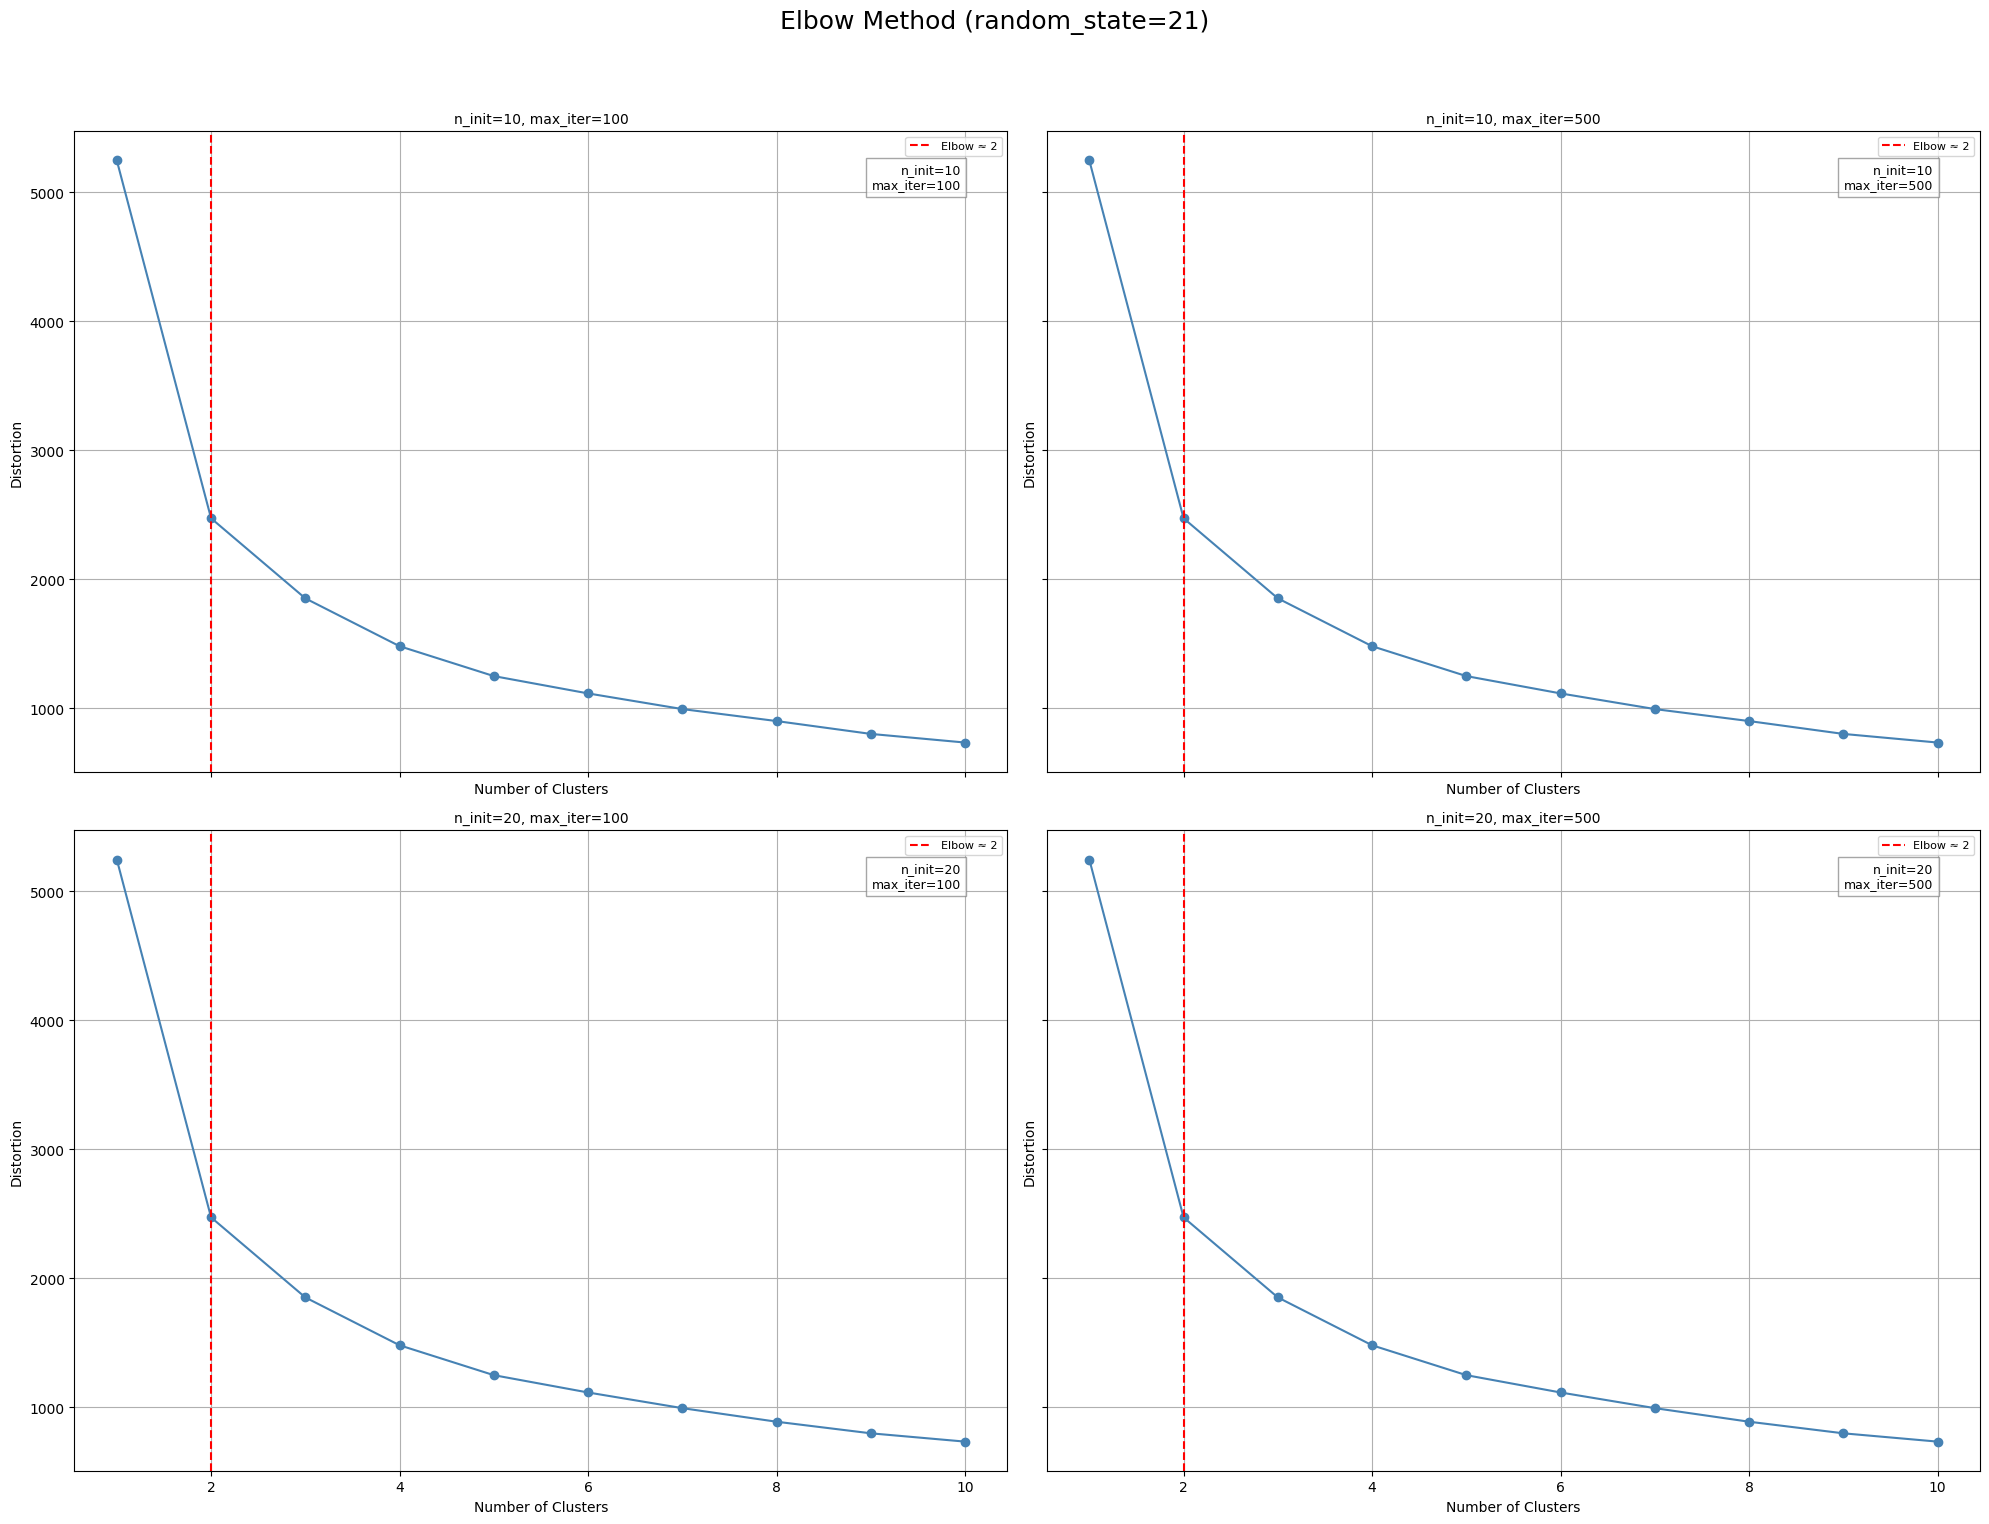


Running elbow plots for random_state=42


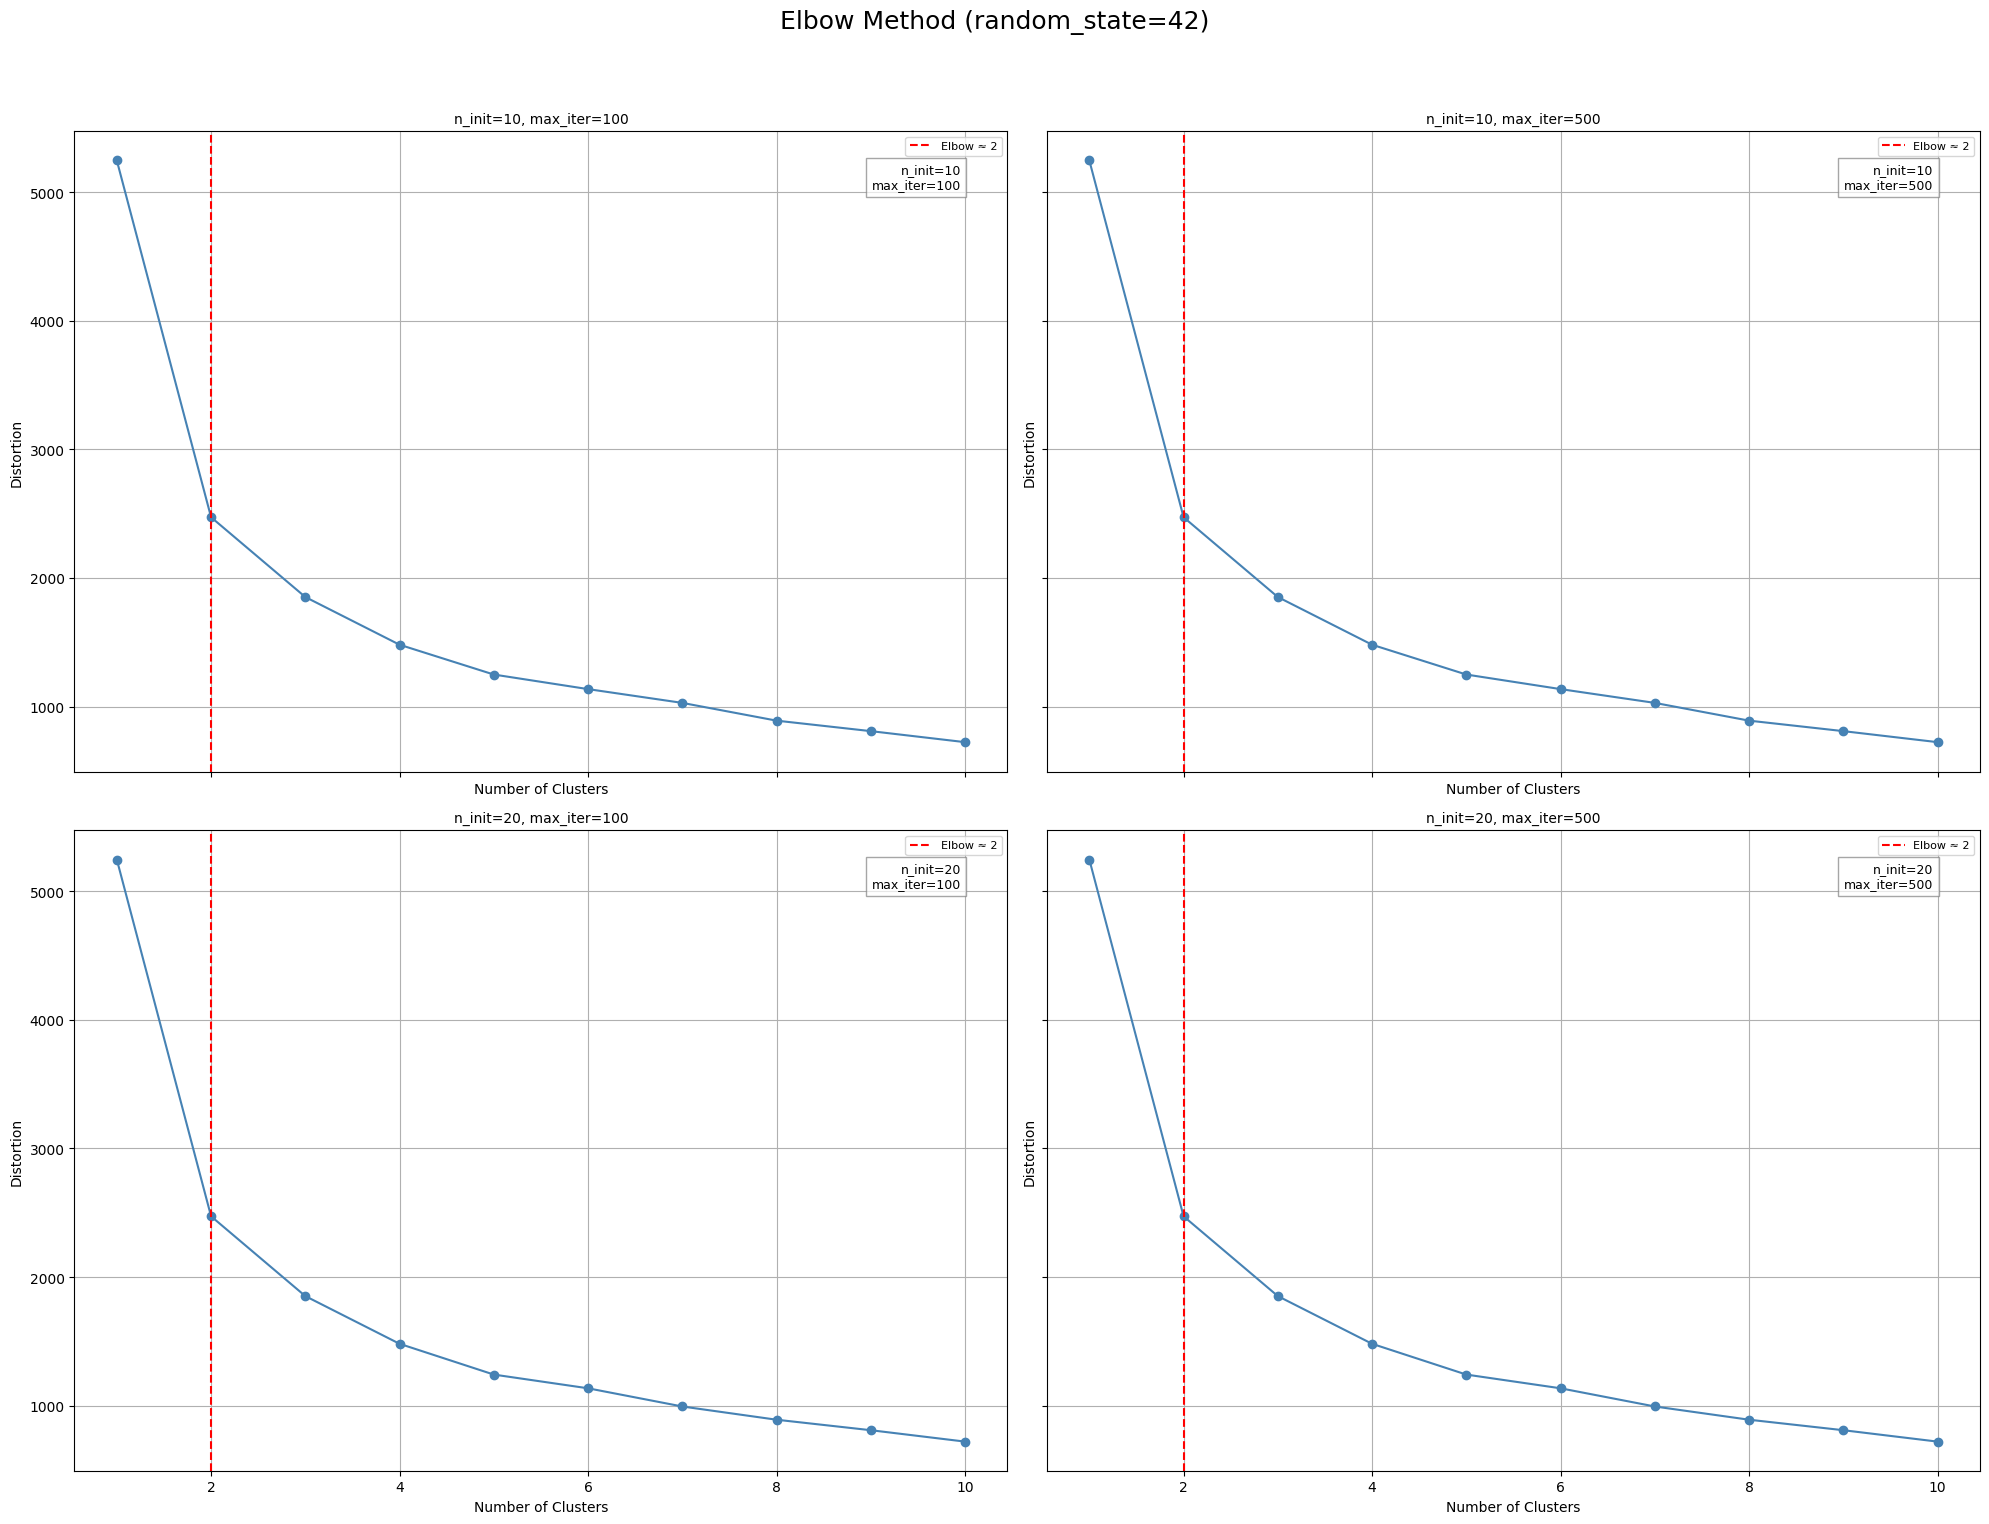


Total execution time: 6.18 seconds


In [67]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input5)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [74]:
from sklearn.metrics import silhouette_samples

In [75]:
from matplotlib import cm

In [76]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [77]:
km_c2_ni20_maxi500 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [78]:
ym_c2_ni20_maxi500 = km_c2_ni20_maxi500.fit(cluster_input5)

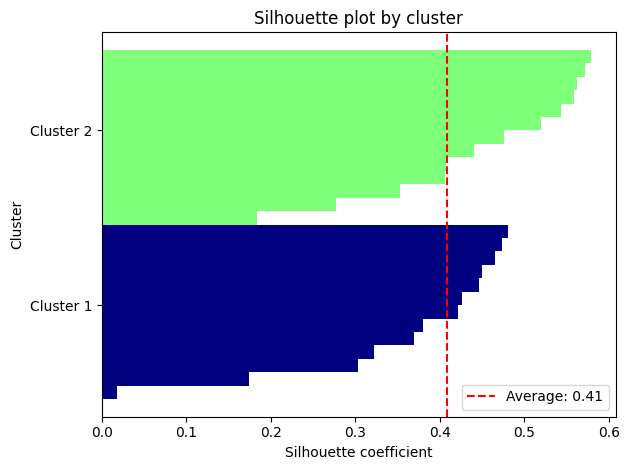

In [80]:
silhoutte_c2_ni20_maxi500 = plot_silhouette(ym_c2_ni20_maxi500, cluster_input5)

In [81]:
np.bincount(ym_c2_ni20_maxi500.labels_)

array([13, 13])

In [82]:
c2_ni20_maxi500_5 = final_win_country_delete5.copy()

In [83]:
c2_ni20_maxi500_5['cluster'] = ym_c2_ni20_maxi500.labels_

In [84]:
import country_converter as coco

In [85]:
c2_ni20_maxi500_5['ISO_A3'] = coco.convert(names=c2_ni20_maxi500_5['Country'], to='ISO3')

In [86]:
clusters_c2_ni20_maxi500_5 = c2_ni20_maxi500_5[['Country', 'ISO_A3', 'cluster']].copy()

In [87]:
clusters_c2_ni20_maxi500_5.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500_5['Country'], to='continent'
)

In [88]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [89]:
print_cluster_groups(clusters_c2_ni20_maxi500_5)


🌍 Cluster 0 (13 countries):
 - Czech (Europe)
 - France (Europe)
 - Germany (Europe)
 - Iceland (Europe)
 - Italy (Europe)
 - Netherlands (Europe)
 - Norway (Europe)
 - Paraguay (America)
 - Poland (Europe)
 - Spain (Europe)
 - Sweden (Europe)
 - Thailand (Asia)
 - United Kingdom (Europe)

🌍 Cluster 1 (13 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Croatia (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Portugal (Europe)
 - Slovenia (Europe)


In [90]:
clusters_c2_ni20_maxi500_5['Country'] = clusters_c2_ni20_maxi500_5['Country'].replace('Czech','Czech Republic')

In [91]:
clusters_c2_ni20_maxi500_5.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_5.parquet')

#### final_win_country_delete6

In [69]:
cluster_input6 = final_win_country_delete6.select_dtypes(include='number')
cluster_input6.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.554929,4.560173,1.820075,0.054347,...,0.432566,0.422131,-0.489723,0.470588,0.438596,0.444444,0.225607,-0.482700,1.086080,0.386612
1,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,0.011140,...,0.367599,0.368852,-0.187144,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.945877,0.000000
2,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,0.016140,...,0.139803,0.118852,0.356467,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
5,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.728184,4.749703,2.044840,0.057789,...,0.518092,0.508197,-0.122864,0.512605,0.640351,0.392593,-0.173826,0.525702,-0.083223,-0.446721
6,2.328545,2.318950,0.359796,2.278292,2.394252,2.394252,4.629277,4.634243,1.343487,0.027274,...,-0.215461,-0.209016,0.737143,-0.302521,-0.157895,-0.200000,-0.188519,-0.729700,0.659211,-0.301913


#### Using the elbow method to find the optimal number of clusters

In [70]:
distortions = []

In [71]:
import time

In [72]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


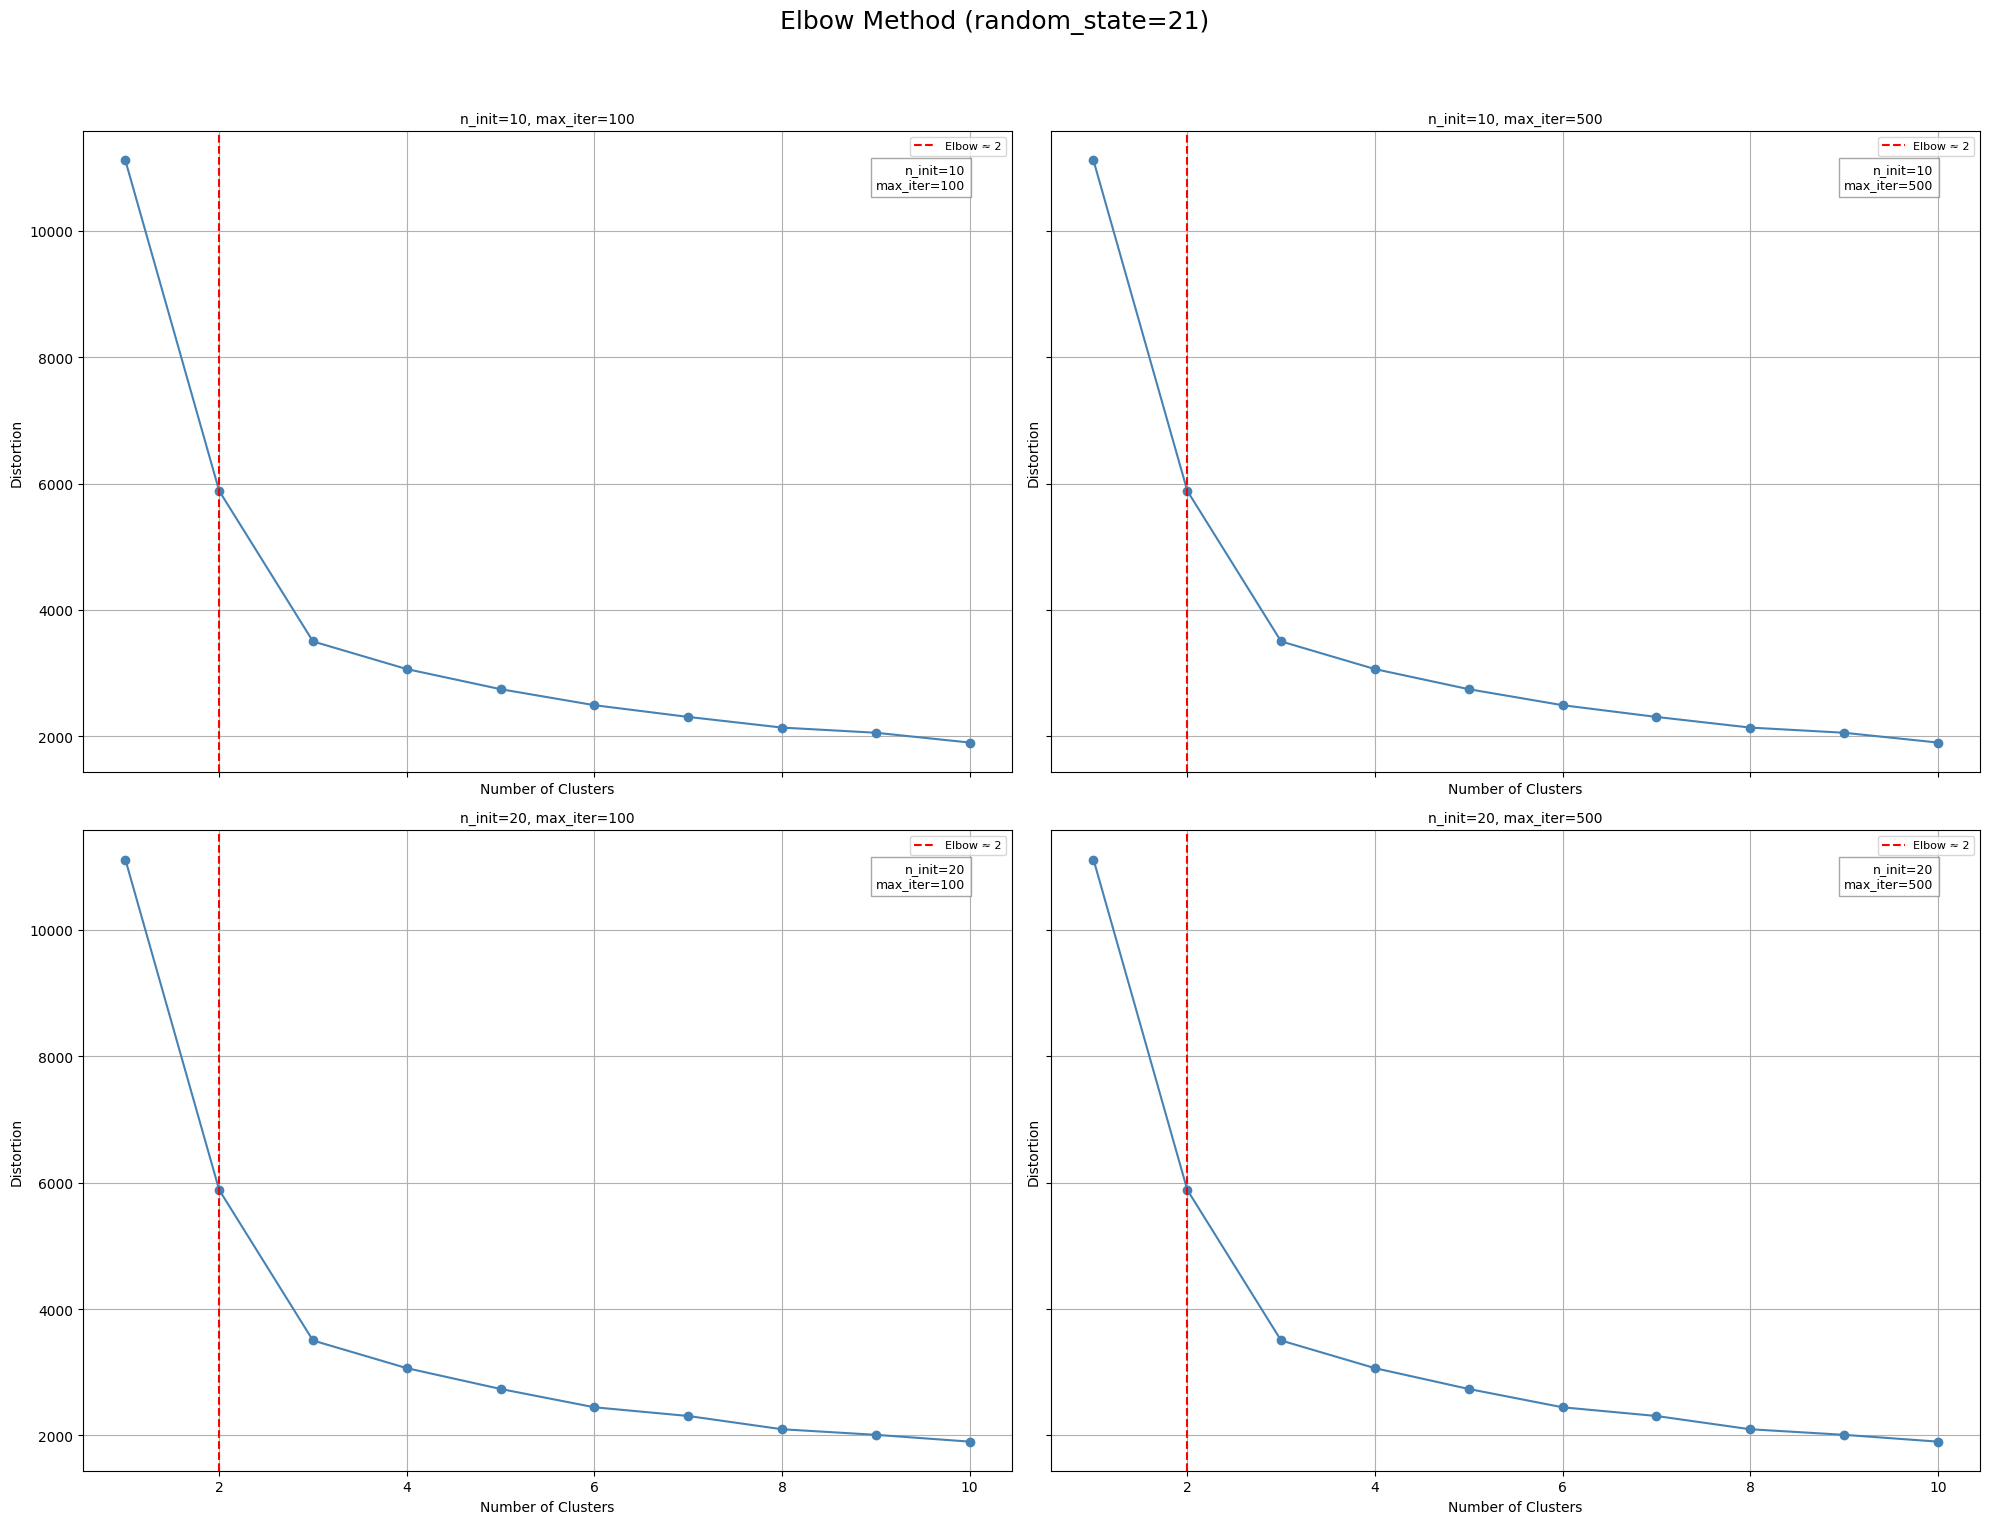


Running elbow plots for random_state=42


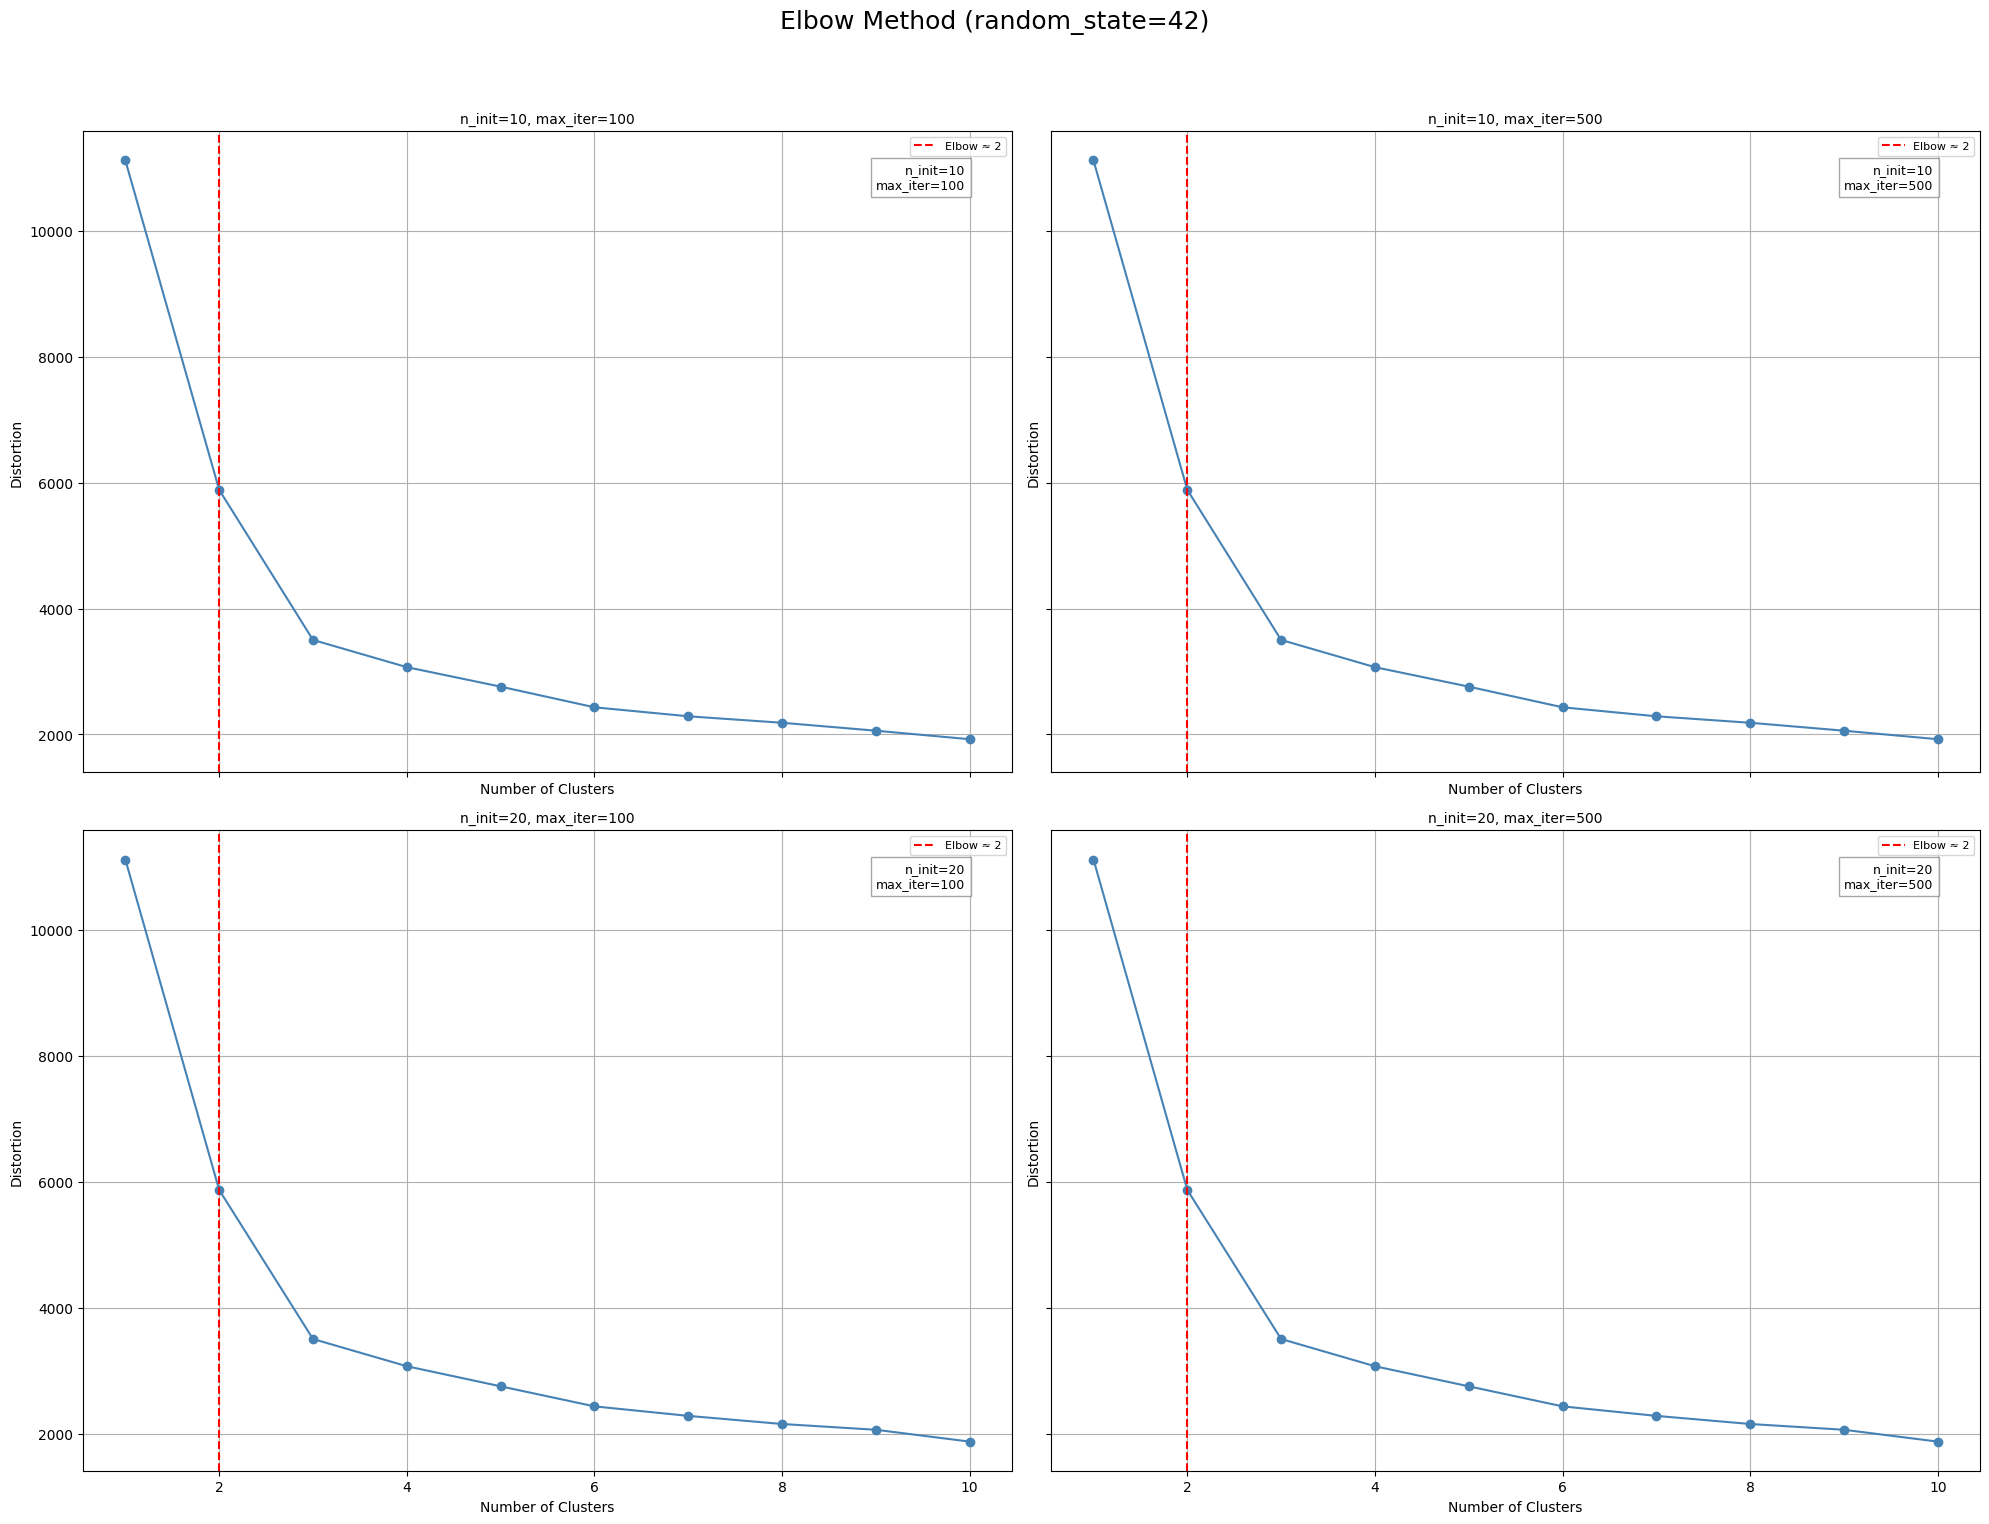


Total execution time: 4.53 seconds


In [73]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input6)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

* So the distorsion is less that the previous cluster model
* See what about the silhouette

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [92]:
km_c2_ni20_maxi500_6 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [93]:
ym_c2_ni20_maxi500_6 = km_c2_ni20_maxi500_6.fit(cluster_input6)

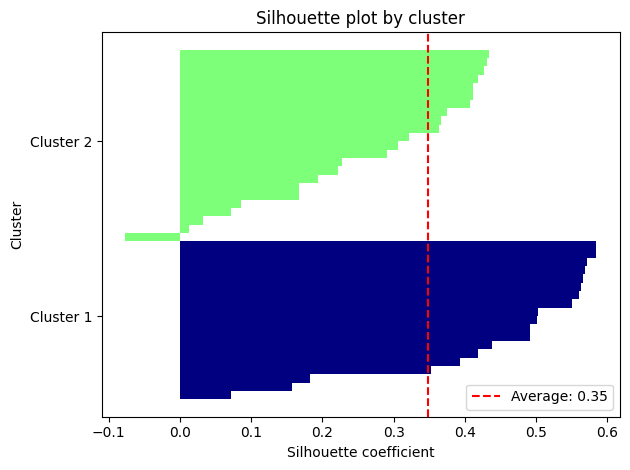

In [94]:
silhoutte_c2_ni20_maxi500_6 = plot_silhouette(ym_c2_ni20_maxi500_6, cluster_input6)

* Bad results

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [95]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [96]:
df_hpi_winsorized.shape

(15, 53)

In [97]:
clusters_c2_ni20_maxi500_5.shape

(26, 4)

In [98]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [101]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi_winsorized, clusters_c2_ni20_maxi500_5)

Countries in HPI that are missing from the cluster DataFrame:
 - Australia
 - Brazil
 - Bulgaria
 - Canada
 - Chile
 - Colombia
 - Cyprus
 - Denmark
 - Hungary
 - India
 - Israel
 - Japan
 - Malaysia
 - Mexico
 - New Zealand
 - Peru
 - Philippines
 - Romania
 - Russia
 - Serbia
 - Singapore
 - Slovakia
 - South Africa
 - South Korea
 - Switzerland
 - Turkey
 - USA
 - Year


In [102]:
df_hpi_winsorized.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Slovenia,South Africa,South Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United Kingdom
0,2010,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,2011,97.84,104.22,103.58,110.52,94.49,105.75,110.52,107.89,100.16,...,102.72,103.59,105.23,94.49,102.58,107.51,104.26,108.80,97.24,98.54
2,2012,97.53,117.13,106.02,124.02,92.69,110.62,124.02,118.79,98.62,...,95.63,108.41,108.25,88.37,103.86,113.72,107.63,120.68,101.82,98.92
3,2013,103.99,122.59,107.59,136.52,90.65,112.76,136.52,130.06,94.70,...,90.62,115.41,107.80,85.58,109.22,118.30,115.99,134.46,111.83,101.46
4,2014,113.41,126.79,107.22,151.67,91.95,118.86,151.67,140.75,93.19,...,84.64,123.99,109.43,84.64,119.52,121.46,127.07,151.25,118.88,109.60


In [118]:
def drop_country_columns_except_year(df, country_list, year_label="Year"):
    """
    Elimina columnas del DataFrame que coincidan con los nombres en 'country_list',
    ignorando la columna 'Year' incluso si está en la lista.

    Parámetros:
    - df: pandas.DataFrame
        DataFrame original con columnas nombradas por país.
    - country_list: list
        Lista de nombres de países (y posiblemente 'Year').
    - year_label: str
        Nombre de la columna que debe conservarse aunque esté en la lista.

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame sin las columnas correspondientes a los países (excepto 'Year').
    """

    # Filtrar la lista excluyendo 'Year'
    columns_to_drop = [col for col in country_list if col != year_label]

    # Eliminar columnas si existen en el DataFrame
    df_filtrado = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

    print(f"Columnas eliminadas: {columns_to_drop}")
    return df_filtrado

In [120]:
hpi_c2_ni20_maxi500_5 = drop_country_columns_except_year(df_hpi_winsorized, missing_countries_5)

Columnas eliminadas: ['USA', 'Chile', 'Russia', 'Canada', 'Brazil', 'Romania', 'Malaysia', 'Switzerland', 'Bulgaria', 'Israel', 'South Africa', 'Colombia', 'Serbia', 'South Korea', 'New Zealand', 'Australia', 'Slovakia', 'Philippines', 'Hungary', 'Singapore', 'Turkey', 'India', 'Cyprus', 'Mexico', 'Denmark', 'Peru', 'Japan']


In [121]:
find_countries_missing_from_clusters(hpi_c2_ni20_maxi500_5, clusters_c2_ni20_maxi500_5)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


['Year']

In [167]:
hpi_c2_ni20_maxi500_5.shape

(15, 26)

### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [122]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

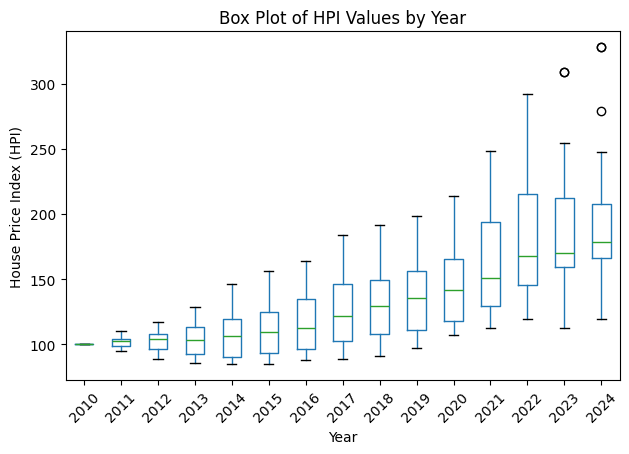

In [123]:
plot_hpi_boxplots_by_year(hpi_c2_ni20_maxi500_5)

In [124]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [127]:
hpi_c2_ni20_maxi500_5_win = round_and_winsorize_hpi(hpi_c2_ni20_maxi500_5, limits=(0.08,0.08))

<Figure size 1400x600 with 0 Axes>

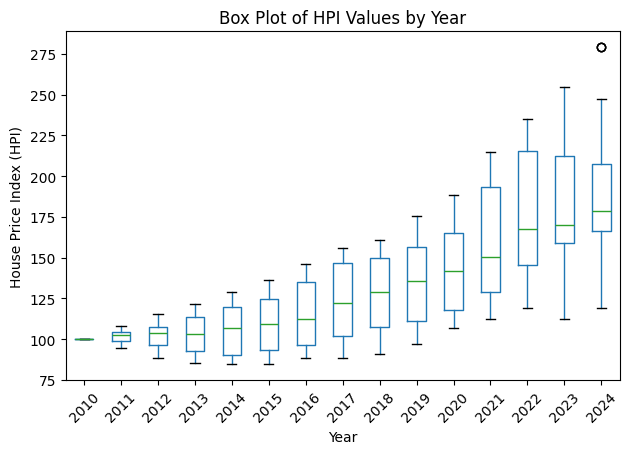

In [128]:
plot_hpi_boxplots_by_year(hpi_c2_ni20_maxi500_5_win)

In [139]:
hpi_c2_ni20_maxi500_5_win1 = round_and_winsorize_hpi(hpi_c2_ni20_maxi500_5_win, limits=(0.12,0.12))

<Figure size 1400x600 with 0 Axes>

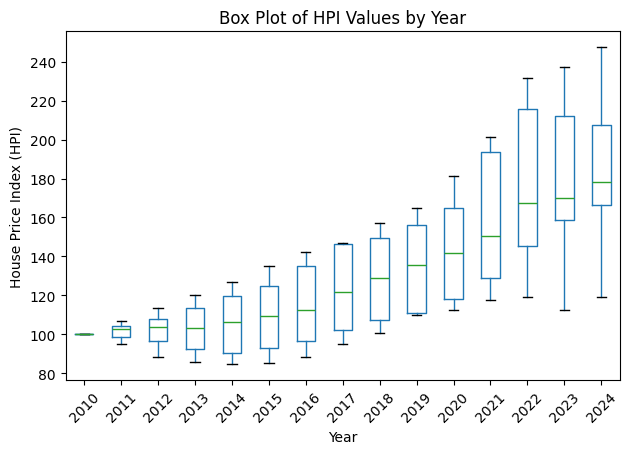

In [140]:
plot_hpi_boxplots_by_year(hpi_c2_ni20_maxi500_5_win1)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [141]:
import random

In [142]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

### Sampling experiment with seed 23

🔍 Cluster 0 selected. Excluding country: Italy
📊 Sampling from countries: ['Czech Republic', 'France', 'Germany', 'Iceland', 'Netherlands', 'Norway', 'Poland', 'Spain', 'Sweden', 'Thailand', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


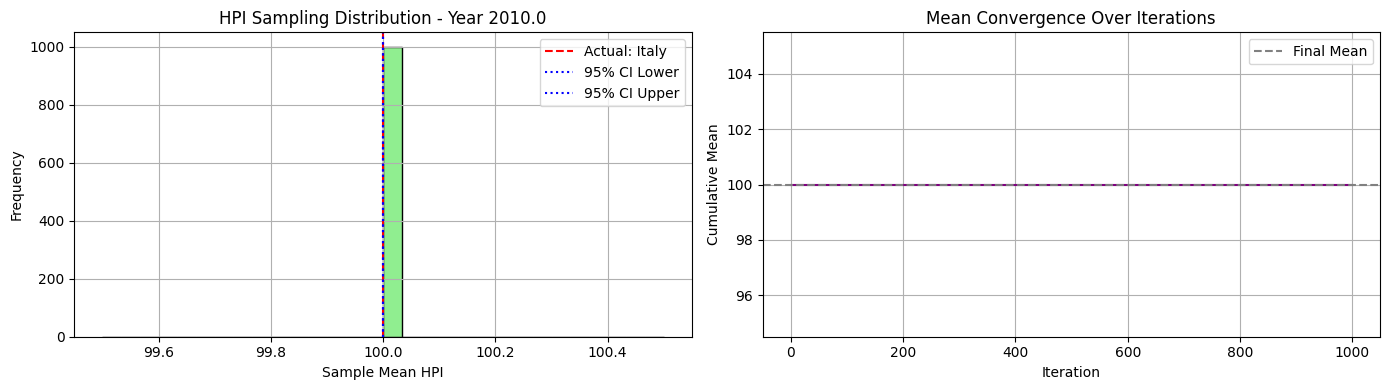


📅 Year 2011.0 - Available HPI values for sampling:
[100.02 105.69 102.42 105.5   98.02 106.6  100.08  95.1  102.58 104.26
  98.54]


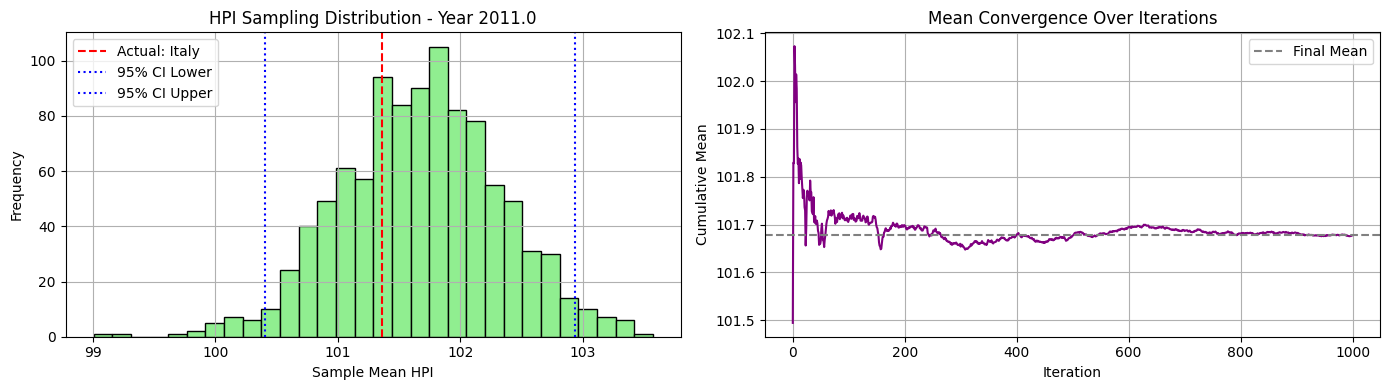


📅 Year 2012.0 - Available HPI values for sampling:
[ 98.56 105.11 105.48 112.38  91.44 113.71  96.58  88.37 103.86 107.63
  98.92]


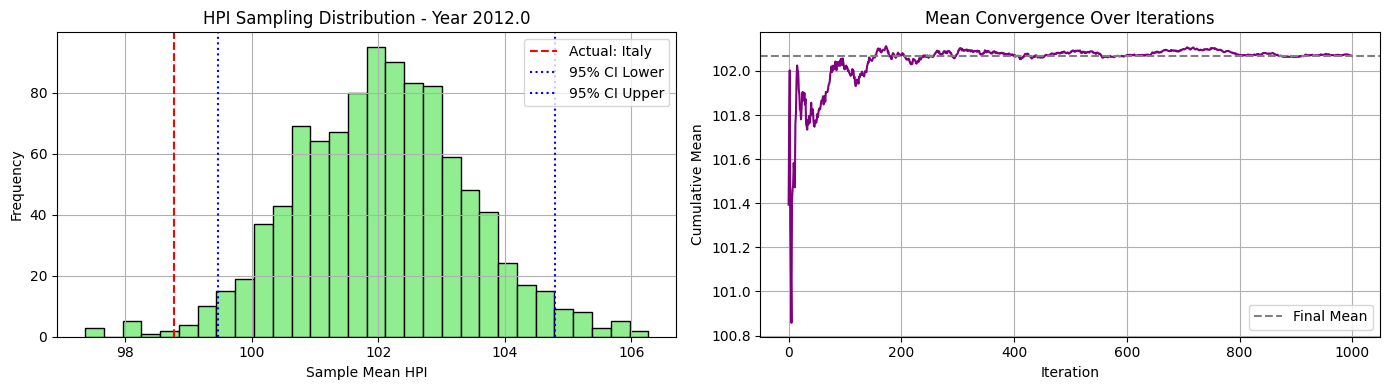


📅 Year 2013.0 - Available HPI values for sampling:
[ 98.58 103.13 108.68 119.18  85.95 119.98  92.35  85.95 109.22 115.99
 101.46]


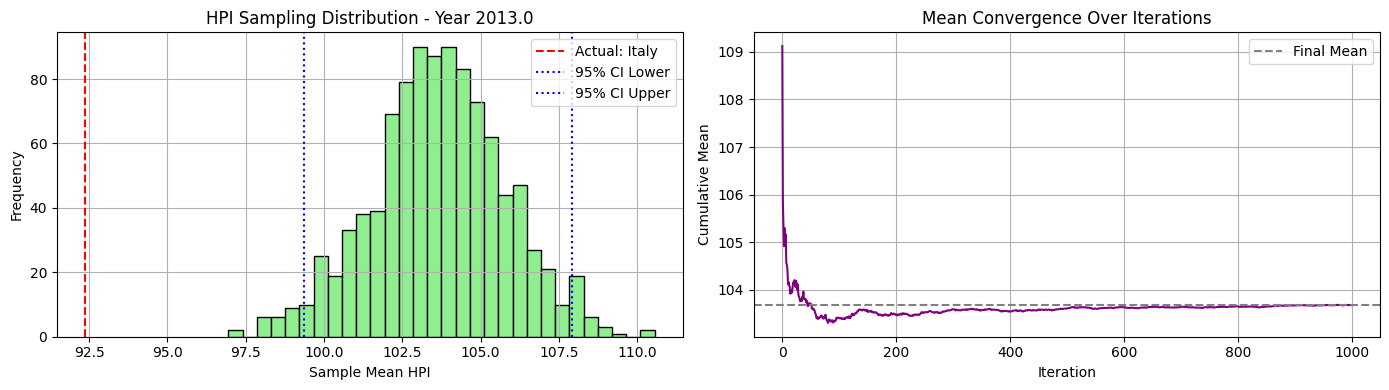


📅 Year 2014.0 - Available HPI values for sampling:
[101.   101.58 111.85 127.07  86.66 123.24  93.27  84.66 119.52 127.07
 109.6 ]


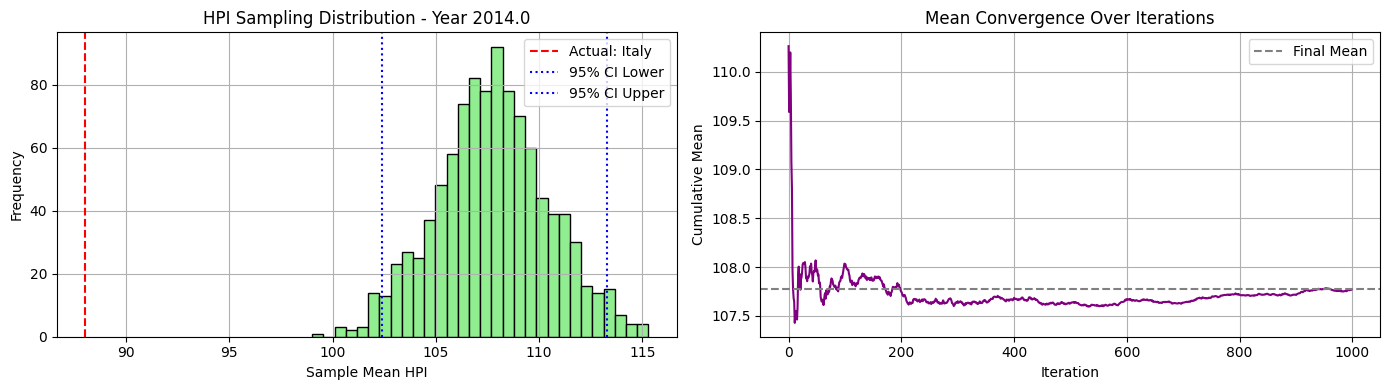


📅 Year 2015.0 - Available HPI values for sampling:
[105.01 100.22 117.12 135.2   89.69 130.76  94.69  85.32 135.2  135.2
 116.12]


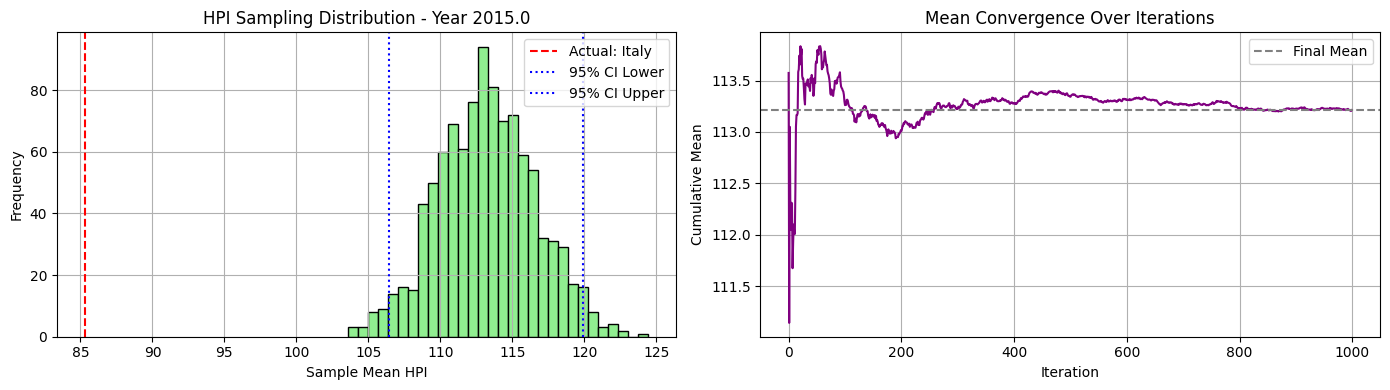


📅 Year 2016.0 - Available HPI values for sampling:
[112.52 101.25 125.93 142.4   94.43 139.95  96.44  88.1  142.4  142.4
 124.27]


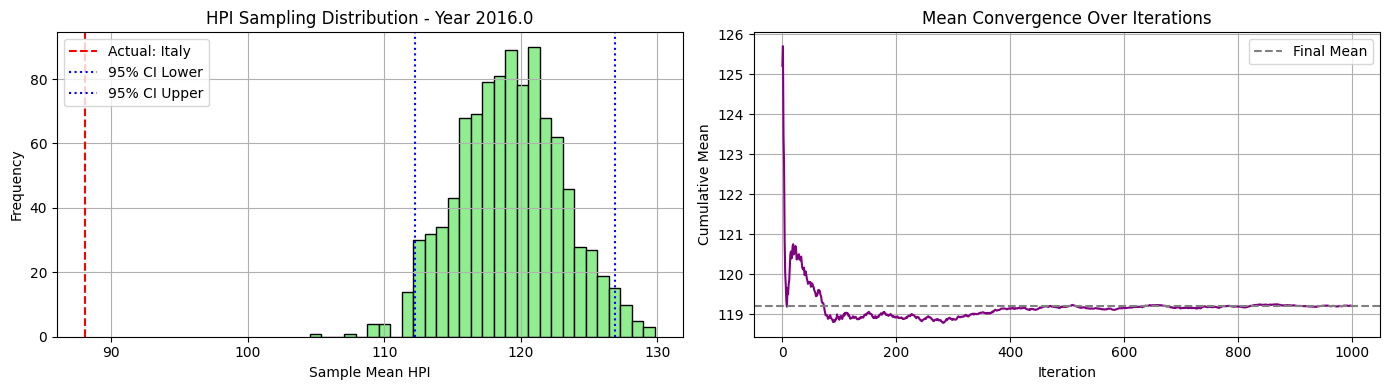


📅 Year 2017.0 - Available HPI values for sampling:
[125.7  104.46 133.62 147.08 102.06 146.91 100.16  94.84 147.08 146.48
 129.93]


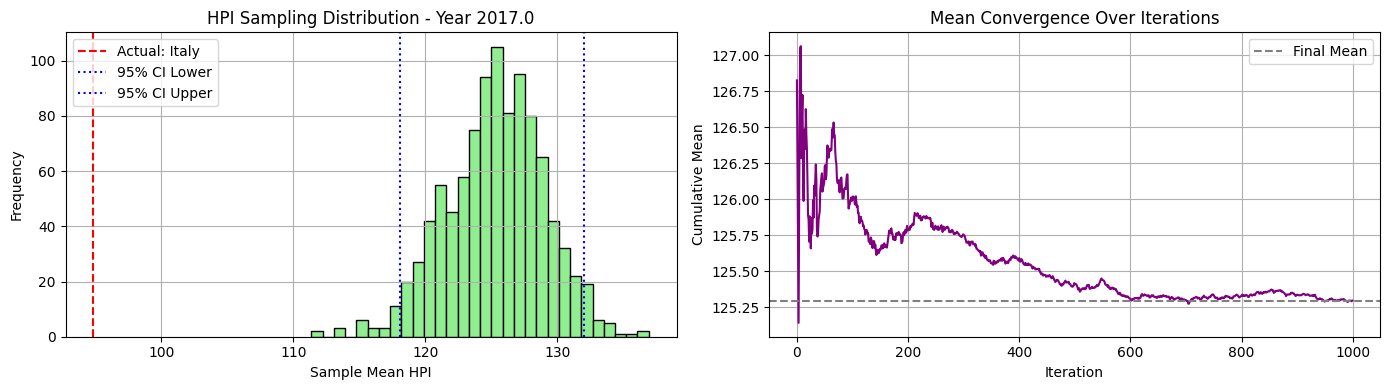


📅 Year 2018.0 - Available HPI values for sampling:
[136.52 107.52 142.52 157.24 111.57 149.04 106.75 100.59 154.6  153.9
 134.04]


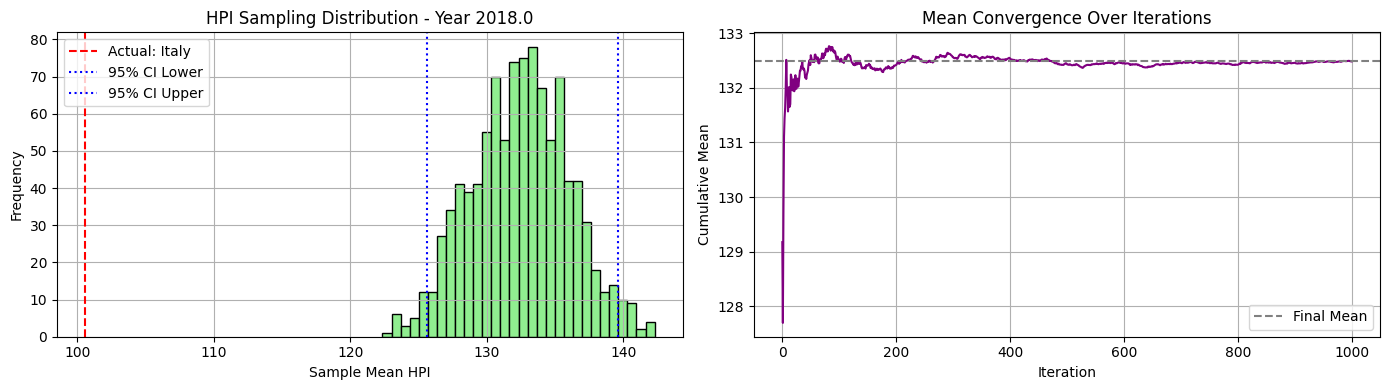


📅 Year 2019.0 - Available HPI values for sampling:
[149.02 111.1  150.75 164.68 119.62 152.73 116.01 109.64 158.44 155.1
 135.37]


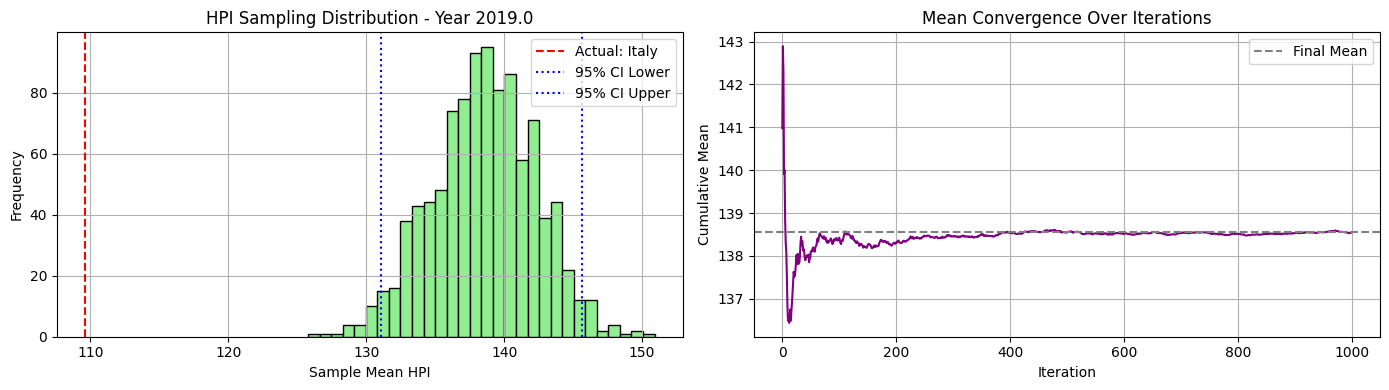


📅 Year 2020.0 - Available HPI values for sampling:
[161.56 116.89 162.48 181.42 129.21 159.24 128.18 112.49 165.09 160.6
 139.24]


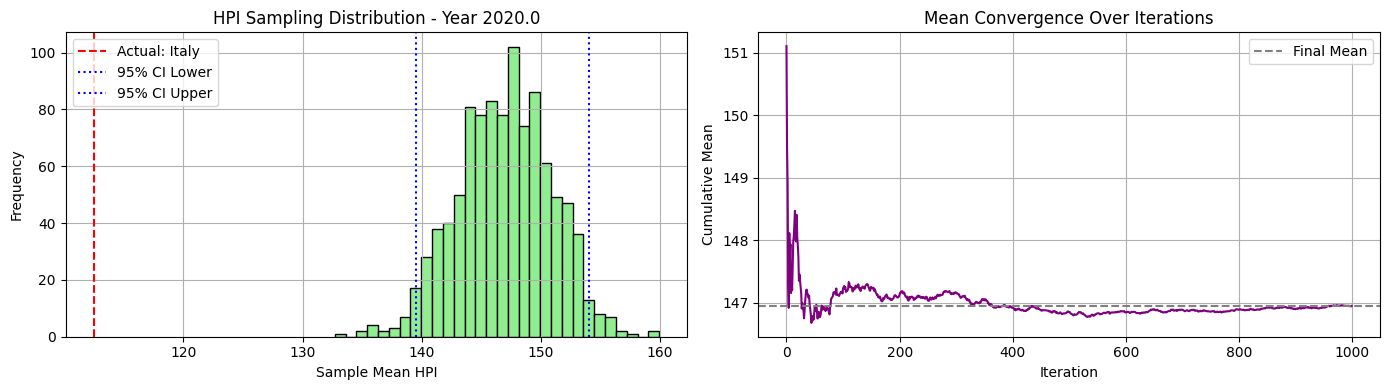


📅 Year 2021.0 - Available HPI values for sampling:
[193.46 124.38 181.28 201.18 147.93 175.91 139.92 117.62 181.79 164.23
 150.58]


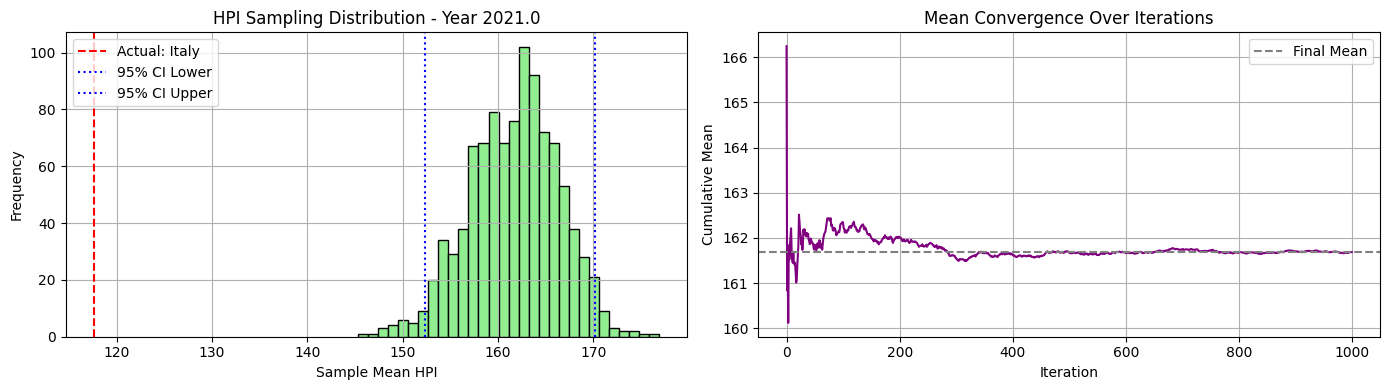


📅 Year 2022.0 - Available HPI values for sampling:
[226.15 132.1  190.42 231.64 167.57 185.13 156.43 118.98 188.27 169.16
 164.55]


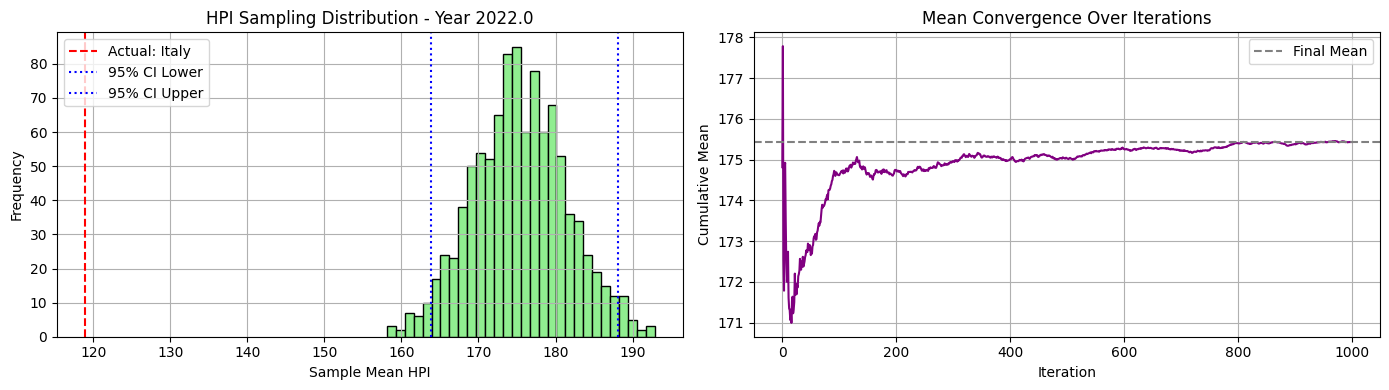


📅 Year 2023.0 - Available HPI values for sampling:
[222.4  131.52 174.25 237.56 164.36 184.12 170.23 112.27 178.36 174.79
 165.  ]


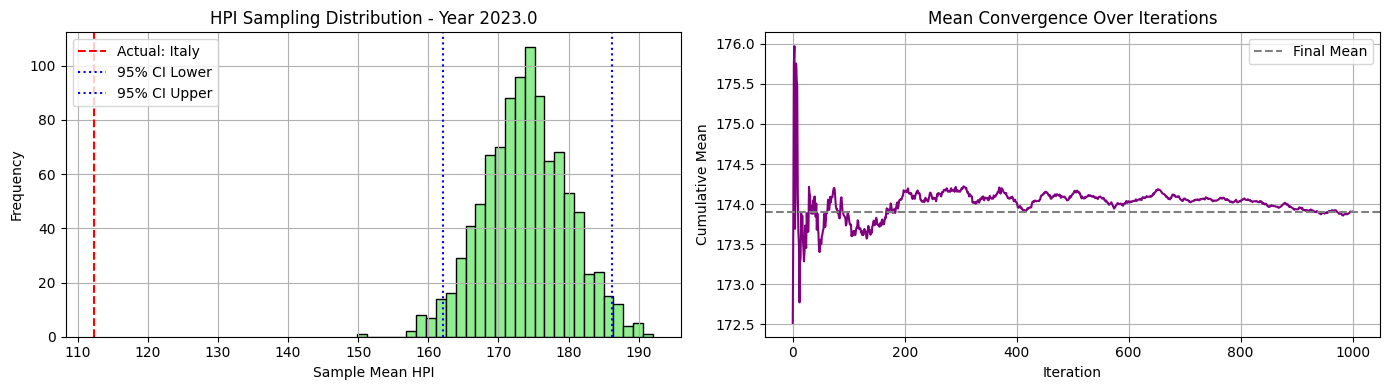


📅 Year 2024.0 - Available HPI values for sampling:
[233.42 126.68 171.5  247.54 177.7  189.05 195.72 119.1  178.49 178.06
 166.38]


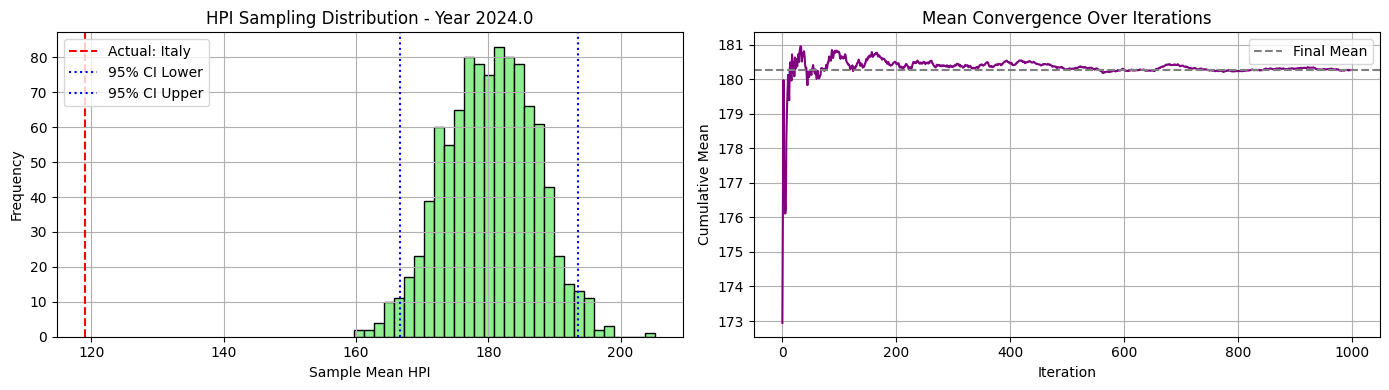

In [143]:
synthetic_c2_ni20_maxi500_5_win1_23_00, excluded_c2_ni20_maxi500_5_win1_23_00, actual_c2_ni20_maxi500_5_win1_23_00 = estimate_hpi_by_cluster_sampling(hpi_c2_ni20_maxi500_5_win1, clusters_c2_ni20_maxi500_5, cluster_id=0, seed=23)

🔍 Cluster 1 selected. Excluding country: Slovenia
📊 Sampling from countries: ['Austria', 'Belgium', 'Croatia', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Portugal']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


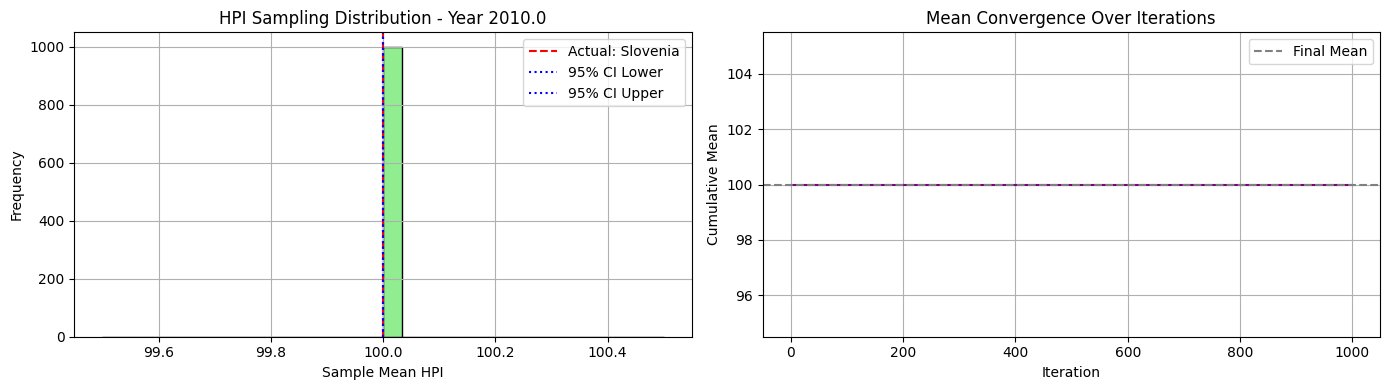


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58 100.16 106.6  103.17  95.1   95.1  106.6  106.6  103.68
  98.63  95.1 ]


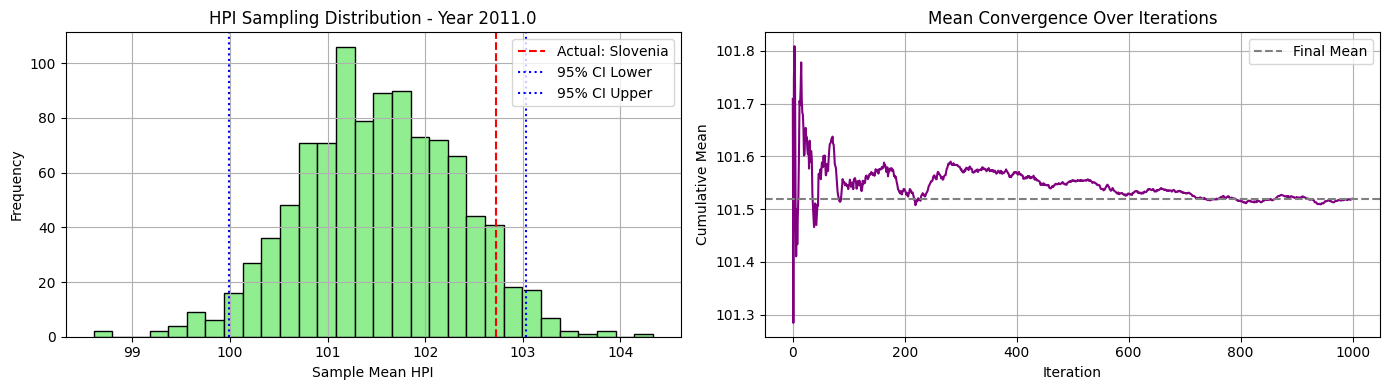


📅 Year 2012.0 - Available HPI values for sampling:
[113.71 106.02  98.62 113.71 105.64  88.37  88.37 113.71 106.36 108.03
 101.62  88.37]


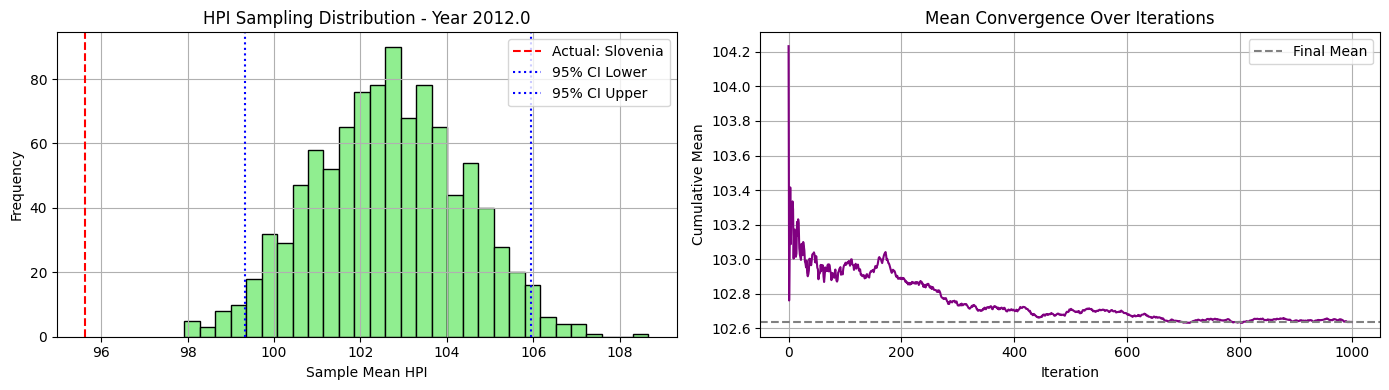


📅 Year 2013.0 - Available HPI values for sampling:
[119.98 107.59  94.7  119.98 106.87  85.95  85.95 119.98 107.65 113.42
 101.21  86.7 ]


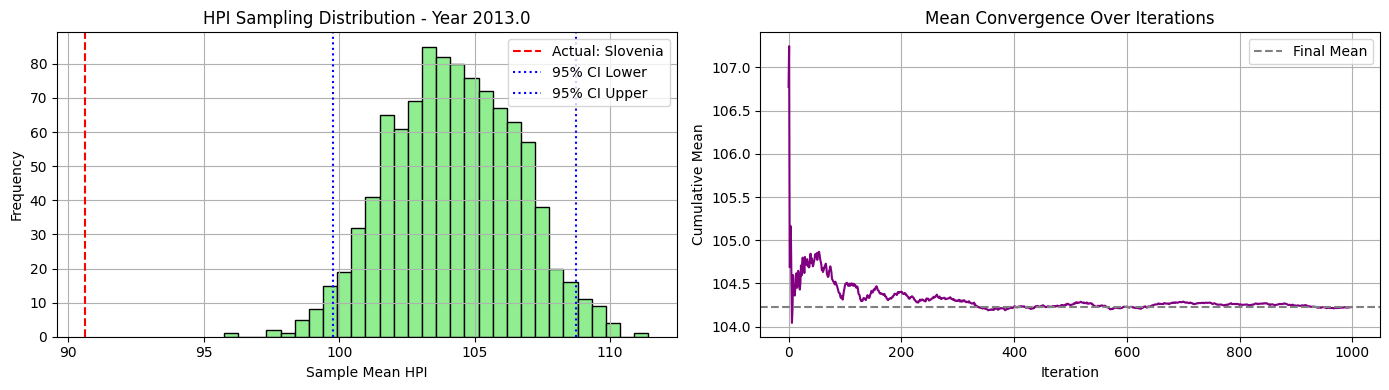


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  93.19 127.07 106.5   84.66  84.66 127.07 114.57 118.39
 103.79  90.38]


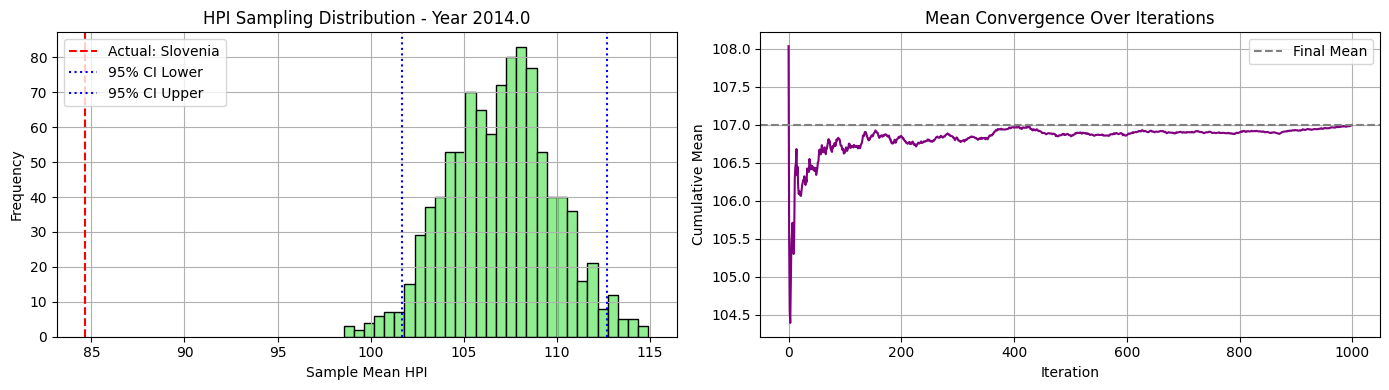


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  90.54 135.2  106.5   85.32  94.36 124.46 118.76 124.78
 109.83  93.15]


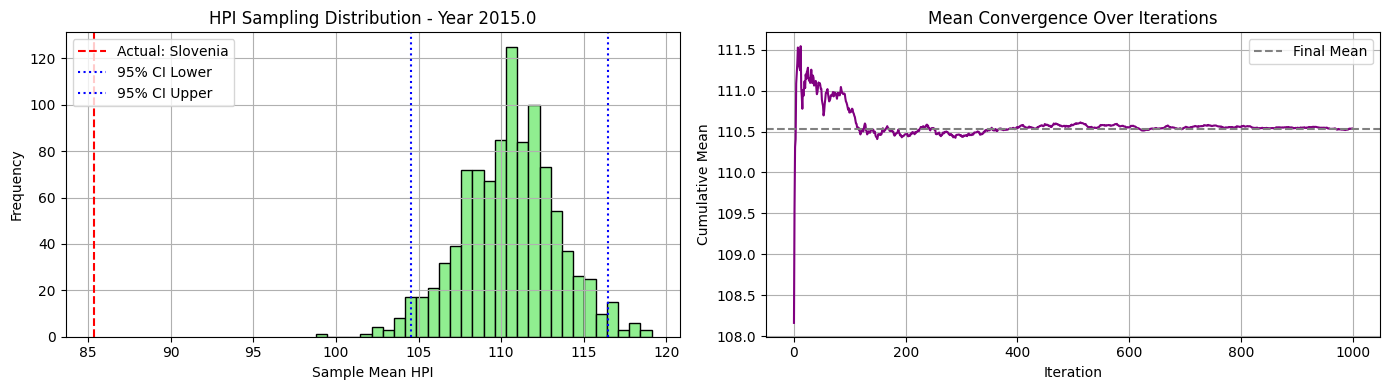


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72  91.33 142.4  107.86  88.1  101.42 135.02 125.16 132.28
 115.82  99.78]


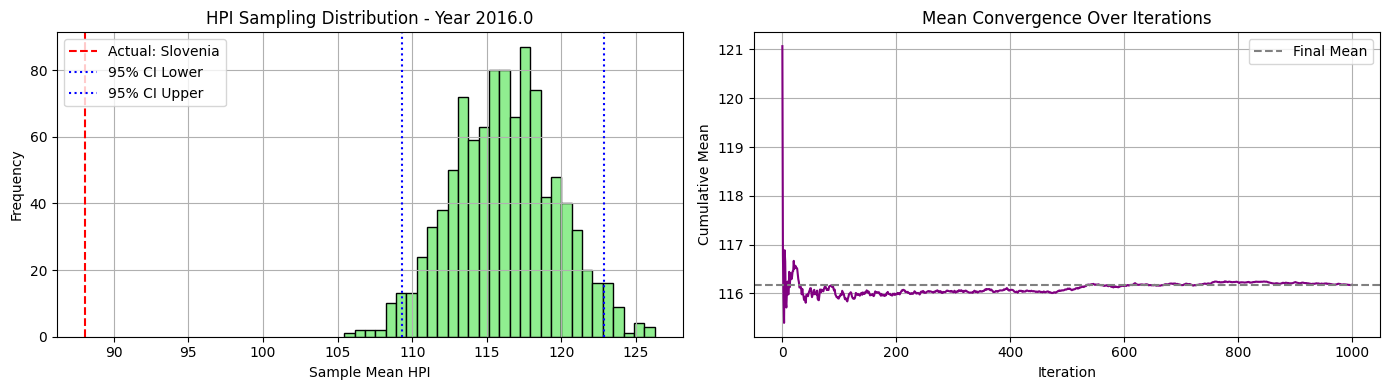


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66  94.84 147.08 109.02  94.84 112.44 146.87 136.34 139.69
 121.94 108.99]


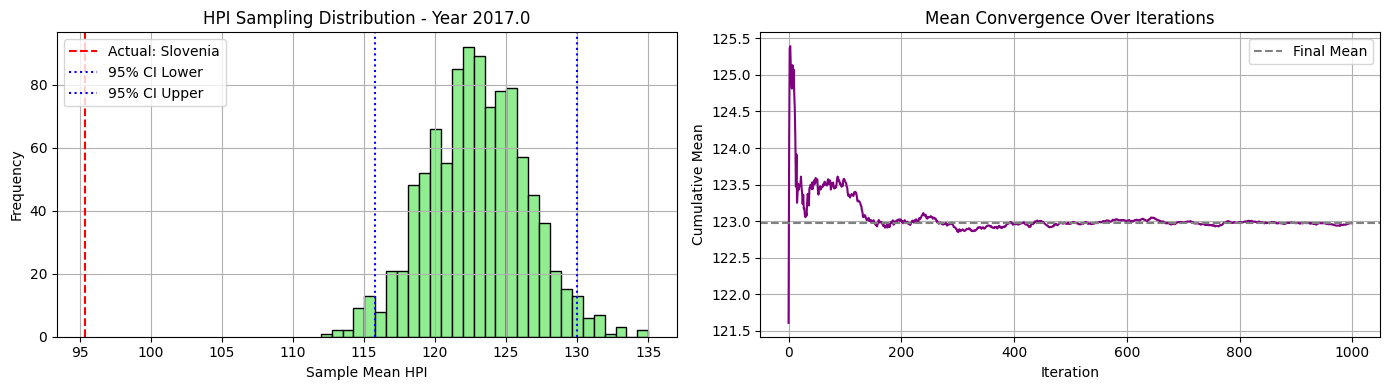


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 100.59 157.24 110.06 100.59 123.96 157.24 146.29 149.55
 129.02 120.19]


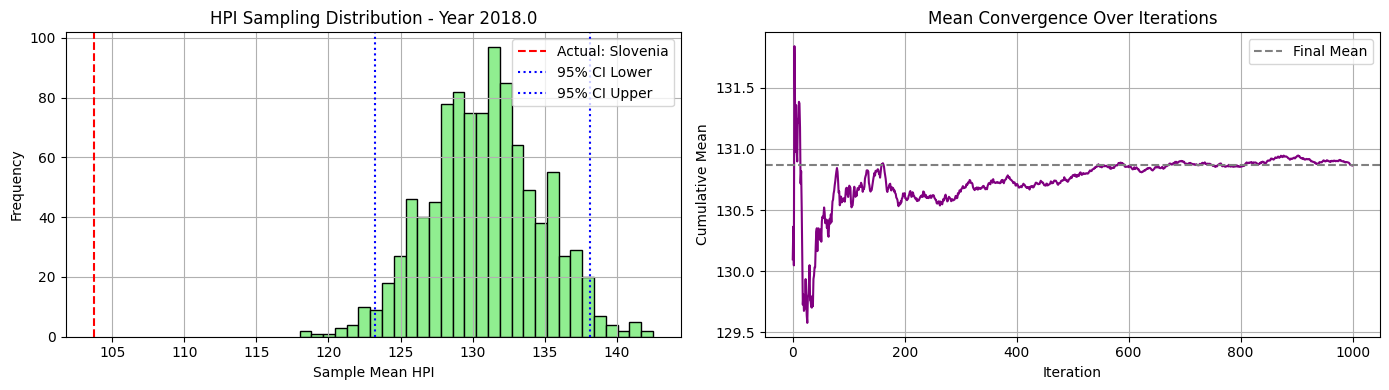


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 109.64 164.68 110.52 109.64 126.85 164.68 156.3  164.68
 136.9  132.16]


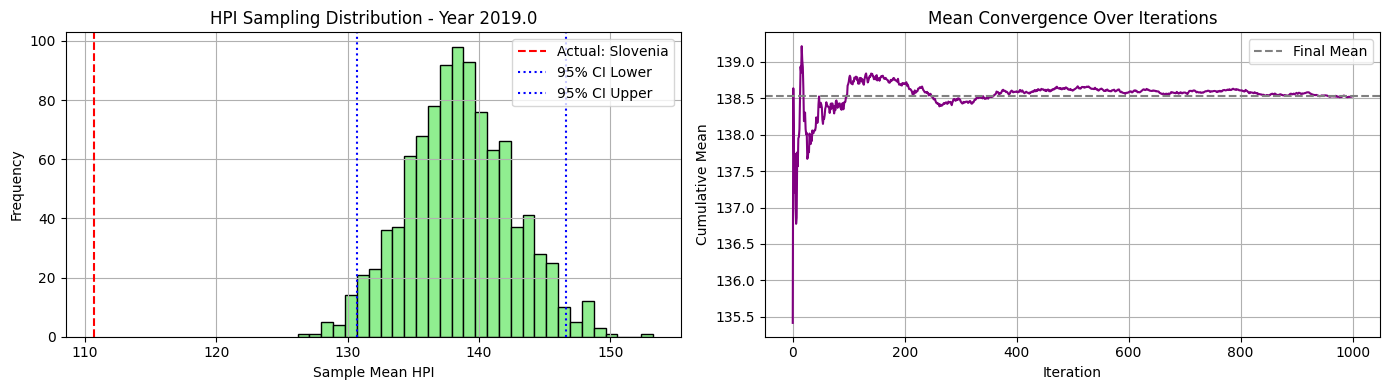


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 118.06 181.42 112.49 112.49 127.24 181.42 167.66 181.42
 141.54 143.75]


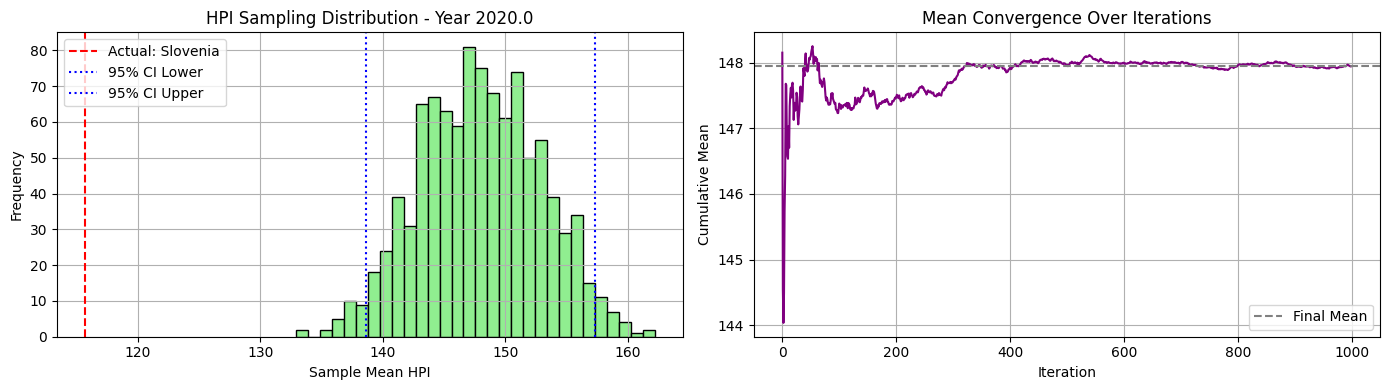


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 126.64 201.18 117.62 117.62 137.77 201.18 194.58 201.18
 148.74 157.27]


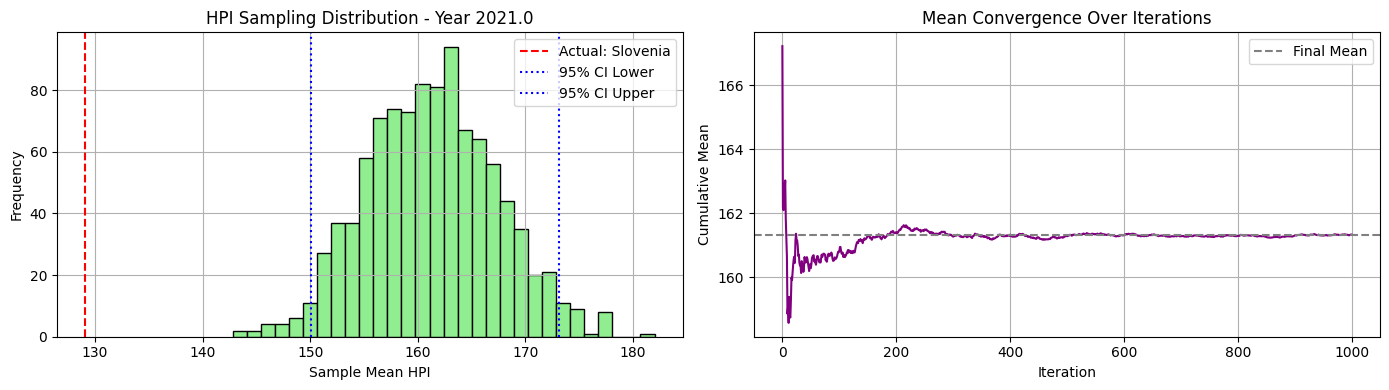


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 145.44 231.64 118.98 118.98 154.73 229.01 231.64 231.64
 158.62 177.14]


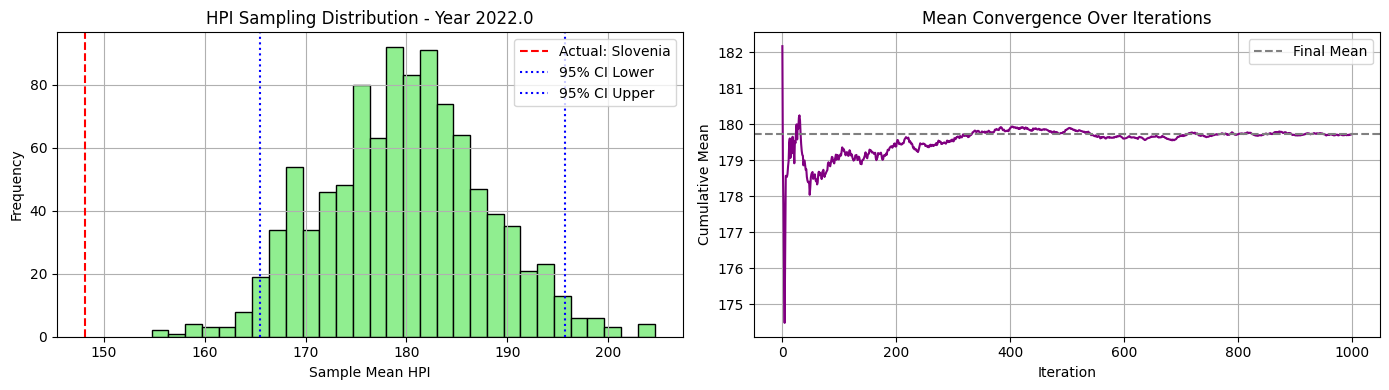


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 162.82 237.56 112.27 112.27 159.48 237.56 237.56 214.
 168.5  191.66]


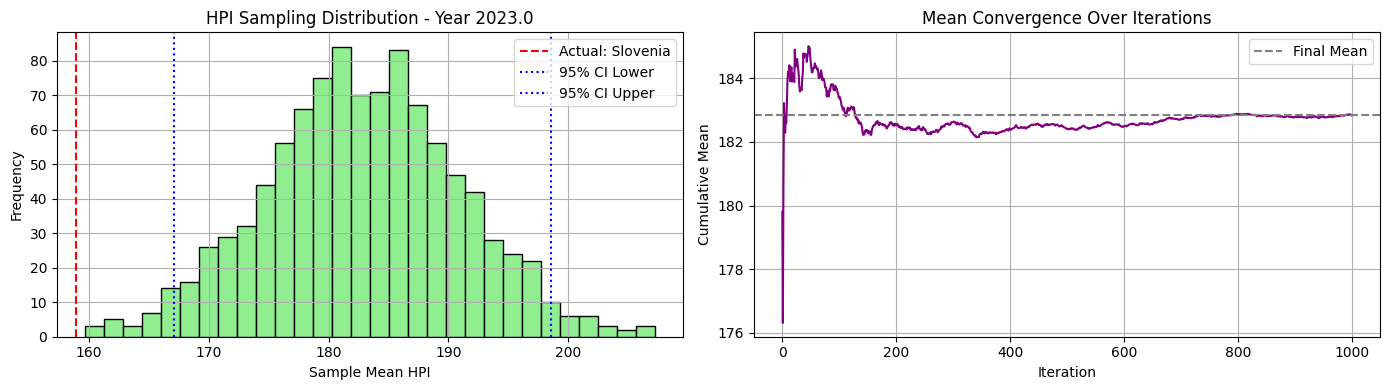


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 179.7  247.54 119.1  119.1  173.07 247.54 247.54 202.74
 179.35 209.06]


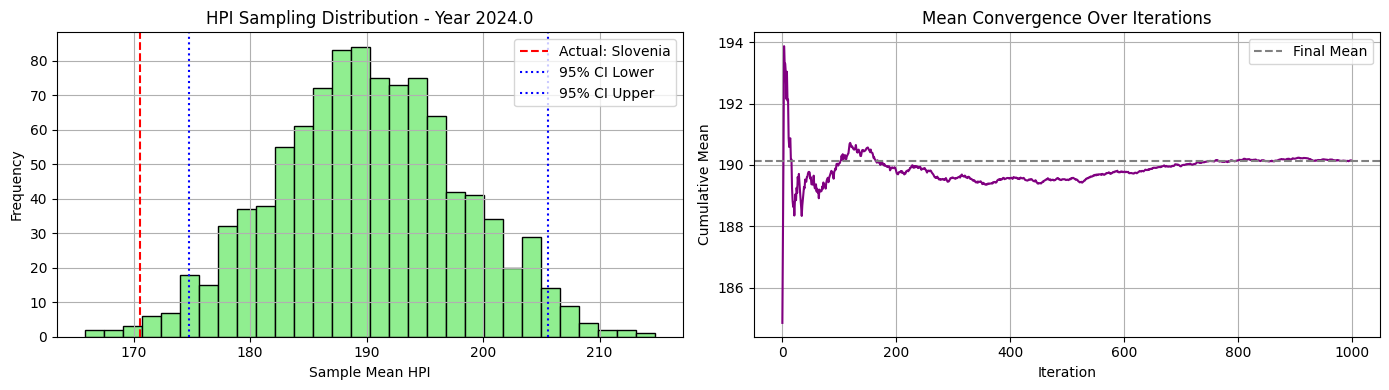

In [144]:
synthetic_c2_ni20_maxi500_5_win1_23_01, excluded_c2_ni20_maxi500_5_win1_23_01, actual_c2_ni20_maxi500_5_win1_23_01 = estimate_hpi_by_cluster_sampling(hpi_c2_ni20_maxi500_5_win1, clusters_c2_ni20_maxi500_5, cluster_id=1, seed=23)

### Sampling experiment with seed 32

🔍 Cluster 0 selected. Excluding country: France
📊 Sampling from countries: ['Czech Republic', 'Germany', 'Iceland', 'Italy', 'Netherlands', 'Norway', 'Poland', 'Spain', 'Sweden', 'Thailand', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


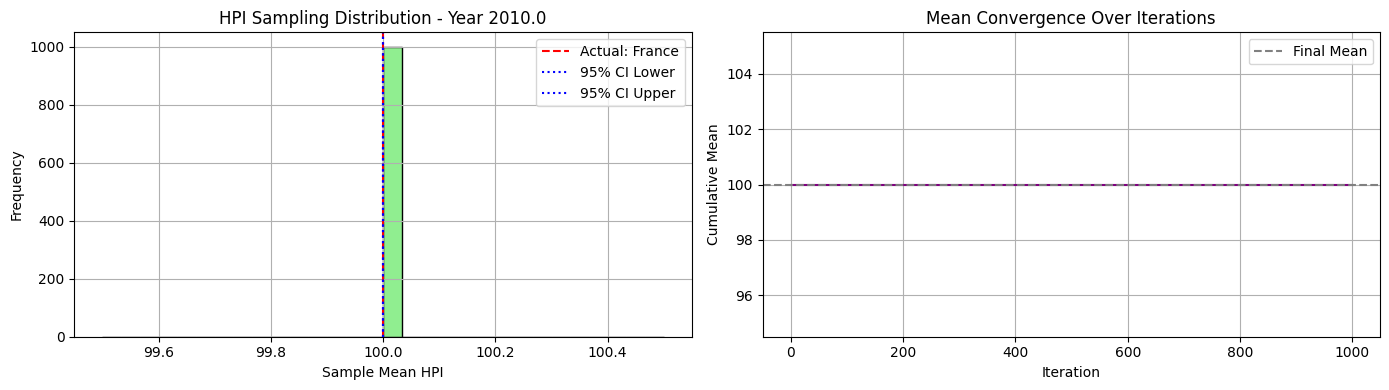


📅 Year 2011.0 - Available HPI values for sampling:
[100.02 102.42 105.5  101.36  98.02 106.6  100.08  95.1  102.58 104.26
  98.54]


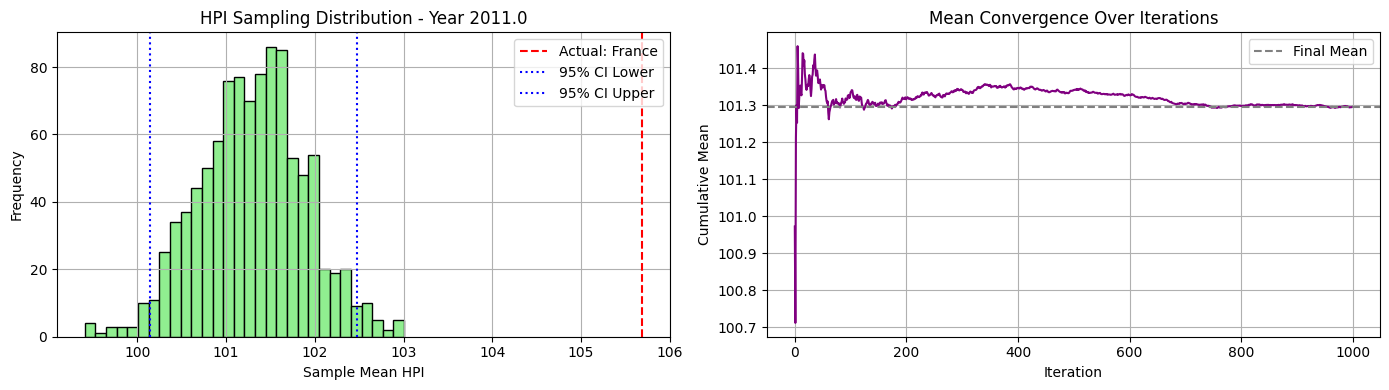


📅 Year 2012.0 - Available HPI values for sampling:
[ 98.56 105.48 112.38  98.77  91.44 113.71  96.58  88.37 103.86 107.63
  98.92]


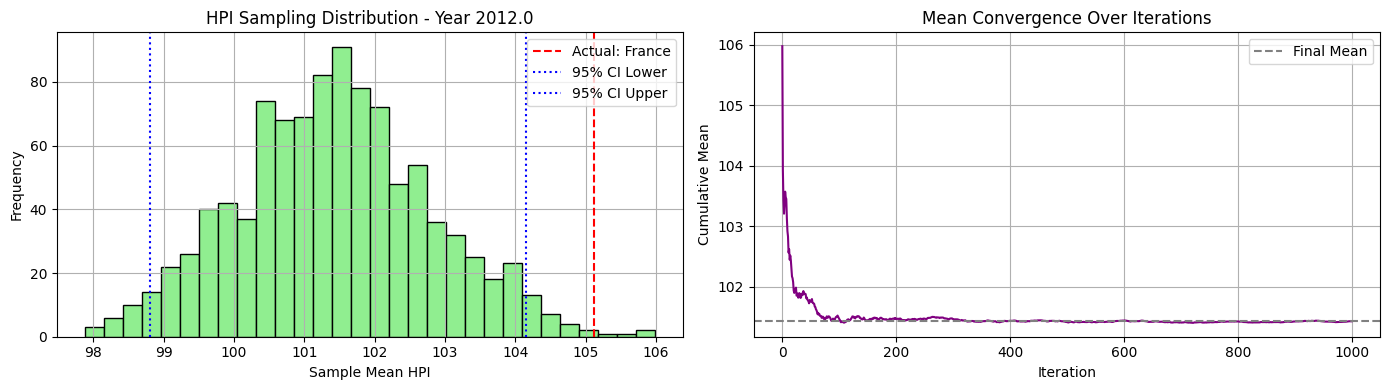


📅 Year 2013.0 - Available HPI values for sampling:
[ 98.58 108.68 119.18  92.38  85.95 119.98  92.35  85.95 109.22 115.99
 101.46]


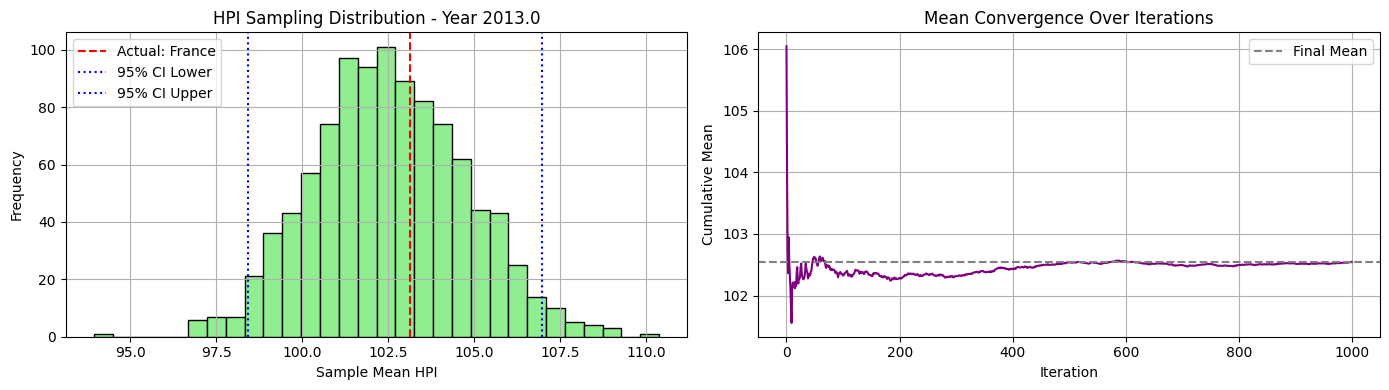


📅 Year 2014.0 - Available HPI values for sampling:
[101.   111.85 127.07  88.02  86.66 123.24  93.27  84.66 119.52 127.07
 109.6 ]


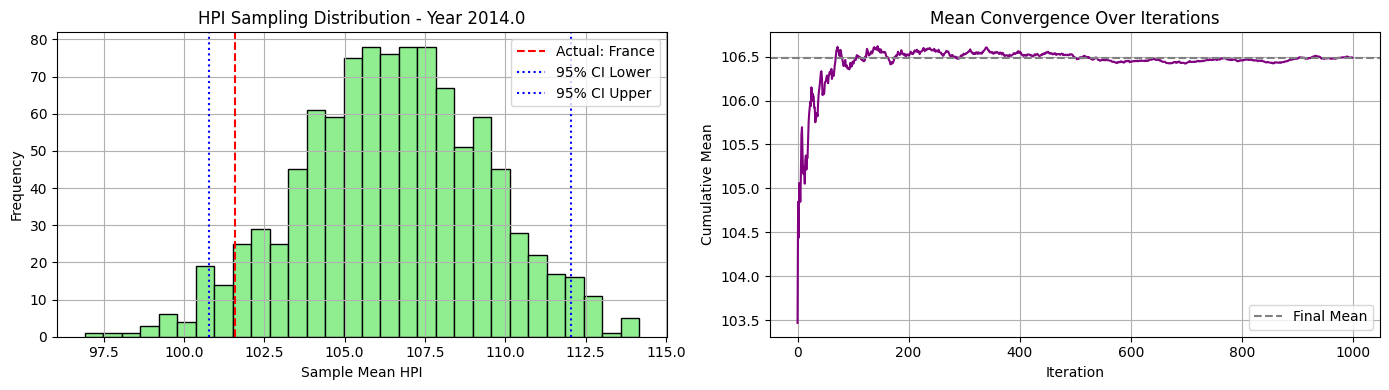


📅 Year 2015.0 - Available HPI values for sampling:
[105.01 117.12 135.2   85.32  89.69 130.76  94.69  85.32 135.2  135.2
 116.12]


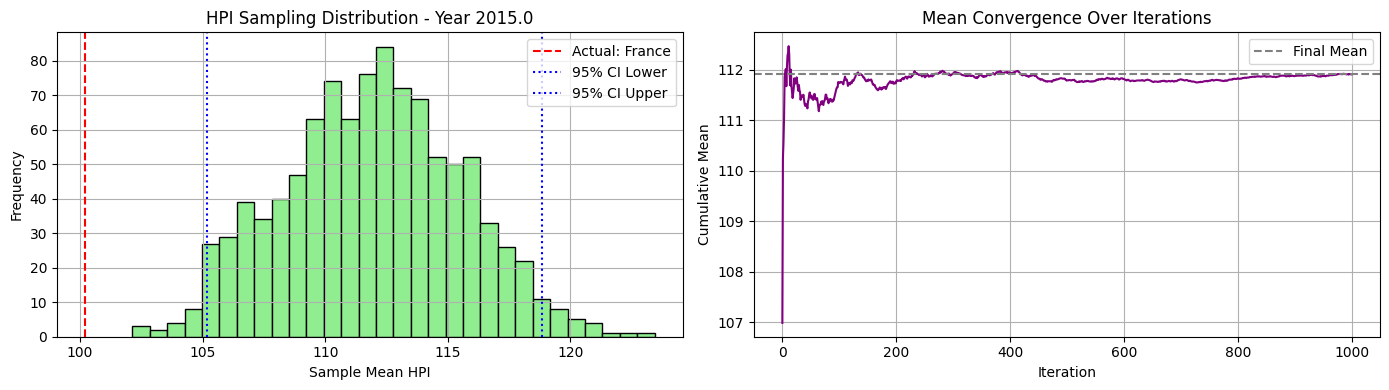


📅 Year 2016.0 - Available HPI values for sampling:
[112.52 125.93 142.4   88.1   94.43 139.95  96.44  88.1  142.4  142.4
 124.27]


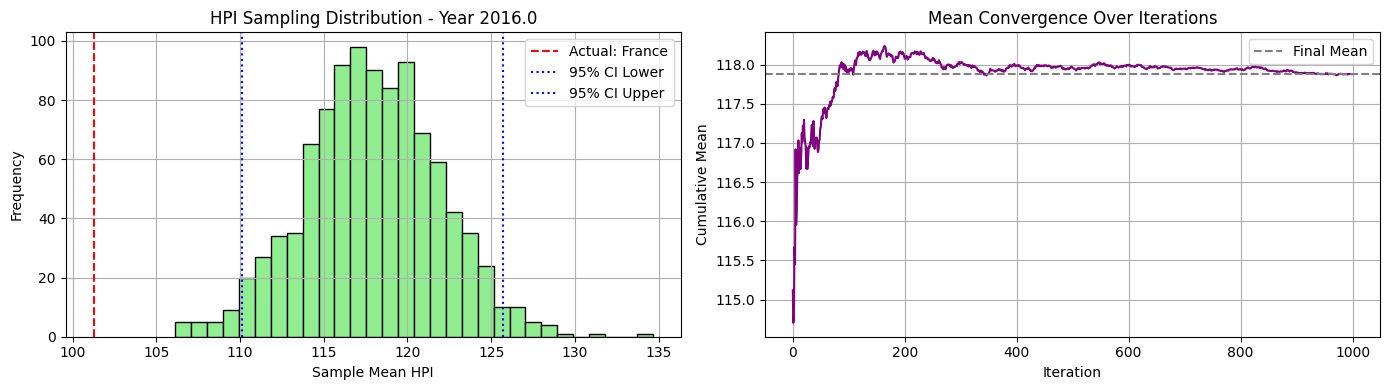


📅 Year 2017.0 - Available HPI values for sampling:
[125.7  133.62 147.08  94.84 102.06 146.91 100.16  94.84 147.08 146.48
 129.93]


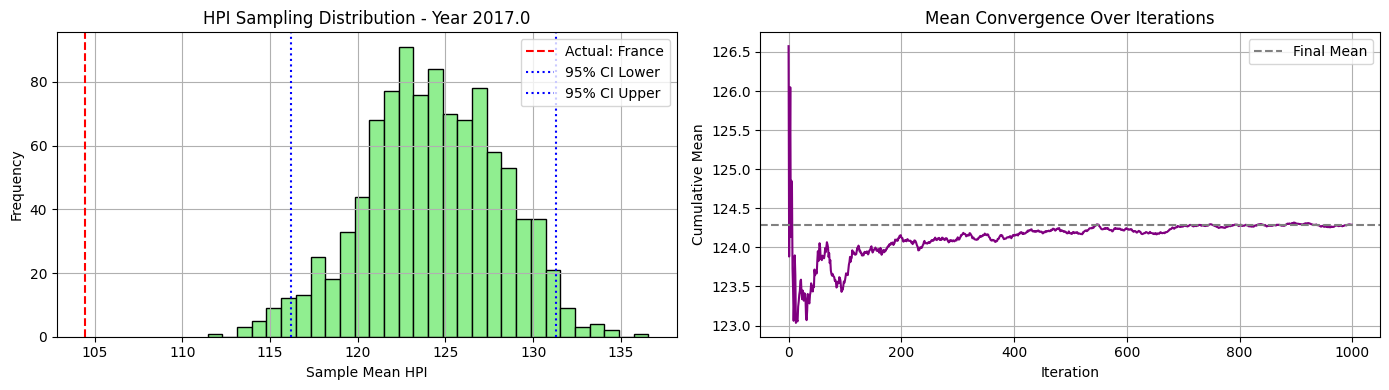


📅 Year 2018.0 - Available HPI values for sampling:
[136.52 142.52 157.24 100.59 111.57 149.04 106.75 100.59 154.6  153.9
 134.04]


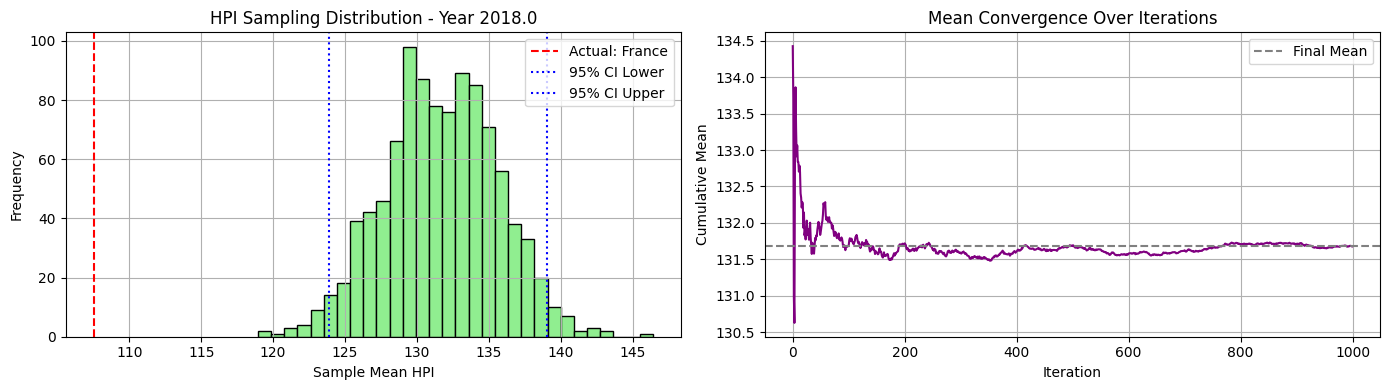


📅 Year 2019.0 - Available HPI values for sampling:
[149.02 150.75 164.68 109.64 119.62 152.73 116.01 109.64 158.44 155.1
 135.37]


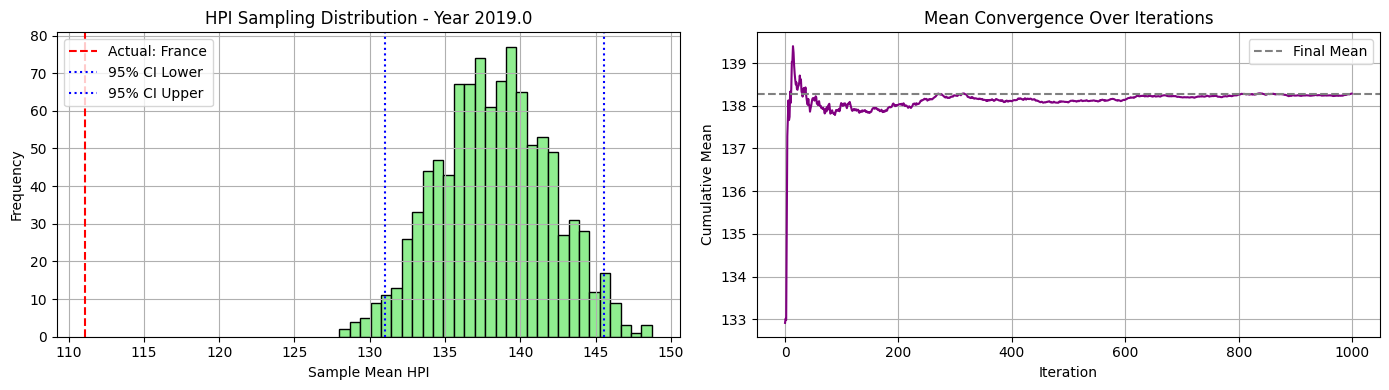


📅 Year 2020.0 - Available HPI values for sampling:
[161.56 162.48 181.42 112.49 129.21 159.24 128.18 112.49 165.09 160.6
 139.24]


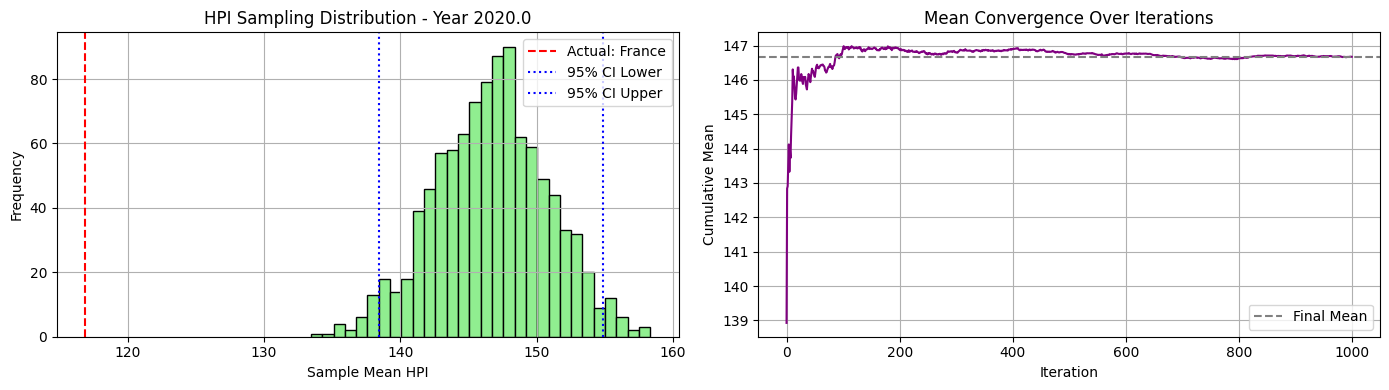


📅 Year 2021.0 - Available HPI values for sampling:
[193.46 181.28 201.18 117.62 147.93 175.91 139.92 117.62 181.79 164.23
 150.58]


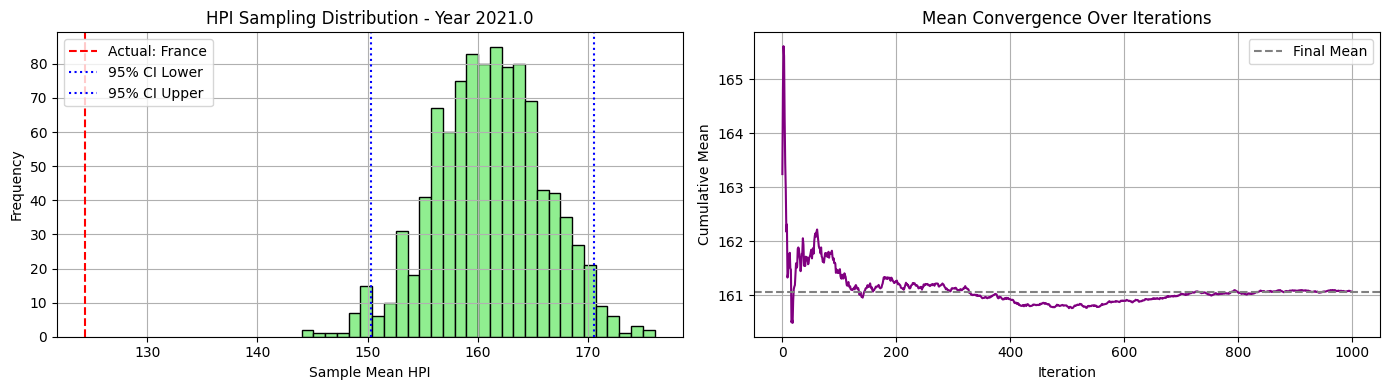


📅 Year 2022.0 - Available HPI values for sampling:
[226.15 190.42 231.64 118.98 167.57 185.13 156.43 118.98 188.27 169.16
 164.55]


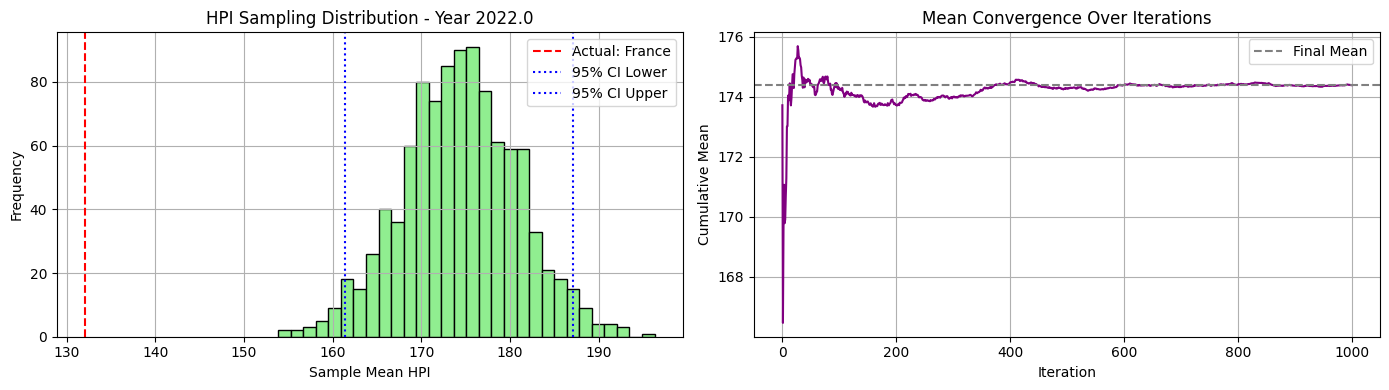


📅 Year 2023.0 - Available HPI values for sampling:
[222.4  174.25 237.56 112.27 164.36 184.12 170.23 112.27 178.36 174.79
 165.  ]


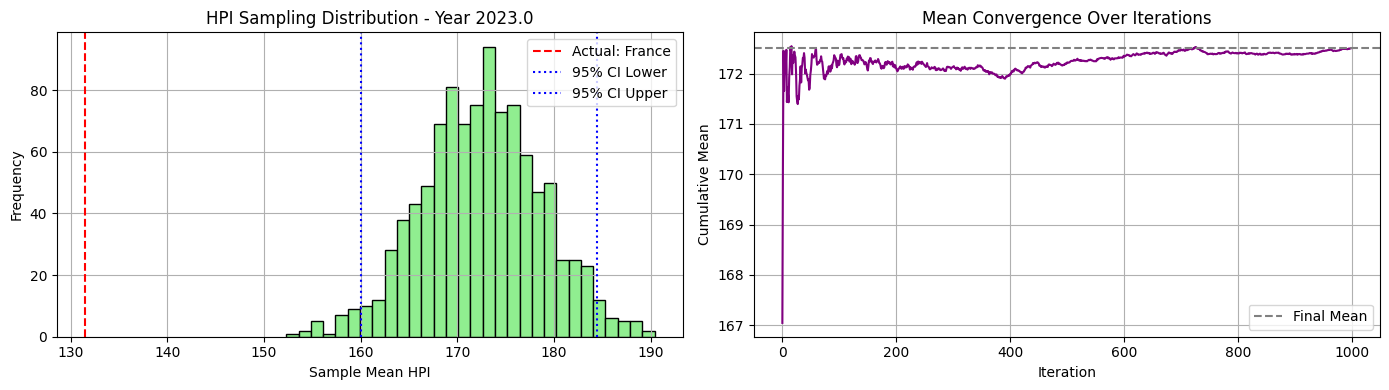


📅 Year 2024.0 - Available HPI values for sampling:
[233.42 171.5  247.54 119.1  177.7  189.05 195.72 119.1  178.49 178.06
 166.38]


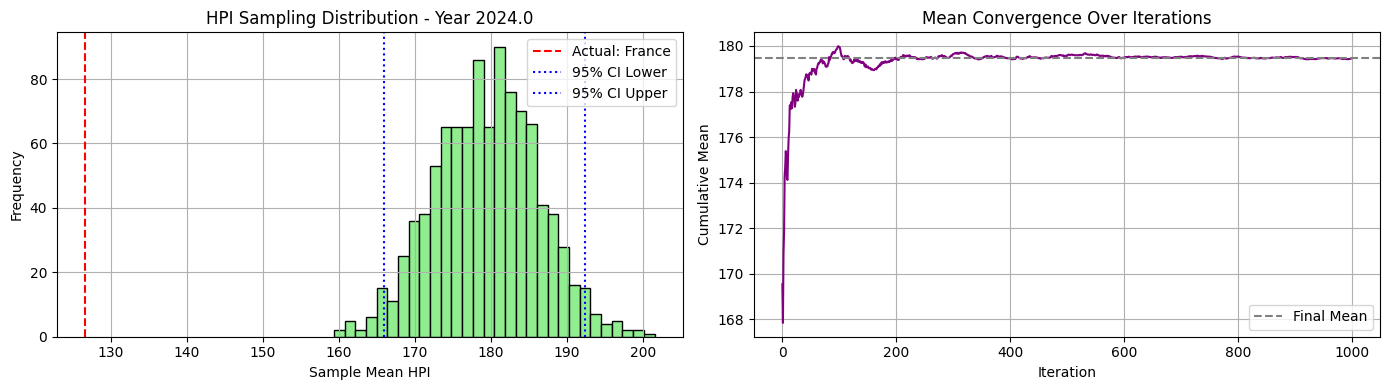

In [145]:
synthetic_c2_ni20_maxi500_5_win1_32_00, excluded_c2_ni20_maxi500_5_win1_32_00, actual_c2_ni20_maxi500_5_win1_32_00 = estimate_hpi_by_cluster_sampling(hpi_c2_ni20_maxi500_5_win1, clusters_c2_ni20_maxi500_5, cluster_id=0, seed=32)

🔍 Cluster 1 selected. Excluding country: Belgium
📊 Sampling from countries: ['Austria', 'Croatia', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Portugal', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


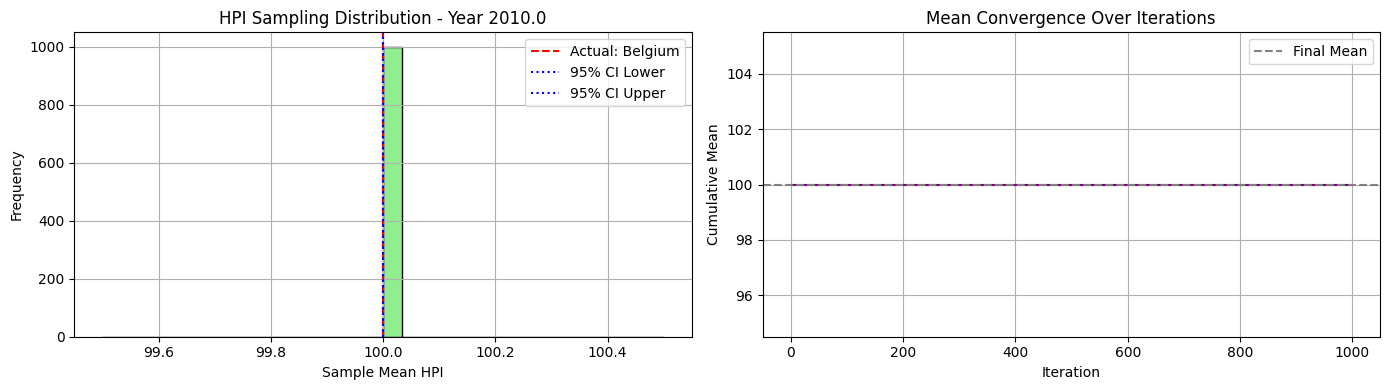


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 100.16 106.6  103.17  95.1   95.1  106.6  106.6  103.68  98.63
  95.1  102.72]


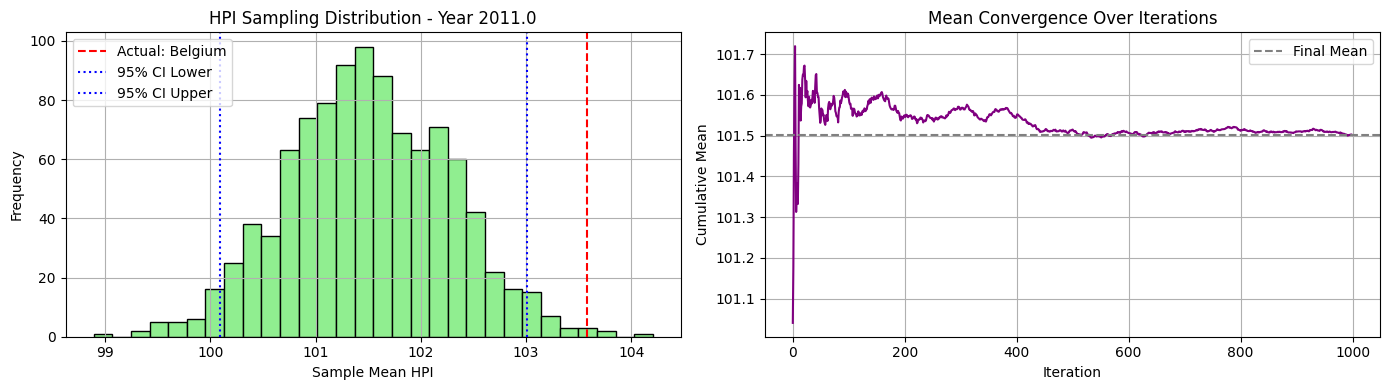


📅 Year 2012.0 - Available HPI values for sampling:
[113.71  98.62 113.71 105.64  88.37  88.37 113.71 106.36 108.03 101.62
  88.37  95.63]


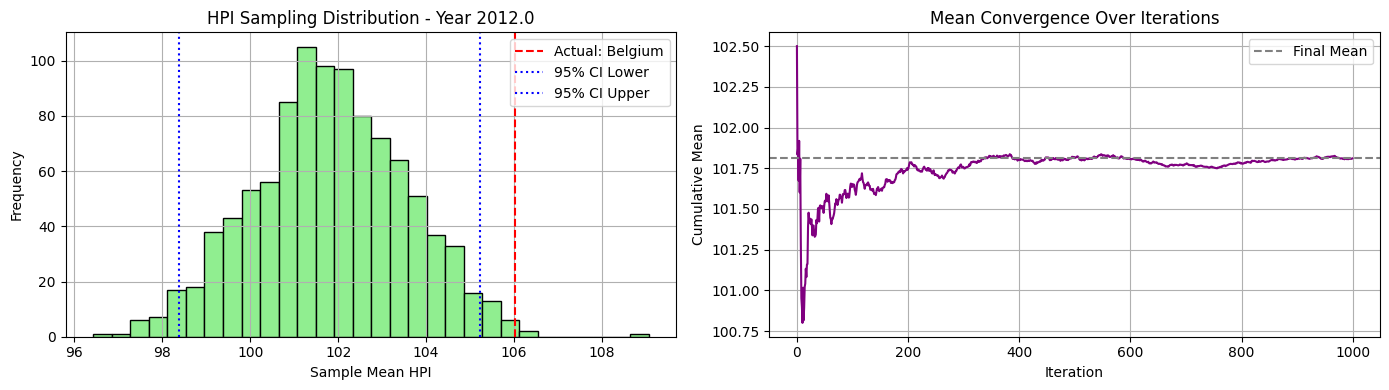


📅 Year 2013.0 - Available HPI values for sampling:
[119.98  94.7  119.98 106.87  85.95  85.95 119.98 107.65 113.42 101.21
  86.7   90.62]


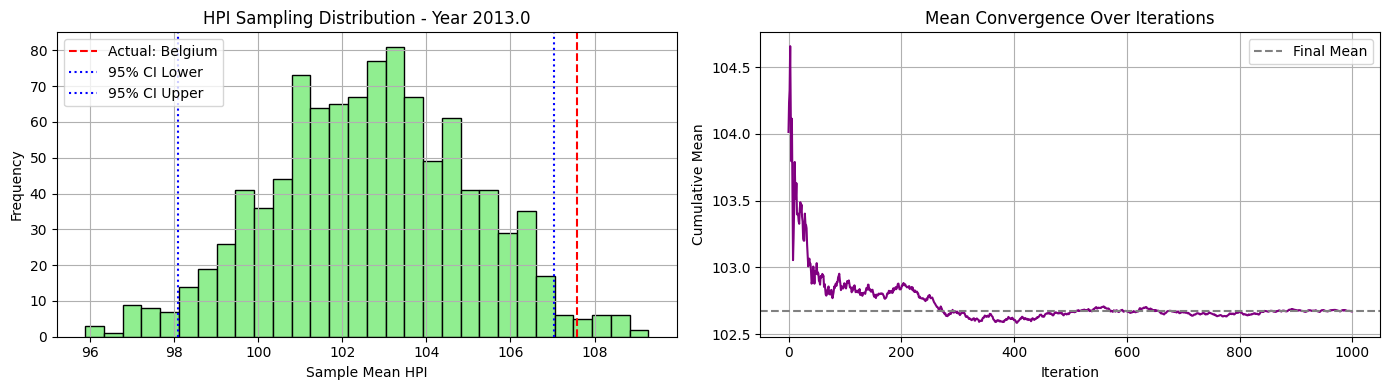


📅 Year 2014.0 - Available HPI values for sampling:
[126.79  93.19 127.07 106.5   84.66  84.66 127.07 114.57 118.39 103.79
  90.38  84.66]


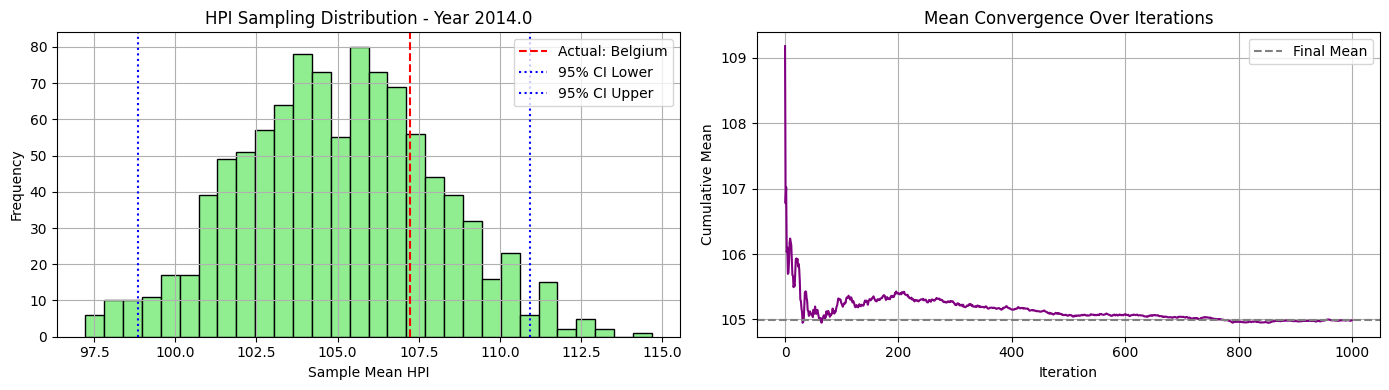


📅 Year 2015.0 - Available HPI values for sampling:
[132.06  90.54 135.2  106.5   85.32  94.36 124.46 118.76 124.78 109.83
  93.15  85.32]


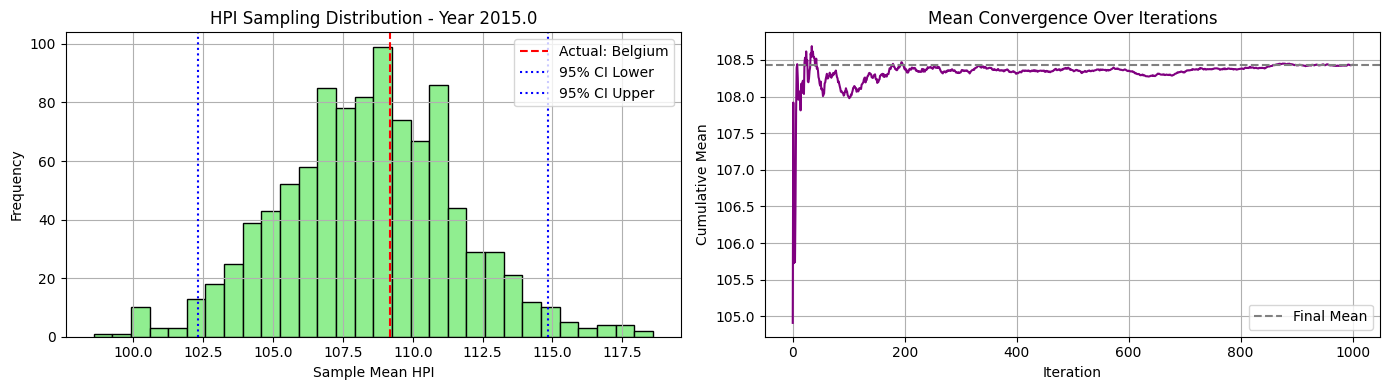


📅 Year 2016.0 - Available HPI values for sampling:
[141.76  91.33 142.4  107.86  88.1  101.42 135.02 125.16 132.28 115.82
  99.78  88.1 ]


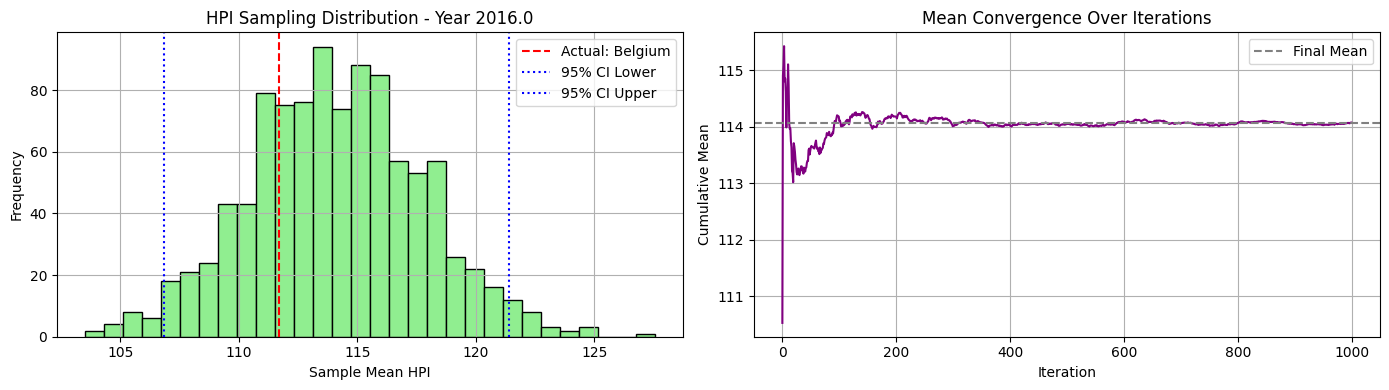


📅 Year 2017.0 - Available HPI values for sampling:
[147.08  94.84 147.08 109.02  94.84 112.44 146.87 136.34 139.69 121.94
 108.99  95.38]


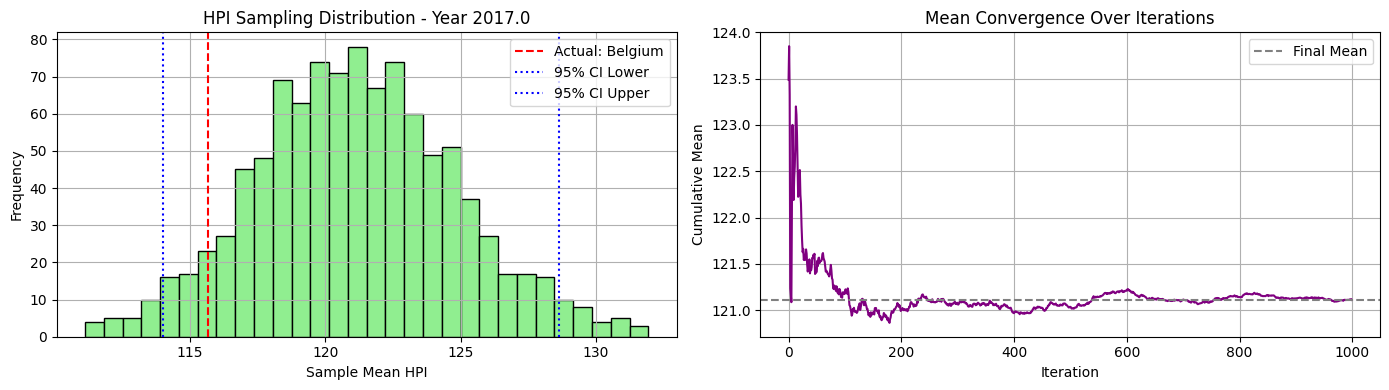


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 100.59 157.24 110.06 100.59 123.96 157.24 146.29 149.55 129.02
 120.19 103.7 ]


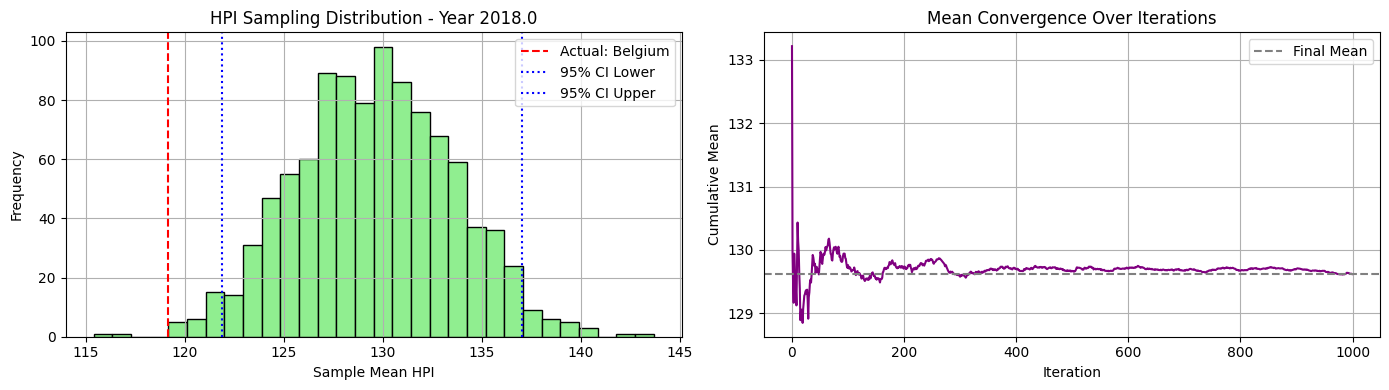


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 109.64 164.68 110.52 109.64 126.85 164.68 156.3  164.68 136.9
 132.16 110.65]


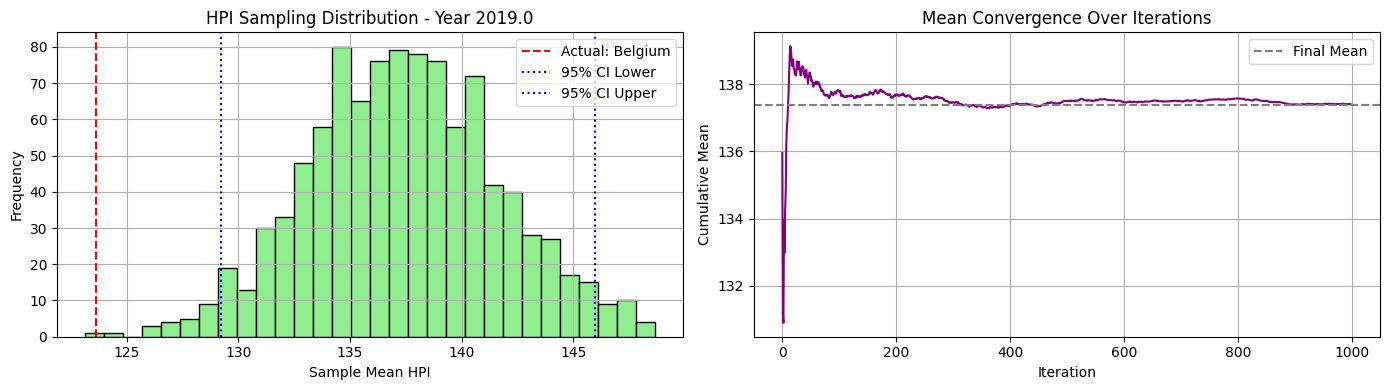


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 118.06 181.42 112.49 112.49 127.24 181.42 167.66 181.42 141.54
 143.75 115.74]


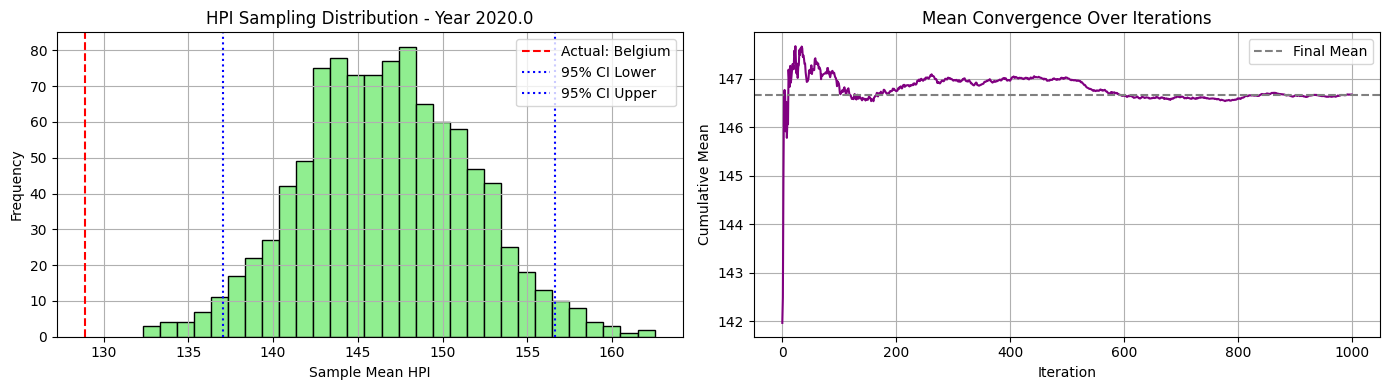


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 126.64 201.18 117.62 117.62 137.77 201.18 194.58 201.18 148.74
 157.27 129.1 ]


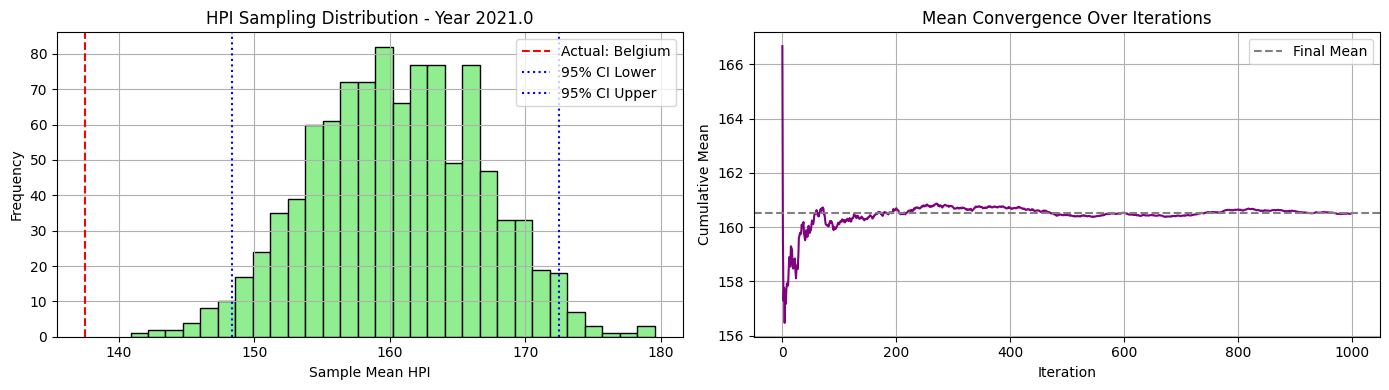


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.44 231.64 118.98 118.98 154.73 229.01 231.64 231.64 158.62
 177.14 148.16]


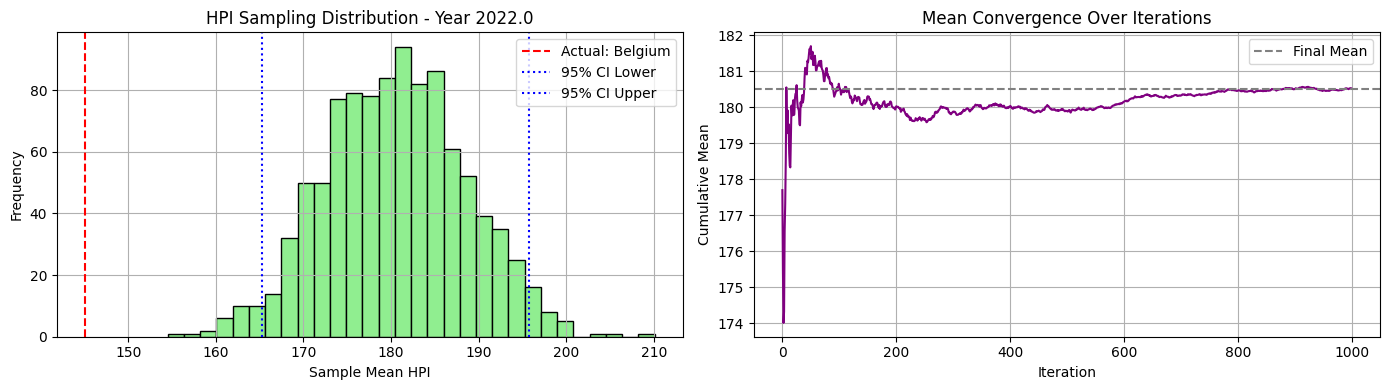


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 162.82 237.56 112.27 112.27 159.48 237.56 237.56 214.   168.5
 191.66 158.88]


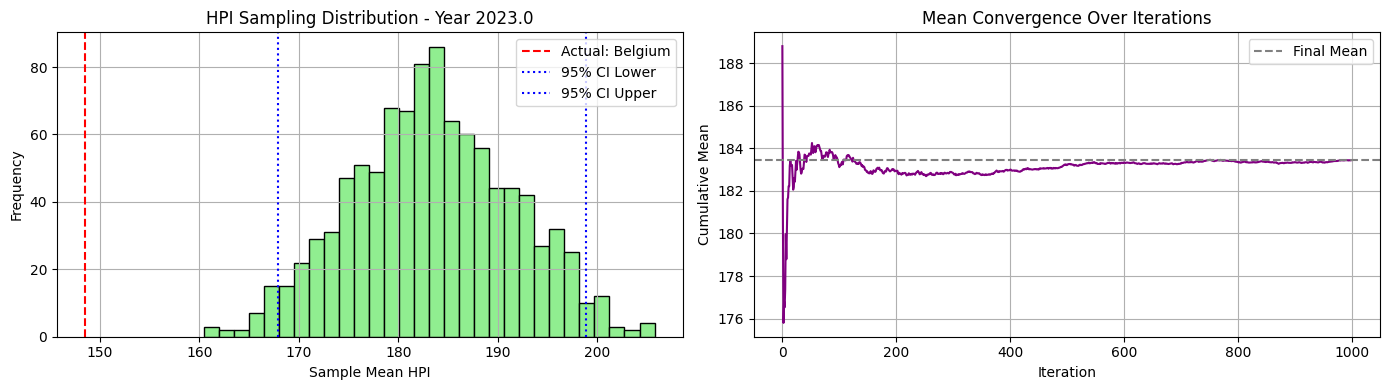


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 179.7  247.54 119.1  119.1  173.07 247.54 247.54 202.74 179.35
 209.06 170.56]


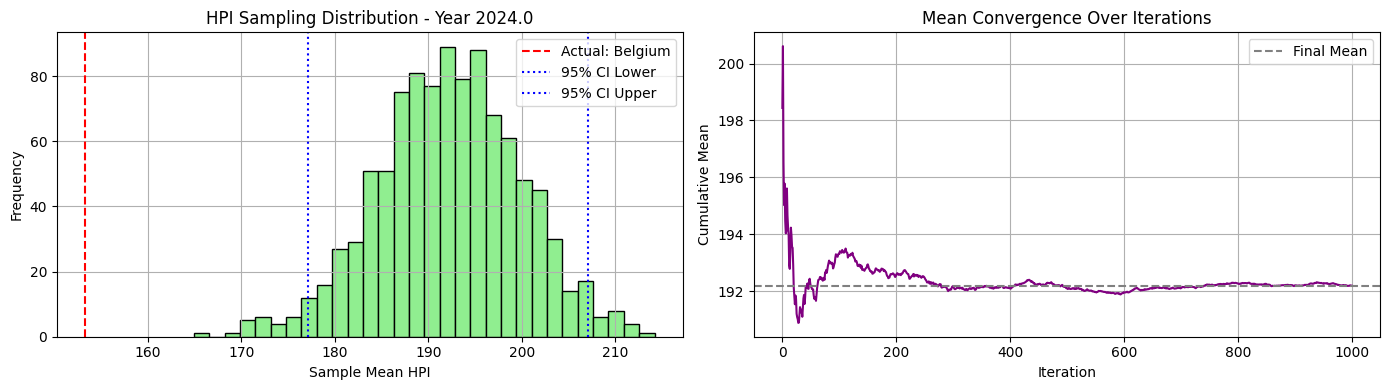

In [146]:
synthetic_c2_ni20_maxi500_5_win1_32_01, excluded_c2_ni20_maxi500_5_win1_32_01, actual_c2_ni20_maxi500_5_win1_32_01 = estimate_hpi_by_cluster_sampling(hpi_c2_ni20_maxi500_5_win1, clusters_c2_ni20_maxi500_5, cluster_id=1, seed=32)

### Sampling experiment with seed 46

🔍 Cluster 0 selected. Excluding country: France
📊 Sampling from countries: ['Czech Republic', 'Germany', 'Iceland', 'Italy', 'Netherlands', 'Norway', 'Poland', 'Spain', 'Sweden', 'Thailand', 'United Kingdom']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


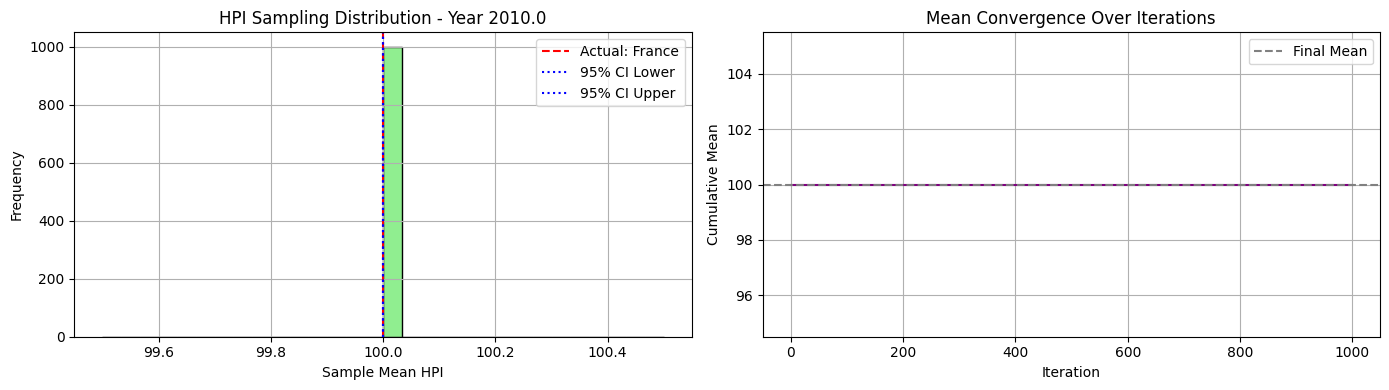


📅 Year 2011.0 - Available HPI values for sampling:
[100.02 102.42 105.5  101.36  98.02 106.6  100.08  95.1  102.58 104.26
  98.54]


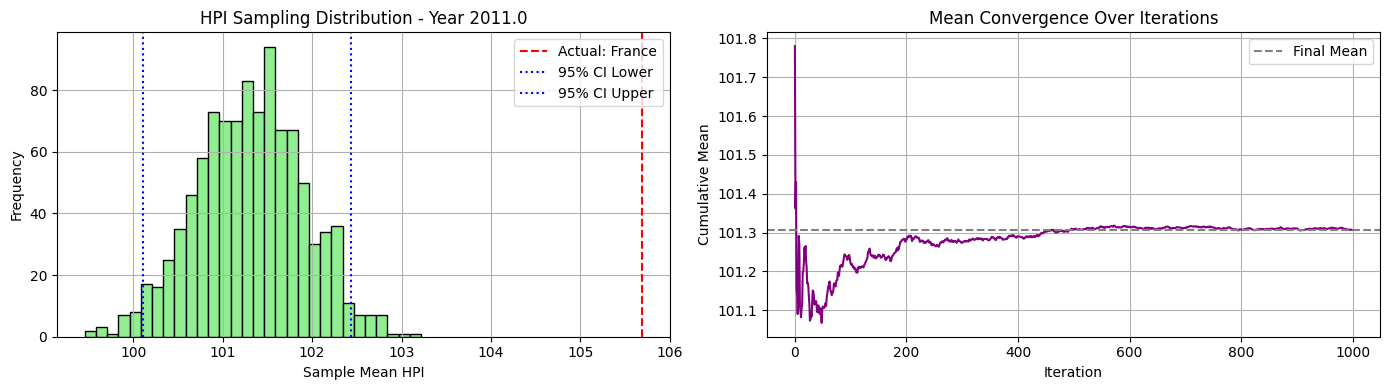


📅 Year 2012.0 - Available HPI values for sampling:
[ 98.56 105.48 112.38  98.77  91.44 113.71  96.58  88.37 103.86 107.63
  98.92]


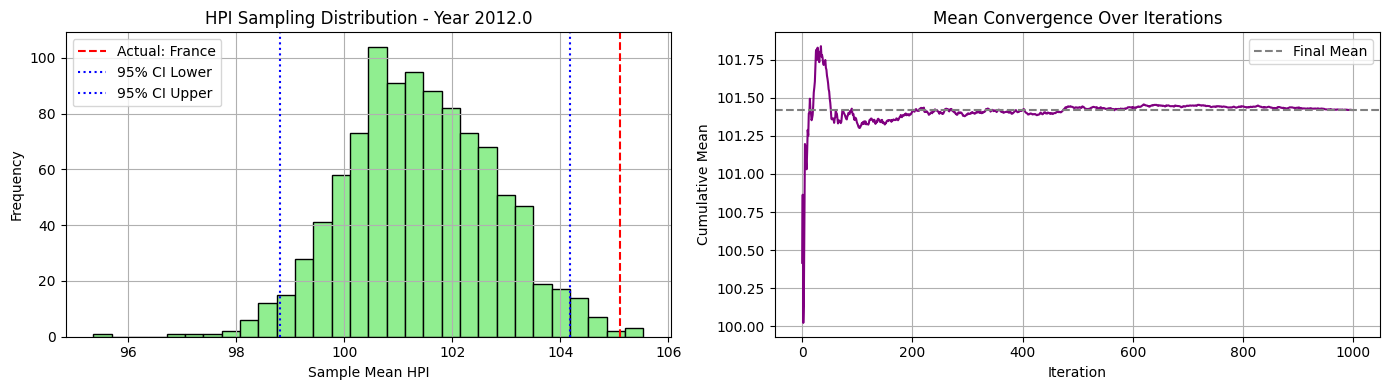


📅 Year 2013.0 - Available HPI values for sampling:
[ 98.58 108.68 119.18  92.38  85.95 119.98  92.35  85.95 109.22 115.99
 101.46]


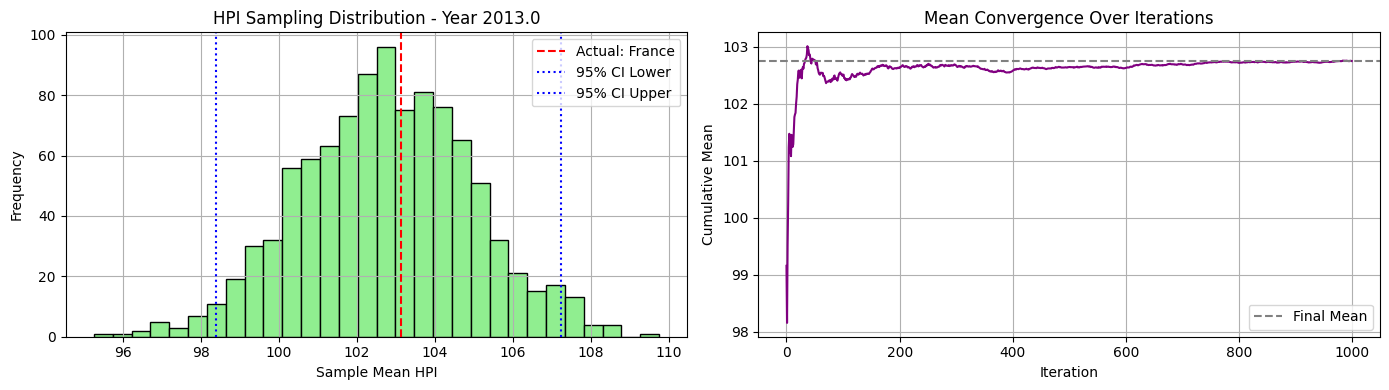


📅 Year 2014.0 - Available HPI values for sampling:
[101.   111.85 127.07  88.02  86.66 123.24  93.27  84.66 119.52 127.07
 109.6 ]


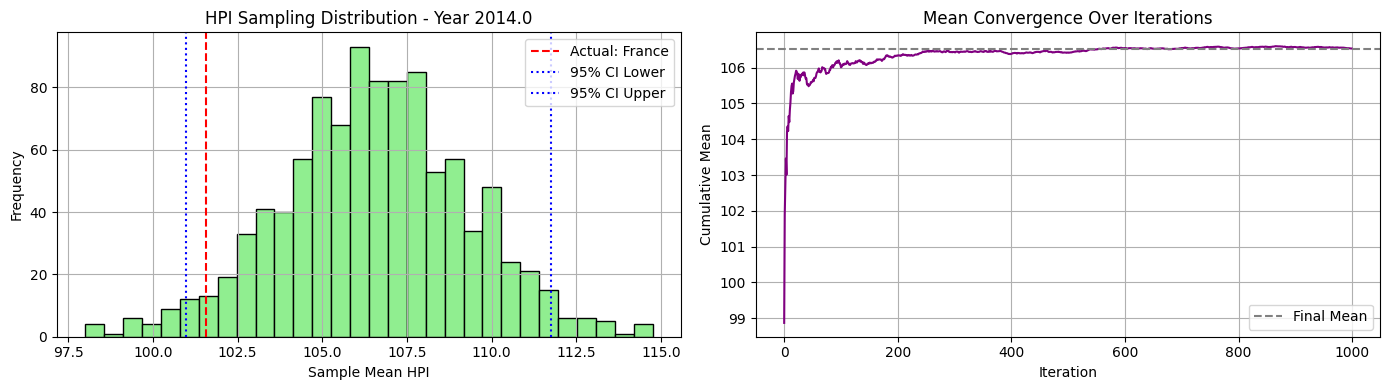


📅 Year 2015.0 - Available HPI values for sampling:
[105.01 117.12 135.2   85.32  89.69 130.76  94.69  85.32 135.2  135.2
 116.12]


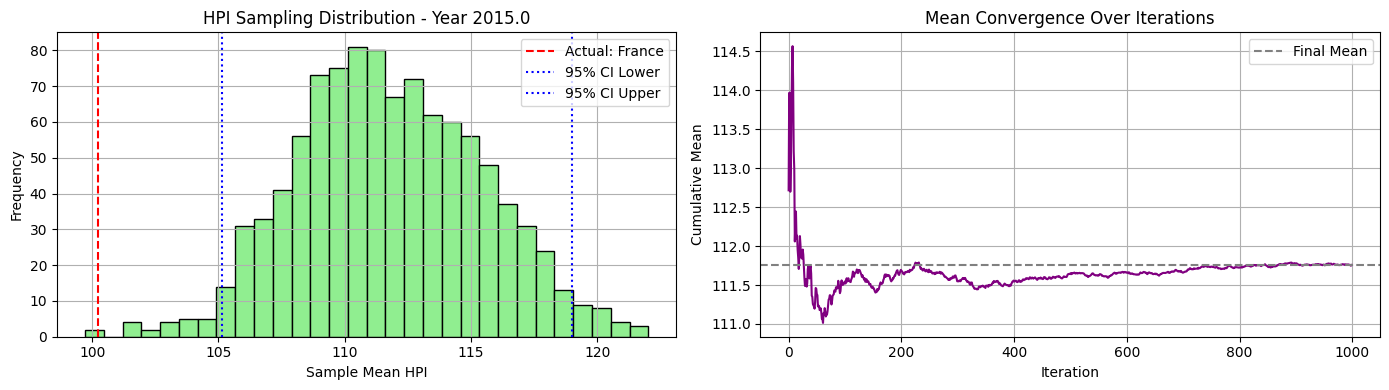


📅 Year 2016.0 - Available HPI values for sampling:
[112.52 125.93 142.4   88.1   94.43 139.95  96.44  88.1  142.4  142.4
 124.27]


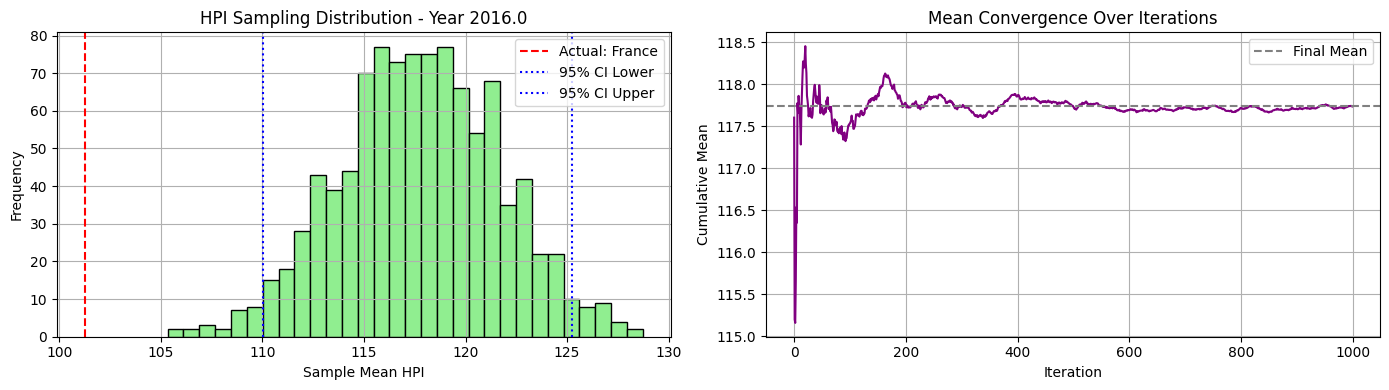


📅 Year 2017.0 - Available HPI values for sampling:
[125.7  133.62 147.08  94.84 102.06 146.91 100.16  94.84 147.08 146.48
 129.93]


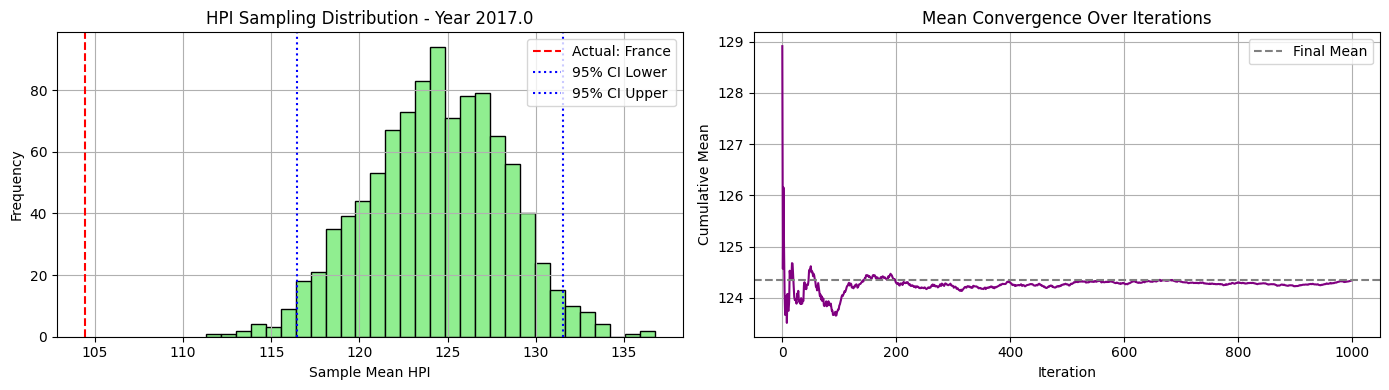


📅 Year 2018.0 - Available HPI values for sampling:
[136.52 142.52 157.24 100.59 111.57 149.04 106.75 100.59 154.6  153.9
 134.04]


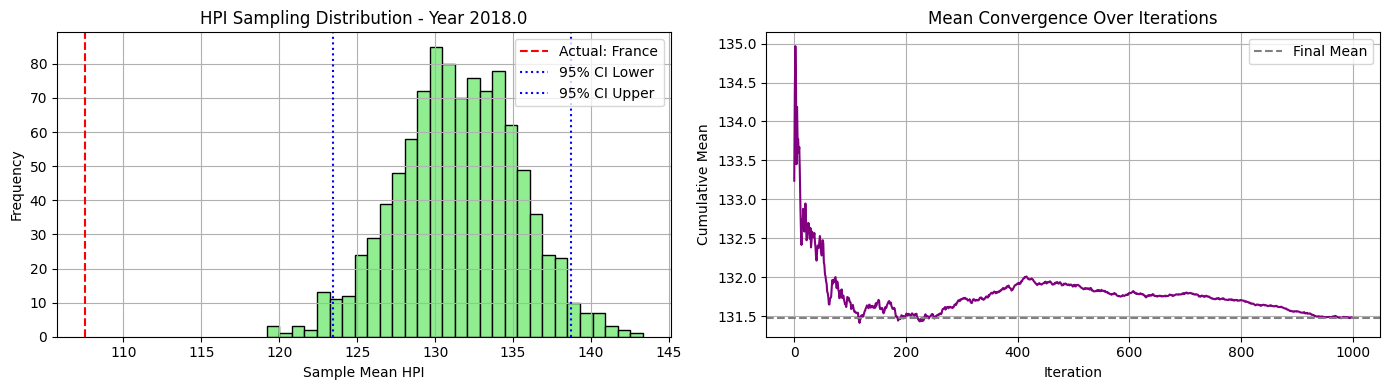


📅 Year 2019.0 - Available HPI values for sampling:
[149.02 150.75 164.68 109.64 119.62 152.73 116.01 109.64 158.44 155.1
 135.37]


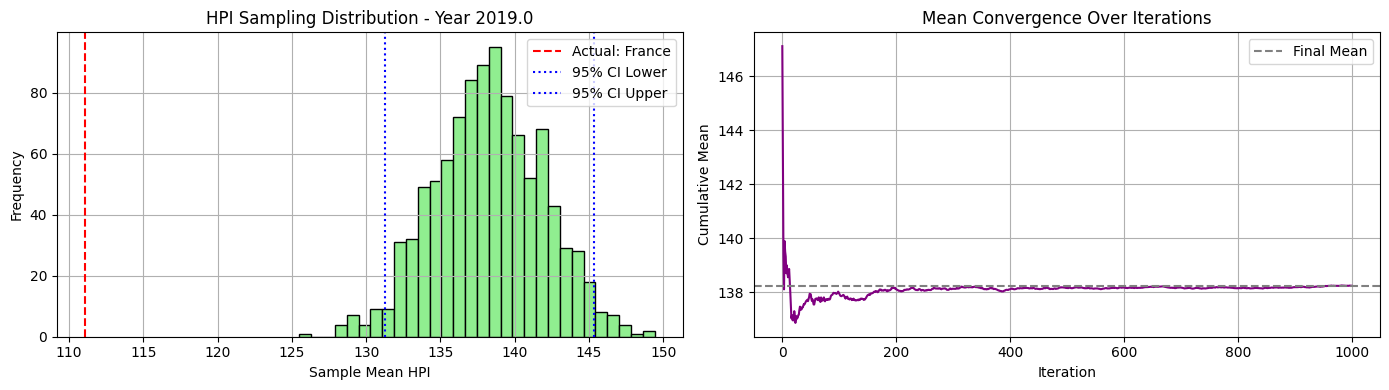


📅 Year 2020.0 - Available HPI values for sampling:
[161.56 162.48 181.42 112.49 129.21 159.24 128.18 112.49 165.09 160.6
 139.24]


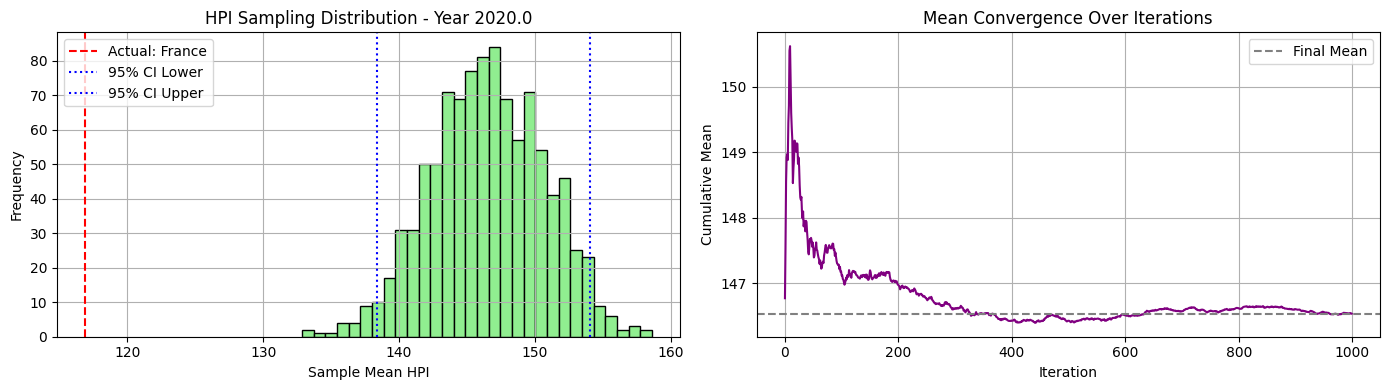


📅 Year 2021.0 - Available HPI values for sampling:
[193.46 181.28 201.18 117.62 147.93 175.91 139.92 117.62 181.79 164.23
 150.58]


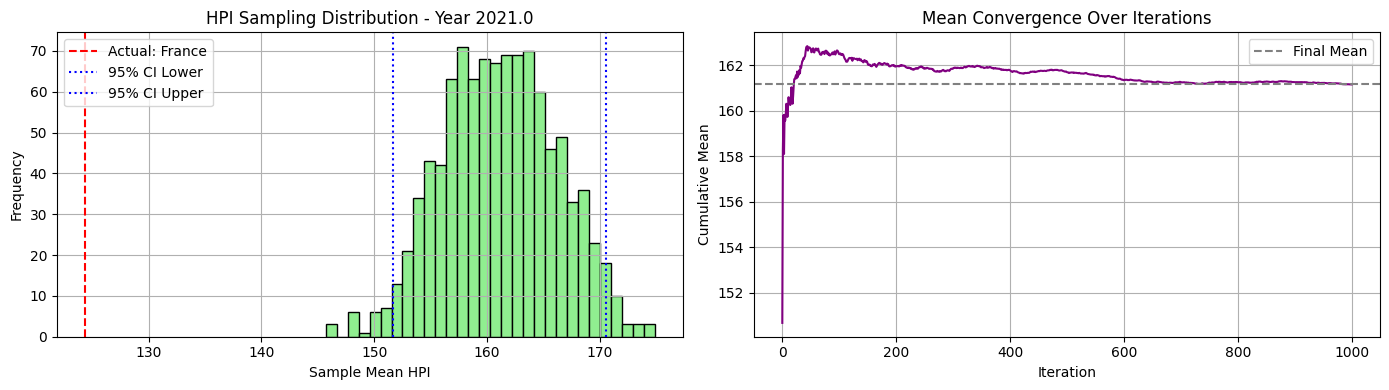


📅 Year 2022.0 - Available HPI values for sampling:
[226.15 190.42 231.64 118.98 167.57 185.13 156.43 118.98 188.27 169.16
 164.55]


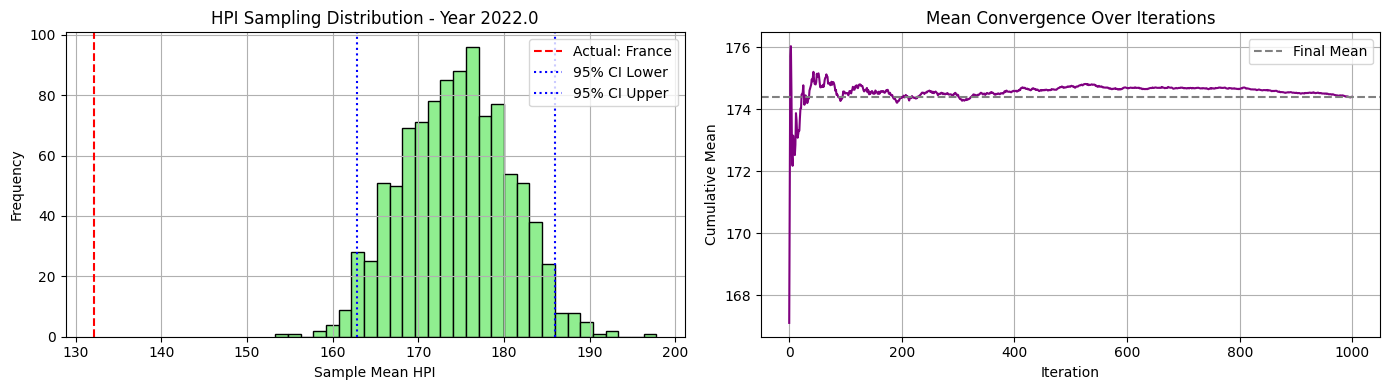


📅 Year 2023.0 - Available HPI values for sampling:
[222.4  174.25 237.56 112.27 164.36 184.12 170.23 112.27 178.36 174.79
 165.  ]


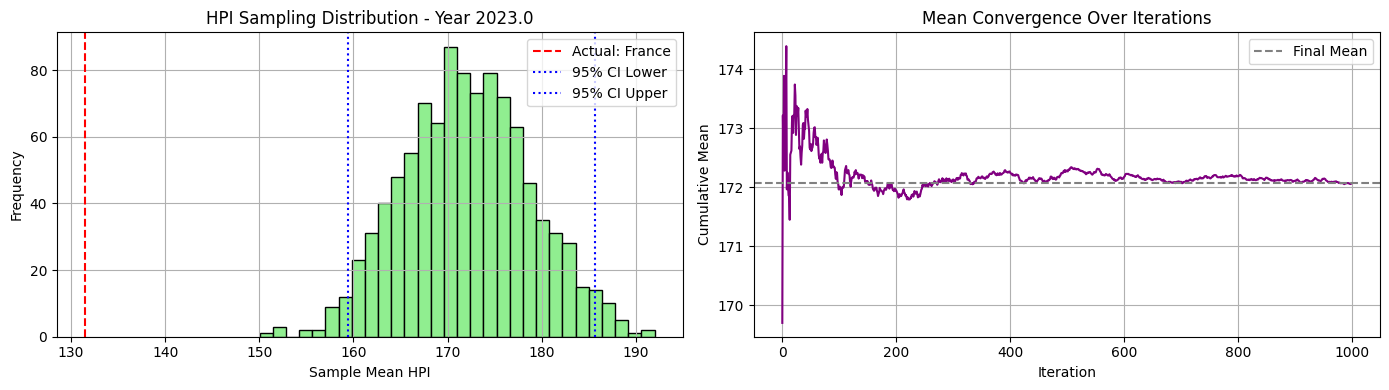


📅 Year 2024.0 - Available HPI values for sampling:
[233.42 171.5  247.54 119.1  177.7  189.05 195.72 119.1  178.49 178.06
 166.38]


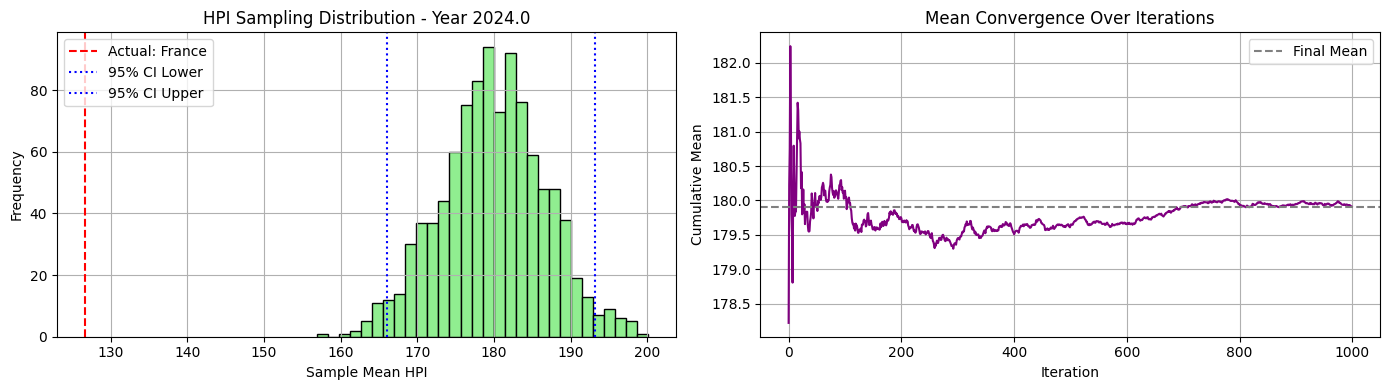

In [147]:
synthetic_c2_ni20_maxi500_5_win1_46_00, excluded_c2_ni20_maxi500_5_win1_46_00, actual_c2_ni20_maxi500_5_win1_46_00 = estimate_hpi_by_cluster_sampling(hpi_c2_ni20_maxi500_5_win1, clusters_c2_ni20_maxi500_5, cluster_id=0, seed=46)

🔍 Cluster 1 selected. Excluding country: Belgium
📊 Sampling from countries: ['Austria', 'Croatia', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Portugal', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


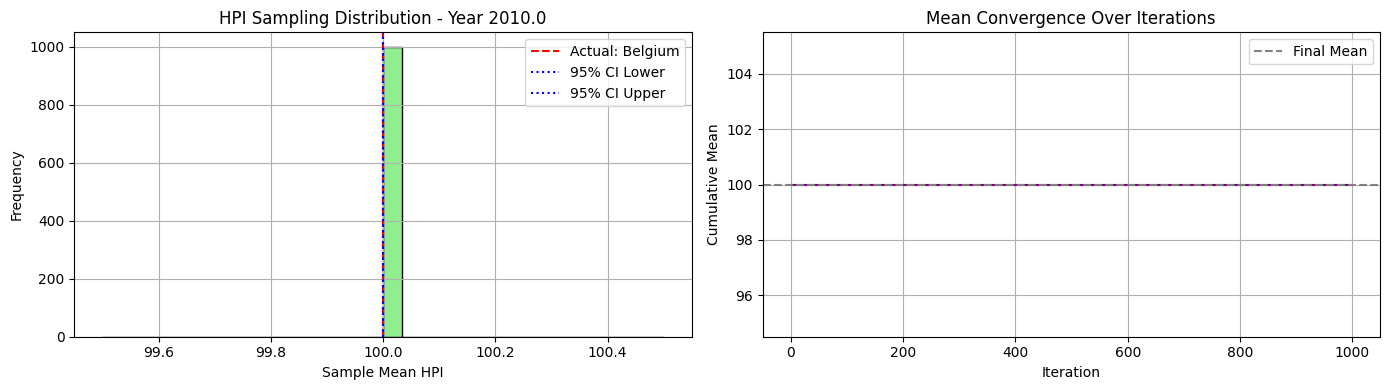


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 100.16 106.6  103.17  95.1   95.1  106.6  106.6  103.68  98.63
  95.1  102.72]


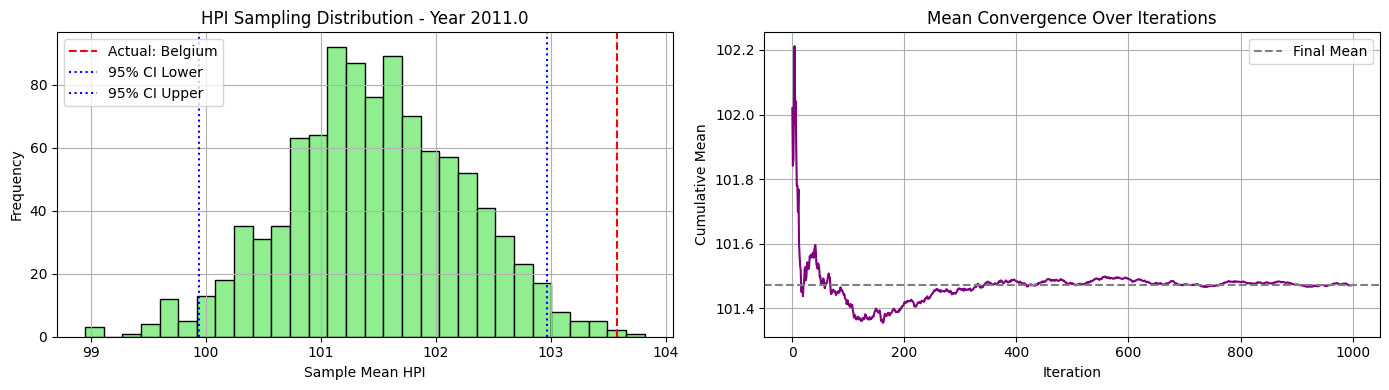


📅 Year 2012.0 - Available HPI values for sampling:
[113.71  98.62 113.71 105.64  88.37  88.37 113.71 106.36 108.03 101.62
  88.37  95.63]


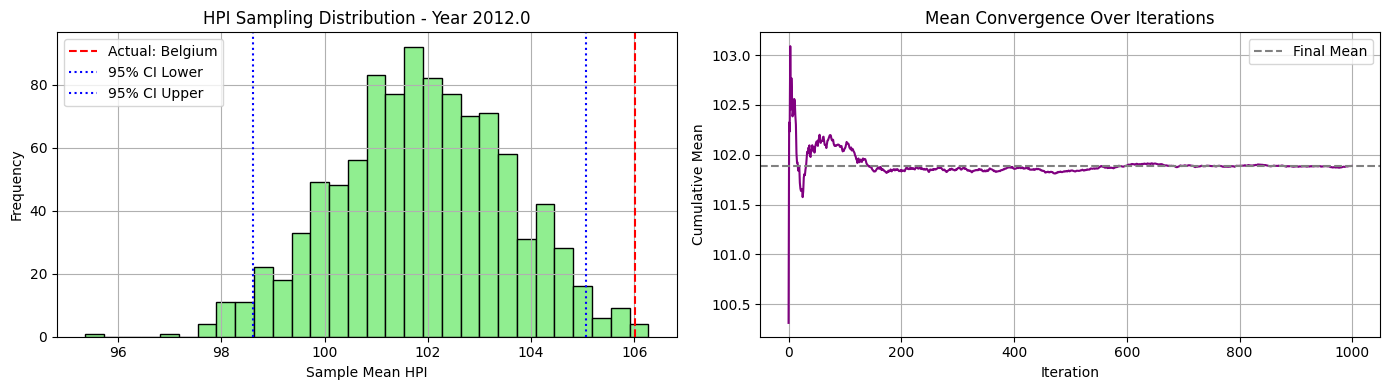


📅 Year 2013.0 - Available HPI values for sampling:
[119.98  94.7  119.98 106.87  85.95  85.95 119.98 107.65 113.42 101.21
  86.7   90.62]


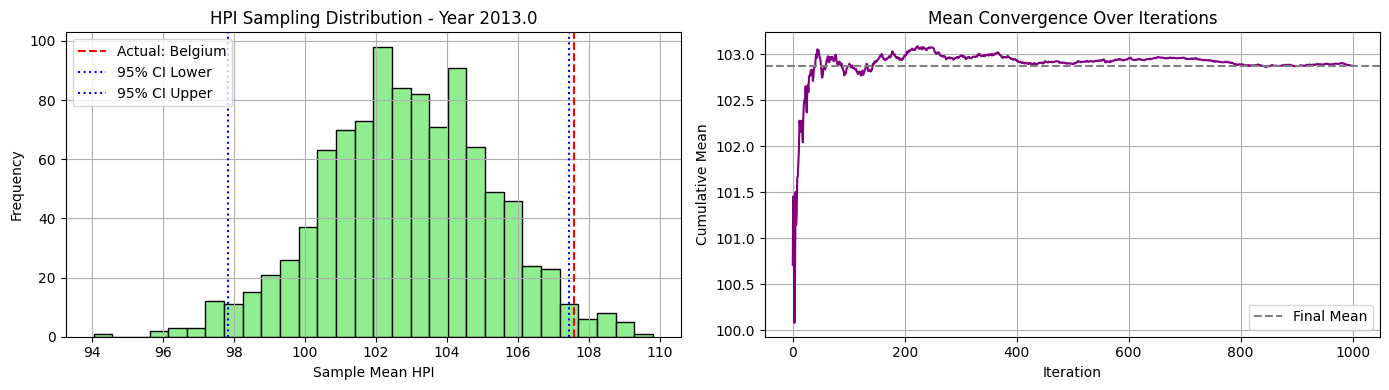


📅 Year 2014.0 - Available HPI values for sampling:
[126.79  93.19 127.07 106.5   84.66  84.66 127.07 114.57 118.39 103.79
  90.38  84.66]


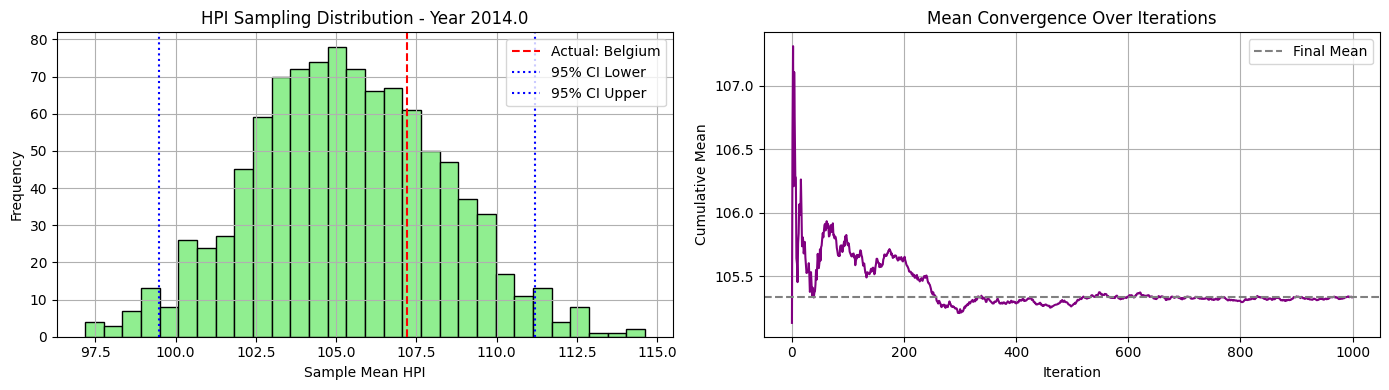


📅 Year 2015.0 - Available HPI values for sampling:
[132.06  90.54 135.2  106.5   85.32  94.36 124.46 118.76 124.78 109.83
  93.15  85.32]


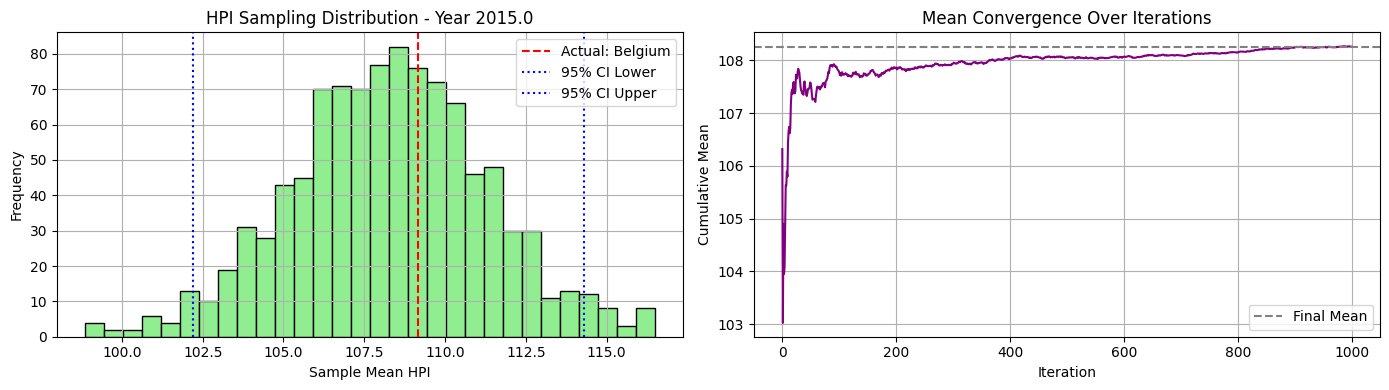


📅 Year 2016.0 - Available HPI values for sampling:
[141.76  91.33 142.4  107.86  88.1  101.42 135.02 125.16 132.28 115.82
  99.78  88.1 ]


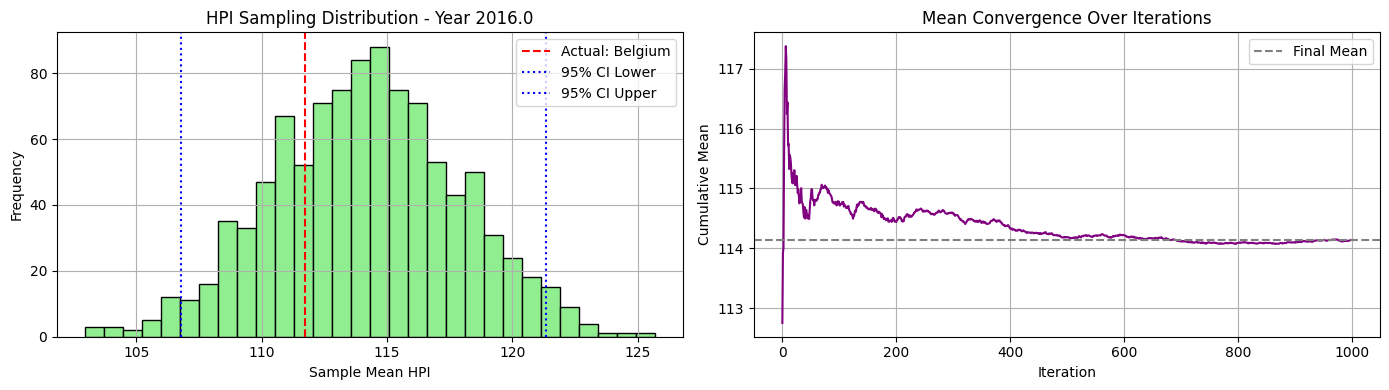


📅 Year 2017.0 - Available HPI values for sampling:
[147.08  94.84 147.08 109.02  94.84 112.44 146.87 136.34 139.69 121.94
 108.99  95.38]


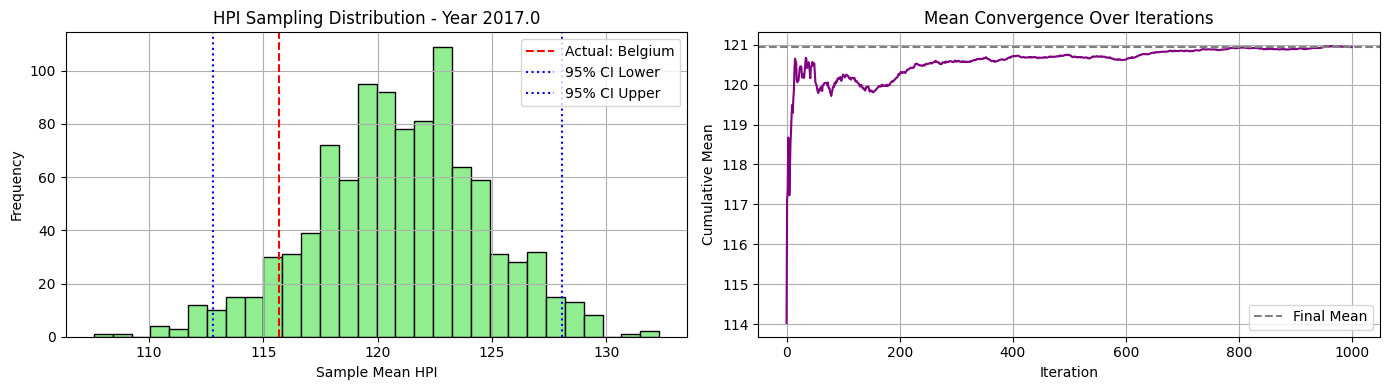


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 100.59 157.24 110.06 100.59 123.96 157.24 146.29 149.55 129.02
 120.19 103.7 ]


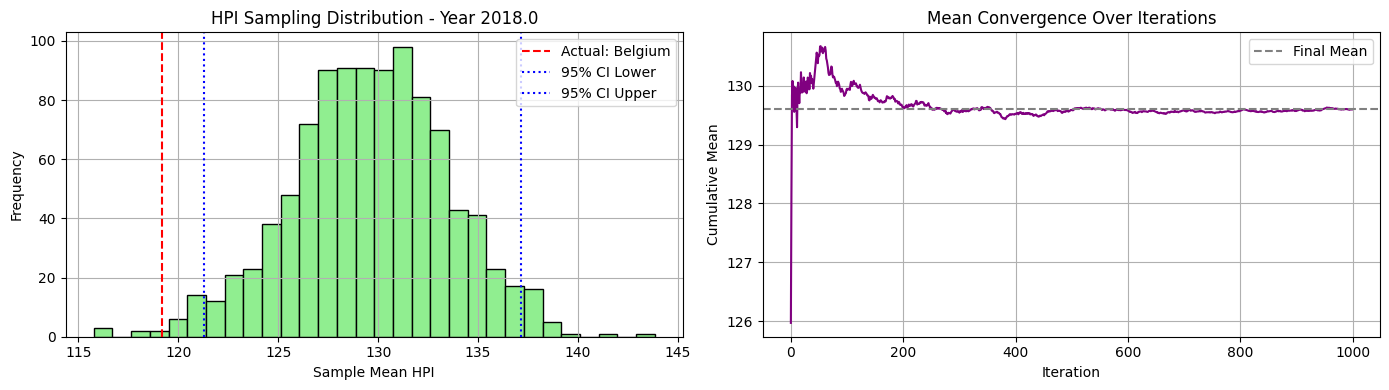


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 109.64 164.68 110.52 109.64 126.85 164.68 156.3  164.68 136.9
 132.16 110.65]


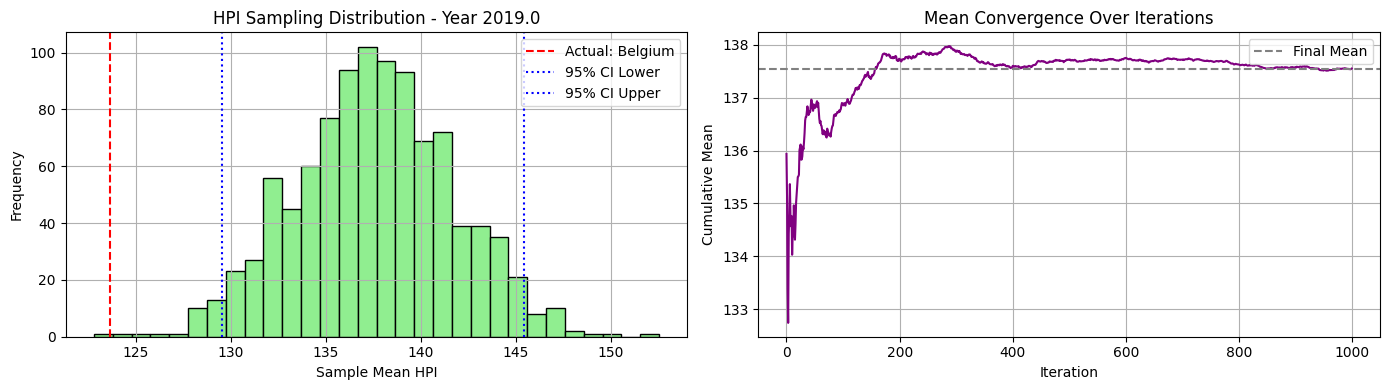


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 118.06 181.42 112.49 112.49 127.24 181.42 167.66 181.42 141.54
 143.75 115.74]


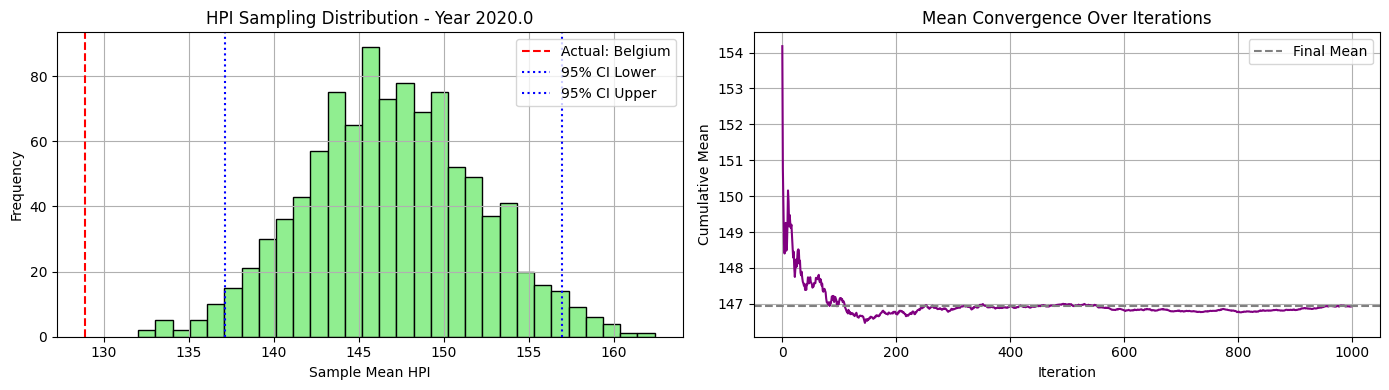


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 126.64 201.18 117.62 117.62 137.77 201.18 194.58 201.18 148.74
 157.27 129.1 ]


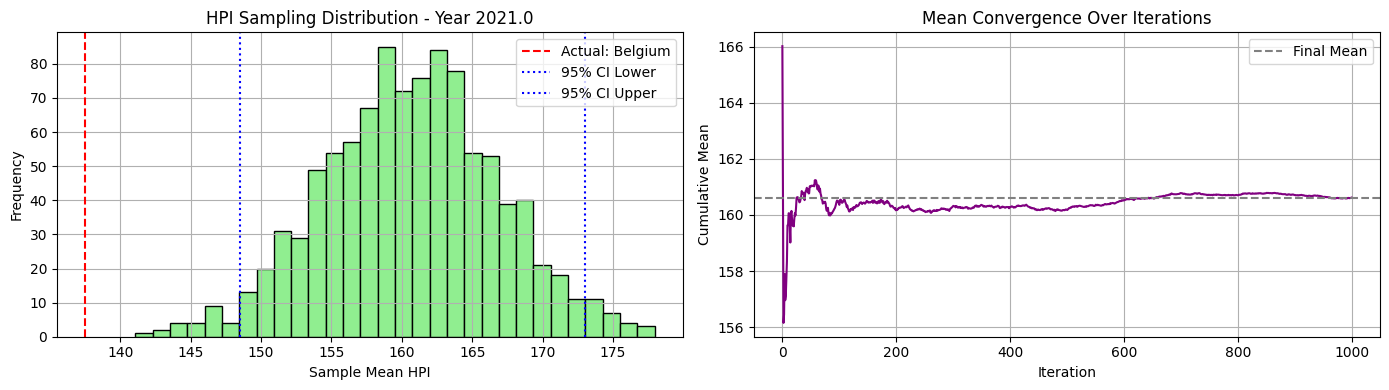


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.44 231.64 118.98 118.98 154.73 229.01 231.64 231.64 158.62
 177.14 148.16]


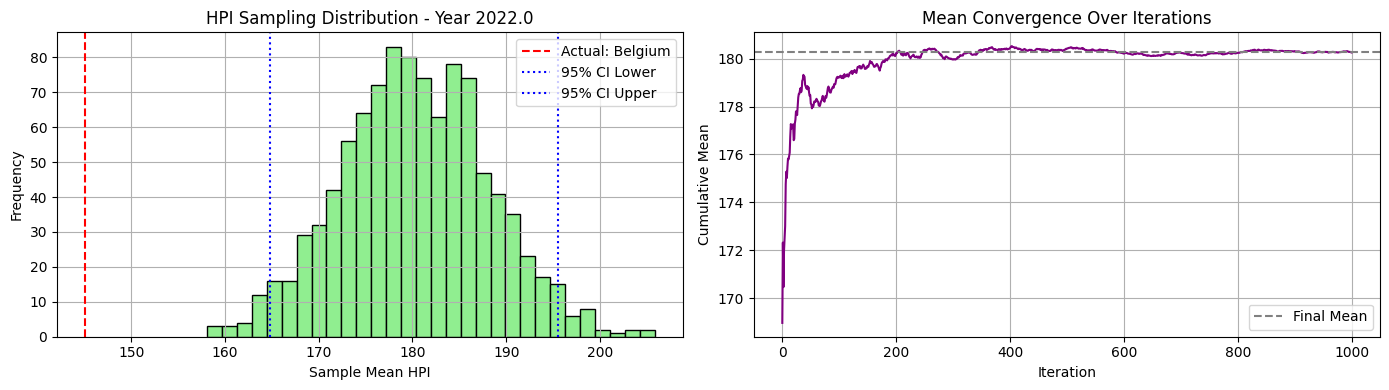


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 162.82 237.56 112.27 112.27 159.48 237.56 237.56 214.   168.5
 191.66 158.88]


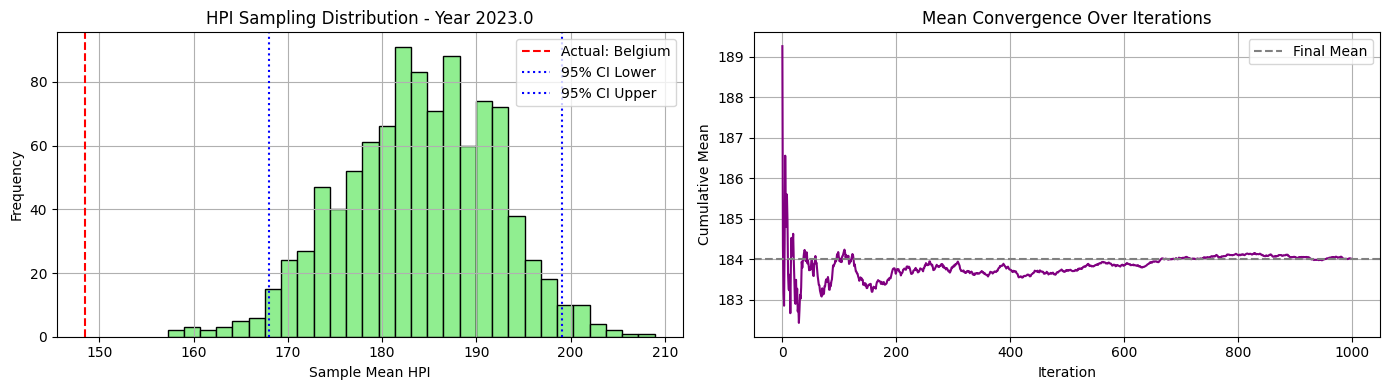


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 179.7  247.54 119.1  119.1  173.07 247.54 247.54 202.74 179.35
 209.06 170.56]


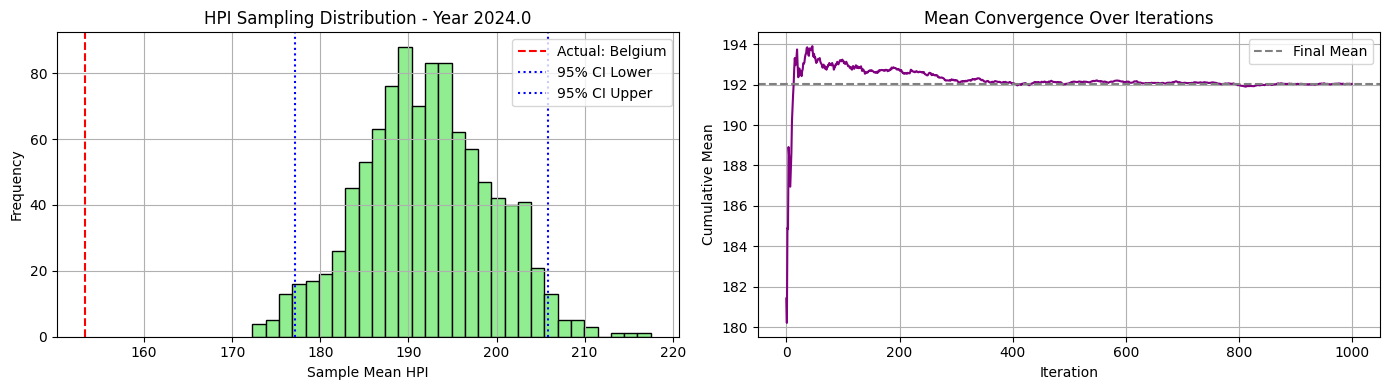

In [148]:
synthetic_c2_ni20_maxi500_5_win1_46_01, excluded_c2_ni20_maxi500_5_win1_46_01, actual_c2_ni20_maxi500_5_win1_46_01 = estimate_hpi_by_cluster_sampling(hpi_c2_ni20_maxi500_5_win1, clusters_c2_ni20_maxi500_5, cluster_id=1, seed=46)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [149]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [150]:
from sklearn.metrics import silhouette_score

In [151]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [152]:
import re

def evaluate_all_seeds(synthetic_groups, actual_groups):
    """
    Evaluates multiple sets of synthetic vs. actual HPI dictionaries,
    and stores error metrics in a dictionary keyed by seed number.

    Parameters:
    - synthetic_groups: dict with keys like 'synthetic_42' and values as lists of synthetic dicts
    - actual_groups: dict with keys like 'actual_42' and values as lists of actual dicts

    Returns:
    - metrics_by_seed: dict with seed as key and {'mse': ..., 'mae': ...} as value
    """
    metrics_by_seed = {}

    for synthetic_key in synthetic_groups:
        # Extract seed number from the synthetic key
        match = re.search(r'_(\d+)$', synthetic_key)
        if not match:
            raise ValueError(f"Could not extract seed from key: {synthetic_key}")
        
        seed = int(match.group(1))
        actual_key = f'actual_{seed}'  # construct matching key for actual_groups

        if actual_key not in actual_groups:
            raise KeyError(f"Missing key in actual_groups: {actual_key}")

        synthetic_dicts = synthetic_groups[synthetic_key]
        actual_dicts = actual_groups[actual_key]

        mse, mae = compute_global_mse_mae(synthetic_dicts, actual_dicts)
        metrics_by_seed[seed] = {'mse': mse, 'mae': mae}

    return metrics_by_seed

In [153]:
def summarize_error_metrics(metrics_by_seed):
    """
    Computes the mean and median of MSE and MAE values across multiple seeds.

    Parameters:
    - metrics_by_seed: dictionary with seed as key and {'mse': ..., 'mae': ...} as value

    Returns:
    - summary: dictionary with keys 'mse_mean', 'mse_median', 'mae_mean', 'mae_median'
    """
    mse_values = [metrics['mse'] for metrics in metrics_by_seed.values()]
    mae_values = [metrics['mae'] for metrics in metrics_by_seed.values()]

    summary = {
        'mse_mean': np.mean(mse_values),
        'mse_median': np.median(mse_values),
        'mae_mean': np.mean(mae_values),
        'mae_median': np.median(mae_values)
    }

    return summary

In [154]:
a = [synthetic_c2_ni20_maxi500_5_win1_23_00, synthetic_c2_ni20_maxi500_5_win1_23_01]
b = [actual_c2_ni20_maxi500_5_win1_23_00, actual_c2_ni20_maxi500_5_win1_23_01]

c = [synthetic_c2_ni20_maxi500_5_win1_32_00, synthetic_c2_ni20_maxi500_5_win1_32_01]
d = [actual_c2_ni20_maxi500_5_win1_32_00, actual_c2_ni20_maxi500_5_win1_32_01]

e = [synthetic_c2_ni20_maxi500_5_win1_46_00, synthetic_c2_ni20_maxi500_5_win1_46_01]
f = [actual_c2_ni20_maxi500_5_win1_46_00, actual_c2_ni20_maxi500_5_win1_46_01]

In [156]:
synth_c2_ni20_maxi500_5_win1 = {
    'synthetic_32': a,
    'synthetic_43': c,
    'synthetic_52': e
}

actual_c2_ni20_maxi500_5_win1 = {
    'actual_32': b,
    'actual_43': d,
    'actual_52': f
}

In [157]:
results_c2_ni20_maxi500_5_win1 = evaluate_all_seeds(synth_c2_ni10_maxi100, actual_c2_ni10_maxi100)

In [158]:
for seed, metrics in results_c2_ni20_maxi500_5_win1.items():
    print(f"🔢 Seed {seed} → MSE: {metrics['mse']:.4f}, MAE: {metrics['mae']:.4f}")

🔢 Seed 32 → MSE: 912.5551, MAE: 25.4106
🔢 Seed 43 → MSE: 529.5738, MAE: 17.0579
🔢 Seed 52 → MSE: 530.1418, MAE: 17.0404


In [159]:
summary_c2_ni20_maxi500_5_win1 = summarize_error_metrics(results_c2_ni20_maxi500_5_win1)

In [161]:
print("📈 Error Summary Across Seeds:")
print(f"Mean MSE: {summary_c2_ni20_maxi500_5_win1['mse_mean']:.4f}")
print(f"Median MSE: {summary_c2_ni20_maxi500_5_win1['mse_median']:.4f}")
print(f"Mean MAE: {summary_c2_ni20_maxi500_5_win1['mae_mean']:.4f}")
print(f"Median MAE: {summary_c2_ni20_maxi500_5_win1['mae_median']:.4f}")

📈 Error Summary Across Seeds:
Mean MSE: 657.4236
Median MSE: 530.1418
Mean MAE: 19.8363
Median MAE: 17.0579


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [1]:
import pandas as pd

In [162]:
from datetime import datetime

In [2]:
log_df = pd.read_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [164]:
pd.set_option('display.max_columns', None)

In [4]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook
0,baseline_kmeans_random,2025-09-07 18:52,None,52,KMeans,3,random,10.0,100.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1280.833748,27.767857,None
1,baseline_continent_clusters,2025-09-07 22:44,None,52,continent based,4,None,NaN,NaN,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1652.241439,27.672956,None
2,baseline_kmeans_plusplus,2025-09-09 20:56,None,52,KMeans,3,k-means++,10.0,100.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507,None
3,kmeans_plusplus_without_outliers,2025-09-10 16:20,None,52,KMeans,3,k-means++,10.0,100.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,566.926791,19.297330,None
4,kmeans_plusplus_elbow_silhouette_5,2025-09-10 19:38:00,None,52,KMeans,5,k-means++,10.0,100.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1889.093940,29.773409,None
5,kmeans_plusplus_c2_ni10_maxi100,2025-09-11 17:54,None,52,KMeans,2,k-means++,10.0,100.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,253.672048,12.191757,None
6,kmeans_plusplus_c2_ni18_maxi300,2025-09-11 17:54,None,52,KMeans,2,k-means++,18.0,300.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,208.801705,10.990371,None
7,kmeans_plusplus_c2_ni20_maxi500,2025-09-11 17:54,None,52,KMeans,2,k-means++,20.0,500.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,208.801705,10.990371,None
8,kmeans_plusplus_c3_ni20_maxi500,2025-09-11 17:54,None,52,KMeans,3,k-means++,20.0,500.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,1268.379506,25.588507,None
9,kmeans_plusplus_c2_ni10_maxi100_no,2025-09-11 19:48,None,52,KMeans,2,k-means++,10.0,100.0,42,...,True,False,"Winsorization, rounding",Winsorization,boostrap,None,1.0,881.604066,24.848810,None


In [169]:
new_entry_c2_ni20_maxi500_5_win1 = {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_5_27deleted_win1_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_c2_ni20_maxi500,
    'transformations_clustering': 'RobustScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'Winsorization x5',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'mse_score': summary_c2_ni20_maxi500_5_win1['mse_mean'],
    'mae_score': summary_c2_ni20_maxi500_5_win1['mae_mean'],
    'sampling_seed': (23,32,46),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 26
}

In [171]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry_c2_ni20_maxi500_5_win1])], ignore_index=True)

In [5]:
log_df.loc[24, "source_notebook"] = "hypothesis_test_17.ipynb"

In [6]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [7]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')